**Archival record of an executed notebook (public release).** Absolute local paths were replaced by `<PROJECT_ROOT>` / `<USER_HOME>`; the file `.env` (API keys, never released) is read from `<PROJECT_ROOT>`; reviewer names in Stage 3 were replaced by the role labels used in the manuscript; outputs that printed third-party knowledge-base text were replaced by a notice. Code cells and all other outputs are unchanged. Revision analyses of October 2026 (provenance sensitivity, reference-aware judge, bootstrap agreement). See README.md for how to run the analyses.

In [1]:
# ============================================================
# Reviewer revision — provenance sensitivity analyses
# Digital Discovery SVET RAG benchmark
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# PRE-COMPUTATION FREEZE
# GitHub commit:
# b4cfd836fb52fb9c4b98de418004a285b1cf2b80
# ------------------------------------------------------------

# Stage 1 sensitivity sets
S1_A_EXCLUDE = {43}

S1_B_EXCLUDE = {15, 23, 34, 43}

# No S1-C analysis:
# the provisional "curated-only" candidates were independently
# supported after consistent source verification.

print("Stage 1 sensitivity sets loaded")
print("S1-A exclude:", sorted(S1_A_EXCLUDE))
print("S1-B exclude:", sorted(S1_B_EXCLUDE))

Stage 1 sensitivity sets loaded
S1-A exclude: [43]
S1-B exclude: [15, 23, 34, 43]


In [2]:
# ============================================================
# CELL 2 — Locate and validate Stage 1 T=0 result files
# ============================================================

RESULTS_DIR = Path(
    r"<PROJECT_ROOT>\part I files"
)

assert RESULTS_DIR.exists(), f"Folder not found:\n{RESULTS_DIR}"

# Find CSV files that look like Stage-1 T=0 RAG+/RAG− outputs
all_csvs = sorted(RESULTS_DIR.glob("*.csv"))

stage1_files = [
    p for p in all_csvs
    if "T0" in p.name
    and ("RAGplus" in p.name or "RAGminus" in p.name)
]

print(f"Folder found: {RESULTS_DIR}")
print(f"All CSV files in folder: {len(all_csvs)}")
print(f"Candidate Stage-1 T=0 files: {len(stage1_files)}")
print()

for i, p in enumerate(stage1_files, 1):
    print(f"{i:02d}. {p.name}")

Folder found: <PROJECT_ROOT>\part I files
All CSV files in folder: 36
Candidate Stage-1 T=0 files: 36

01. results_claude_claude-haiku-4-5_T07_RAGminus.csv
02. results_claude_claude-haiku-4-5_T07_RAGplus.csv
03. results_claude_claude-haiku-4-5_T0_RAGminus.csv
04. results_claude_claude-haiku-4-5_T0_RAGplus.csv
05. results_claude_claude-sonnet-4-6_T0_RAGminus.csv
06. results_claude_claude-sonnet-4-6_T0_RAGplus.csv
07. results_deepseek_deepseek-chat_T07_RAGminus.csv
08. results_deepseek_deepseek-chat_T07_RAGplus.csv
09. results_deepseek_deepseek-chat_T0_RAGminus.csv
10. results_deepseek_deepseek-chat_T0_RAGplus.csv
11. results_deepseek_deepseek-reasoner_T0_RAGminus.csv
12. results_deepseek_deepseek-reasoner_T0_RAGplus.csv
13. results_gemini_gemini-2.5-flash_T07_RAGminus.csv
14. results_gemini_gemini-2.5-flash_T07_RAGplus.csv
15. results_gemini_gemini-2.5-flash_T0_RAGminus.csv
16. results_gemini_gemini-2.5-flash_T0_RAGplus.csv
17. results_gemini_gemini-2.5-pro_T0_RAGminus.csv
18. results_g

In [3]:
# ------------------------------------------------------------
# Inspect structure of every candidate file
# ------------------------------------------------------------

validation_rows = []

for p in stage1_files:
    df = pd.read_csv(p)

    validation_rows.append({
        "file": p.name,
        "rows": len(df),
        "n_questions": df["question_id"].nunique() if "question_id" in df.columns else np.nan,
        "n_runs": df["run_number"].nunique() if "run_number" in df.columns else np.nan,
        "rag_condition": ", ".join(map(str, df["rag_condition"].dropna().unique()))
            if "rag_condition" in df.columns else "MISSING",
        "model_version": ", ".join(map(str, df["model_version"].dropna().unique()))
            if "model_version" in df.columns else "MISSING",
    })

validation = pd.DataFrame(validation_rows)

display(validation)

print("\nSummary:")
print("Files:", len(validation))
print("Total rows:", validation["rows"].sum())
print("Files with 150 rows:", (validation["rows"] == 150).sum())

if "rag_condition" in validation.columns:
    print("\nRAG-condition counts:")
    print(validation["rag_condition"].value_counts())

,file,rows,n_questions,n_runs,rag_condition,model_version
0,results_claude_claude-haiku-4-5_T07_RAGminus.csv,150,50,3,RAG-,claude-haiku-4-5
1,results_claude_claude-haiku-4-5_T07_RAGplus.csv,150,50,3,RAG+,claude-haiku-4-5
2,results_claude_claude-haiku-4-5_T0_RAGminus.csv,150,50,3,RAG-,claude-haiku-4-5
3,results_claude_claude-haiku-4-5_T0_RAGplus.csv,150,50,3,RAG+,claude-haiku-4-5
4,results_claude_claude-sonnet-4-6_T0_RAGminus.csv,150,50,3,RAG-,claude-sonnet-4-6
5,results_claude_claude-sonnet-4-6_T0_RAGplus.csv,150,50,3,RAG+,claude-sonnet-4-6
6,results_deepseek_deepseek-chat_T07_RAGminus.csv,150,50,3,RAG-,deepseek-chat
7,results_deepseek_deepseek-chat_T07_RAGplus.csv,150,50,3,RAG+,deepseek-chat
8,results_deepseek_deepseek-chat_T0_RAGminus.csv,150,50,3,RAG-,deepseek-chat
9,results_deepseek_deepseek-chat_T0_RAGplus.csv,150,50,3,RAG+,deepseek-chat



Summary:
Files: 36
Total rows: 5400
Files with 150 rows: 36

RAG-condition counts:
rag_condition
RAG-    18
RAG+    18
Name: count, dtype: int64


In [4]:
# ============================================================
# CELL 2B — Select EXACTLY the Stage 1 T=0 files
# ============================================================

stage1_files = [
    p for p in all_csvs
    if "_T0_" in p.name
    and ("RAGplus" in p.name or "RAGminus" in p.name)
]

print(f"Exact Stage-1 T=0 files: {len(stage1_files)}")
print()

for i, p in enumerate(stage1_files, 1):
    print(f"{i:02d}. {p.name}")

Exact Stage-1 T=0 files: 24

01. results_claude_claude-haiku-4-5_T0_RAGminus.csv
02. results_claude_claude-haiku-4-5_T0_RAGplus.csv
03. results_claude_claude-sonnet-4-6_T0_RAGminus.csv
04. results_claude_claude-sonnet-4-6_T0_RAGplus.csv
05. results_deepseek_deepseek-chat_T0_RAGminus.csv
06. results_deepseek_deepseek-chat_T0_RAGplus.csv
07. results_deepseek_deepseek-reasoner_T0_RAGminus.csv
08. results_deepseek_deepseek-reasoner_T0_RAGplus.csv
09. results_gemini_gemini-2.5-flash_T0_RAGminus.csv
10. results_gemini_gemini-2.5-flash_T0_RAGplus.csv
11. results_gemini_gemini-2.5-pro_T0_RAGminus.csv
12. results_gemini_gemini-2.5-pro_T0_RAGplus.csv
13. results_grok_grok-4-1-fast_T0_RAGminus.csv
14. results_grok_grok-4-1-fast_T0_RAGplus.csv
15. results_grok_grok-4_T0_RAGminus.csv
16. results_grok_grok-4_T0_RAGplus.csv
17. results_llama_Llama-4-Maverick-17B-128E-Instruct_T0_RAGminus.csv
18. results_llama_Llama-4-Maverick-17B-128E-Instruct_T0_RAGplus.csv
19. results_llama_Llama-4-Scout-17B-16E-In

In [5]:
# ------------------------------------------------------------
# Strict validation of the 24 T=0 files
# ------------------------------------------------------------

validation_rows = []

for p in stage1_files:
    df = pd.read_csv(p)

    validation_rows.append({
        "file": p.name,
        "rows": len(df),
        "n_questions": df["question_id"].nunique(),
        "n_runs": df["run_number"].nunique(),
        "rag_condition": ", ".join(map(str, df["rag_condition"].dropna().unique())),
        "model_version": ", ".join(map(str, df["model_version"].dropna().unique())),
    })

validation = pd.DataFrame(validation_rows)

display(validation)

print("\n=== INTEGRITY SUMMARY ===")
print("Files:", len(validation))
print("Total rows:", validation["rows"].sum())
print("Unique models:", validation["model_version"].nunique())
print("Files with 150 rows:", (validation["rows"] == 150).sum())
print("Files with 50 questions:", (validation["n_questions"] == 50).sum())
print("Files with 3 runs:", (validation["n_runs"] == 3).sum())

print("\nRAG-condition counts:")
print(validation["rag_condition"].value_counts())

# Hard checks — stop immediately if anything is wrong
assert len(stage1_files) == 24, "Expected exactly 24 T=0 files."
assert validation["model_version"].nunique() == 12, "Expected exactly 12 models."
assert (validation["rows"] == 150).all(), "At least one file does not contain 150 rows."
assert (validation["n_questions"] == 50).all(), "At least one file does not contain 50 questions."
assert (validation["n_runs"] == 3).all(), "At least one file does not contain 3 runs."
assert (validation["rag_condition"].value_counts().get("RAG-", 0) == 12)
assert (validation["rag_condition"].value_counts().get("RAG+", 0) == 12)

print("\n✓ Stage 1 T=0 dataset structure is valid.")

,file,rows,n_questions,n_runs,rag_condition,model_version
0,results_claude_claude-haiku-4-5_T0_RAGminus.csv,150,50,3,RAG-,claude-haiku-4-5
1,results_claude_claude-haiku-4-5_T0_RAGplus.csv,150,50,3,RAG+,claude-haiku-4-5
2,results_claude_claude-sonnet-4-6_T0_RAGminus.csv,150,50,3,RAG-,claude-sonnet-4-6
3,results_claude_claude-sonnet-4-6_T0_RAGplus.csv,150,50,3,RAG+,claude-sonnet-4-6
4,results_deepseek_deepseek-chat_T0_RAGminus.csv,150,50,3,RAG-,deepseek-chat
5,results_deepseek_deepseek-chat_T0_RAGplus.csv,150,50,3,RAG+,deepseek-chat
6,results_deepseek_deepseek-reasoner_T0_RAGminus...,150,50,3,RAG-,deepseek-reasoner
7,results_deepseek_deepseek-reasoner_T0_RAGplus.csv,150,50,3,RAG+,deepseek-reasoner
8,results_gemini_gemini-2.5-flash_T0_RAGminus.csv,150,50,3,RAG-,gemini-2.5-flash
9,results_gemini_gemini-2.5-flash_T0_RAGplus.csv,150,50,3,RAG+,gemini-2.5-flash



=== INTEGRITY SUMMARY ===
Files: 24
Total rows: 3600
Unique models: 12
Files with 150 rows: 24
Files with 50 questions: 24
Files with 3 runs: 24

RAG-condition counts:
rag_condition
RAG-    12
RAG+    12
Name: count, dtype: int64

✓ Stage 1 T=0 dataset structure is valid.


In [6]:
# ============================================================
# CELL 3 — Concatenate Stage 1 files + integrity checks
# ============================================================

dfs = []

for p in stage1_files:
    df = pd.read_csv(p).copy()
    df["source_file"] = p.name
    dfs.append(df)

stage1 = pd.concat(dfs, ignore_index=True)

print("Combined shape:", stage1.shape)
print("Expected shape: (3600, ...)")

# ------------------------------------------------------------
# Standardize question ID to numeric form
# ------------------------------------------------------------

# Works whether question_id is stored as "Q01", "Q1", or integer
stage1["question_num"] = (
    stage1["question_id"]
    .astype(str)
    .str.extract(r"(\d+)", expand=False)
    .astype(int)
)

# ------------------------------------------------------------
# Check the fields required for the sensitivity analysis
# ------------------------------------------------------------

required_cols = [
    "question_id",
    "question_num",
    "model_version",
    "rag_condition",
    "run_number",
    "is_correct",
]

missing_cols = [c for c in required_cols if c not in stage1.columns]

assert not missing_cols, f"Missing required columns: {missing_cols}"

# ------------------------------------------------------------
# Check exact model × condition × question × run uniqueness
# ------------------------------------------------------------

key_cols = [
    "model_version",
    "rag_condition",
    "question_num",
    "run_number",
]

duplicates = stage1.duplicated(subset=key_cols, keep=False)

print("\nDuplicate key rows:", duplicates.sum())

if duplicates.any():
    display(
        stage1.loc[duplicates, key_cols + ["source_file"]]
        .sort_values(key_cols)
    )

assert duplicates.sum() == 0, "Duplicate model-condition-question-run observations found."

# ------------------------------------------------------------
# Verify complete Cartesian structure
# ------------------------------------------------------------

print("\nUnique models:", stage1["model_version"].nunique())
print("RAG conditions:", sorted(stage1["rag_condition"].unique()))
print("Questions:", stage1["question_num"].nunique())
print("Question range:", stage1["question_num"].min(), "to", stage1["question_num"].max())
print("Runs:", sorted(stage1["run_number"].unique()))

expected_rows = (
    stage1["model_version"].nunique()
    * stage1["rag_condition"].nunique()
    * stage1["question_num"].nunique()
    * stage1["run_number"].nunique()
)

print("\nExpected rows from Cartesian structure:", expected_rows)
print("Observed rows:", len(stage1))

assert expected_rows == 3600
assert len(stage1) == expected_rows
assert set(stage1["question_num"]) == set(range(1, 51))
assert set(stage1["rag_condition"]) == {"RAG-", "RAG+"}
assert stage1["run_number"].nunique() == 3

# ------------------------------------------------------------
# Check is_correct values
# ------------------------------------------------------------

print("\nis_correct values:", sorted(stage1["is_correct"].dropna().unique()))

assert set(stage1["is_correct"].dropna().unique()).issubset({0, 1, False, True})

print("\n✓ Combined Stage 1 dataset is complete and uniquely indexed.")

Combined shape: (3600, 11)
Expected shape: (3600, ...)

Duplicate key rows: 0

Unique models: 12
RAG conditions: ['RAG+', 'RAG-']
Questions: 50
Question range: 1 to 50
Runs: [np.int64(1), np.int64(2), np.int64(3)]

Expected rows from Cartesian structure: 3600
Observed rows: 3600

is_correct values: [np.int64(0), np.int64(1)]

✓ Combined Stage 1 dataset is complete and uniquely indexed.


In [7]:
# ============================================================
# CELL 4 — Reproduce original Stage 1 accuracy table
# ============================================================

# Per run accuracy for each model × RAG condition
run_acc = (
    stage1
    .groupby(["model_version", "rag_condition", "run_number"], as_index=False)
    .agg(
        n_questions=("is_correct", "size"),
        accuracy=("is_correct", "mean"),
    )
)

# Convert to %
run_acc["accuracy_pct"] = 100 * run_acc["accuracy"]

# Summary across 3 runs
summary_original = (
    run_acc
    .groupby(["model_version", "rag_condition"], as_index=False)
    .agg(
        mean_accuracy_pct=("accuracy_pct", "mean"),
        sd_accuracy_pct=("accuracy_pct", "std"),
        n_runs=("run_number", "nunique"),
    )
)

# Pivot so RAG− and RAG+ are side by side
orig_pivot = summary_original.pivot(
    index="model_version",
    columns="rag_condition",
    values=["mean_accuracy_pct", "sd_accuracy_pct"]
)

# Flatten column names
orig_pivot.columns = [
    f"{metric}_{cond.replace('+','plus').replace('-','minus')}"
    for metric, cond in orig_pivot.columns
]

orig_pivot = orig_pivot.reset_index()

# RAG effect in percentage points
orig_pivot["delta_pp"] = (
    orig_pivot["mean_accuracy_pct_RAGplus"]
    - orig_pivot["mean_accuracy_pct_RAGminus"]
)

# Sort alphabetically for now
orig_pivot = orig_pivot.sort_values("model_version").reset_index(drop=True)

display(
    orig_pivot[
        [
            "model_version",
            "mean_accuracy_pct_RAGminus",
            "sd_accuracy_pct_RAGminus",
            "mean_accuracy_pct_RAGplus",
            "sd_accuracy_pct_RAGplus",
            "delta_pp",
        ]
    ].round(3)
)

print("\n=== ORIGINAL STAGE 1 AGGREGATE ===")

mean_ragminus = orig_pivot["mean_accuracy_pct_RAGminus"].mean()
mean_ragplus = orig_pivot["mean_accuracy_pct_RAGplus"].mean()
mean_delta = orig_pivot["delta_pp"].mean()

print(f"Mean across 12 models, RAG−: {mean_ragminus:.3f}%")
print(f"Mean across 12 models, RAG+: {mean_ragplus:.3f}%")
print(f"Mean per-model Δ:            {mean_delta:+.3f} percentage points")

,model_version,mean_accuracy_pct_RAGminus,sd_accuracy_pct_RAGminus,mean_accuracy_pct_RAGplus,sd_accuracy_pct_RAGplus,delta_pp
0,claude-haiku-4-5,96.000,0.000,98.000,0.000,2.000
1,claude-sonnet-4-6,94.000,0.000,96.000,0.000,2.000
2,deepseek-chat,90.000,0.000,96.000,0.000,6.000
3,deepseek-reasoner,85.333,1.155,79.333,3.055,-6.000
4,gemini-2.5-flash,86.000,0.000,96.000,0.000,10.000
5,gemini-2.5-pro,90.000,2.000,96.000,0.000,6.000
6,gpt-4o-mini,84.667,2.309,96.667,1.155,12.000
7,gpt-5.2,94.667,1.155,96.000,0.000,1.333
8,grok-4,92.000,0.000,92.667,1.155,0.667
9,grok-4-1-fast,90.667,1.155,94.000,0.000,3.333



=== ORIGINAL STAGE 1 AGGREGATE ===
Mean across 12 models, RAG−: 89.722%
Mean across 12 models, RAG+: 94.889%
Mean per-model Δ:            +5.167 percentage points


In [8]:
# ------------------------------------------------------------
# Sanity check: each run still has exactly 50 questions
# ------------------------------------------------------------

assert (run_acc["n_questions"] == 50).all()
assert (summary_original["n_runs"] == 3).all()

print("\n✓ Original Stage 1 accuracy reconstruction completed.")


✓ Original Stage 1 accuracy reconstruction completed.


In [9]:
# ============================================================
# CELL 5 — Stage 1 sensitivity S1-A
# Exclude only S1-Q43
# ============================================================

def summarize_stage1(df, exclude_questions=None):
    """
    Recompute per-model Stage 1 accuracy after excluding specified question numbers.
    Returns:
      - per-run accuracy table
      - per-model RAG-/RAG+ summary table
      - aggregate means across models
    """

    if exclude_questions is None:
        exclude_questions = set()

    d = df.loc[~df["question_num"].isin(exclude_questions)].copy()

    per_run = (
        d
        .groupby(["model_version", "rag_condition", "run_number"], as_index=False)
        .agg(
            n_questions=("is_correct", "size"),
            accuracy=("is_correct", "mean"),
        )
    )

    per_run["accuracy_pct"] = 100 * per_run["accuracy"]

    per_condition = (
        per_run
        .groupby(["model_version", "rag_condition"], as_index=False)
        .agg(
            mean_accuracy_pct=("accuracy_pct", "mean"),
            sd_accuracy_pct=("accuracy_pct", "std"),
            n_runs=("run_number", "nunique"),
        )
    )

    pivot = per_condition.pivot(
        index="model_version",
        columns="rag_condition",
        values=["mean_accuracy_pct", "sd_accuracy_pct"]
    )

    pivot.columns = [
        f"{metric}_{cond.replace('+','plus').replace('-','minus')}"
        for metric, cond in pivot.columns
    ]

    pivot = pivot.reset_index()

    pivot["delta_pp"] = (
        pivot["mean_accuracy_pct_RAGplus"]
        - pivot["mean_accuracy_pct_RAGminus"]
    )

    pivot = pivot.sort_values("model_version").reset_index(drop=True)

    aggregate = {
        "ragminus_mean": pivot["mean_accuracy_pct_RAGminus"].mean(),
        "ragplus_mean": pivot["mean_accuracy_pct_RAGplus"].mean(),
        "mean_delta_pp": pivot["delta_pp"].mean(),
        "n_questions": 50 - len(exclude_questions),
    }

    return per_run, pivot, aggregate


# ------------------------------------------------------------
# Run S1-A
# ------------------------------------------------------------

s1a_run, s1a_table, s1a_agg = summarize_stage1(
    stage1,
    exclude_questions=S1_A_EXCLUDE
)

display(
    s1a_table[
        [
            "model_version",
            "mean_accuracy_pct_RAGminus",
            "mean_accuracy_pct_RAGplus",
            "delta_pp",
        ]
    ].round(3)
)

print("\n=== S1-A: EXCLUDE S1-Q43 ONLY ===")
print(f"Questions retained: {s1a_agg['n_questions']}")
print(f"Mean across 12 models, RAG−: {s1a_agg['ragminus_mean']:.3f}%")
print(f"Mean across 12 models, RAG+: {s1a_agg['ragplus_mean']:.3f}%")
print(f"Mean per-model Δ:            {s1a_agg['mean_delta_pp']:+.3f} percentage points")

,model_version,mean_accuracy_pct_RAGminus,mean_accuracy_pct_RAGplus,delta_pp
0,claude-haiku-4-5,97.959,100.000,2.041
1,claude-sonnet-4-6,95.918,97.959,2.041
2,deepseek-chat,91.837,97.959,6.122
3,deepseek-reasoner,87.075,80.952,-6.122
4,gemini-2.5-flash,87.755,97.959,10.204
5,gemini-2.5-pro,91.837,97.959,6.122
6,gpt-4o-mini,86.395,96.599,10.204
7,gpt-5.2,96.599,97.959,1.361
8,grok-4,93.878,94.558,0.680
9,grok-4-1-fast,92.517,95.918,3.401



=== S1-A: EXCLUDE S1-Q43 ONLY ===
Questions retained: 49
Mean across 12 models, RAG−: 91.553%
Mean across 12 models, RAG+: 96.315%
Mean per-model Δ:            +4.762 percentage points


In [10]:
# ------------------------------------------------------------
# Compare S1-A directly with original Stage 1
# ------------------------------------------------------------

comparison_s1a = orig_pivot[
    [
        "model_version",
        "mean_accuracy_pct_RAGminus",
        "mean_accuracy_pct_RAGplus",
        "delta_pp",
    ]
].merge(
    s1a_table[
        [
            "model_version",
            "mean_accuracy_pct_RAGminus",
            "mean_accuracy_pct_RAGplus",
            "delta_pp",
        ]
    ],
    on="model_version",
    suffixes=("_original", "_S1A")
)

comparison_s1a["change_in_delta_pp"] = (
    comparison_s1a["delta_pp_S1A"]
    - comparison_s1a["delta_pp_original"]
)

display(comparison_s1a.round(3))

print("\nOverall change in mean Δ:")
print(
    f"{mean_delta:+.3f} pp  →  "
    f"{s1a_agg['mean_delta_pp']:+.3f} pp"
)

print(
    "Change:",
    f"{s1a_agg['mean_delta_pp'] - mean_delta:+.3f} pp"
)

# Sanity check:
assert (s1a_run["n_questions"] == 49).all()

print("\n✓ S1-A completed.")

,model_version,mean_accuracy_pct_RAGminus_original,mean_accuracy_pct_RAGplus_original,delta_pp_original,mean_accuracy_pct_RAGminus_S1A,mean_accuracy_pct_RAGplus_S1A,delta_pp_S1A,change_in_delta_pp
0,claude-haiku-4-5,96.000,98.000,2.000,97.959,100.000,2.041,0.041
1,claude-sonnet-4-6,94.000,96.000,2.000,95.918,97.959,2.041,0.041
2,deepseek-chat,90.000,96.000,6.000,91.837,97.959,6.122,0.122
3,deepseek-reasoner,85.333,79.333,-6.000,87.075,80.952,-6.122,-0.122
4,gemini-2.5-flash,86.000,96.000,10.000,87.755,97.959,10.204,0.204
5,gemini-2.5-pro,90.000,96.000,6.000,91.837,97.959,6.122,0.122
6,gpt-4o-mini,84.667,96.667,12.000,86.395,96.599,10.204,-1.796
7,gpt-5.2,94.667,96.000,1.333,96.599,97.959,1.361,0.027
8,grok-4,92.000,92.667,0.667,93.878,94.558,0.680,0.014
9,grok-4-1-fast,90.667,94.000,3.333,92.517,95.918,3.401,0.068



Overall change in mean Δ:
+5.167 pp  →  +4.762 pp
Change: -0.405 pp

✓ S1-A completed.


In [11]:
# ============================================================
# CELL 6 — Stage 1 sensitivity S1-B
# Exclude S1-Q15, S1-Q23, S1-Q34, S1-Q43
# ============================================================

s1b_run, s1b_table, s1b_agg = summarize_stage1(
    stage1,
    exclude_questions=S1_B_EXCLUDE
)

display(
    s1b_table[
        [
            "model_version",
            "mean_accuracy_pct_RAGminus",
            "mean_accuracy_pct_RAGplus",
            "delta_pp",
        ]
    ].round(3)
)

print("\n=== S1-B: CONSERVATIVE 4-QUESTION EXCLUSION ===")
print(f"Excluded questions: {sorted(S1_B_EXCLUDE)}")
print(f"Questions retained: {s1b_agg['n_questions']}")
print(f"Mean across 12 models, RAG−: {s1b_agg['ragminus_mean']:.3f}%")
print(f"Mean across 12 models, RAG+: {s1b_agg['ragplus_mean']:.3f}%")
print(f"Mean per-model Δ:            {s1b_agg['mean_delta_pp']:+.3f} percentage points")

# ------------------------------------------------------------
# Compare directly with original
# ------------------------------------------------------------

comparison_s1b = orig_pivot[
    [
        "model_version",
        "mean_accuracy_pct_RAGminus",
        "mean_accuracy_pct_RAGplus",
        "delta_pp",
    ]
].merge(
    s1b_table[
        [
            "model_version",
            "mean_accuracy_pct_RAGminus",
            "mean_accuracy_pct_RAGplus",
            "delta_pp",
        ]
    ],
    on="model_version",
    suffixes=("_original", "_S1B")
)

comparison_s1b["change_in_delta_pp"] = (
    comparison_s1b["delta_pp_S1B"]
    - comparison_s1b["delta_pp_original"]
)

display(comparison_s1b.round(3))

print("\nOverall change in mean Δ:")
print(
    f"{mean_delta:+.3f} pp  →  "
    f"{s1b_agg['mean_delta_pp']:+.3f} pp"
)

print(
    "Change:",
    f"{s1b_agg['mean_delta_pp'] - mean_delta:+.3f} pp"
)

# Sanity check
assert (s1b_run["n_questions"] == 46).all()

print("\n✓ S1-B completed.")

,model_version,mean_accuracy_pct_RAGminus,mean_accuracy_pct_RAGplus,delta_pp
0,claude-haiku-4-5,97.826,100.000,2.174
1,claude-sonnet-4-6,95.652,97.826,2.174
2,deepseek-chat,91.304,97.826,6.522
3,deepseek-reasoner,87.681,83.333,-4.348
4,gemini-2.5-flash,86.957,97.826,10.870
5,gemini-2.5-pro,91.304,97.826,6.522
6,gpt-4o-mini,85.507,96.377,10.870
7,gpt-5.2,96.377,97.826,1.449
8,grok-4,93.478,94.203,0.725
9,grok-4-1-fast,94.203,95.652,1.449



=== S1-B: CONSERVATIVE 4-QUESTION EXCLUSION ===
Excluded questions: [15, 23, 34, 43]
Questions retained: 46
Mean across 12 models, RAG−: 91.304%
Mean across 12 models, RAG+: 96.377%
Mean per-model Δ:            +5.072 percentage points


,model_version,mean_accuracy_pct_RAGminus_original,mean_accuracy_pct_RAGplus_original,delta_pp_original,mean_accuracy_pct_RAGminus_S1B,mean_accuracy_pct_RAGplus_S1B,delta_pp_S1B,change_in_delta_pp
0,claude-haiku-4-5,96.000,98.000,2.000,97.826,100.000,2.174,0.174
1,claude-sonnet-4-6,94.000,96.000,2.000,95.652,97.826,2.174,0.174
2,deepseek-chat,90.000,96.000,6.000,91.304,97.826,6.522,0.522
3,deepseek-reasoner,85.333,79.333,-6.000,87.681,83.333,-4.348,1.652
4,gemini-2.5-flash,86.000,96.000,10.000,86.957,97.826,10.870,0.870
5,gemini-2.5-pro,90.000,96.000,6.000,91.304,97.826,6.522,0.522
6,gpt-4o-mini,84.667,96.667,12.000,85.507,96.377,10.870,-1.130
7,gpt-5.2,94.667,96.000,1.333,96.377,97.826,1.449,0.116
8,grok-4,92.000,92.667,0.667,93.478,94.203,0.725,0.058
9,grok-4-1-fast,90.667,94.000,3.333,94.203,95.652,1.449,-1.884



Overall change in mean Δ:
+5.167 pp  →  +5.072 pp
Change: -0.094 pp

✓ S1-B completed.


In [12]:
# ============================================================
# CELL 7 — Final Stage 1 robustness summary
# ============================================================

stage1_robustness = pd.DataFrame([
    {
        "analysis": "Original",
        "questions_retained": 50,
        "RAG_minus_mean_pct": mean_ragminus,
        "RAG_plus_mean_pct": mean_ragplus,
        "delta_pp": mean_delta,
        "change_vs_original_pp": 0.0,
    },
    {
        "analysis": "S1-A: exclude S1-Q43",
        "questions_retained": s1a_agg["n_questions"],
        "RAG_minus_mean_pct": s1a_agg["ragminus_mean"],
        "RAG_plus_mean_pct": s1a_agg["ragplus_mean"],
        "delta_pp": s1a_agg["mean_delta_pp"],
        "change_vs_original_pp": s1a_agg["mean_delta_pp"] - mean_delta,
    },
    {
        "analysis": "S1-B: exclude S1-Q15/Q23/Q34/Q43",
        "questions_retained": s1b_agg["n_questions"],
        "RAG_minus_mean_pct": s1b_agg["ragminus_mean"],
        "RAG_plus_mean_pct": s1b_agg["ragplus_mean"],
        "delta_pp": s1b_agg["mean_delta_pp"],
        "change_vs_original_pp": s1b_agg["mean_delta_pp"] - mean_delta,
    },
])

display(stage1_robustness.round(3))

print("\n=== STAGE 1 ROBUSTNESS CONCLUSION ===")
print(
    f"Original Δ = {mean_delta:+.3f} pp; "
    f"S1-A Δ = {s1a_agg['mean_delta_pp']:+.3f} pp; "
    f"S1-B Δ = {s1b_agg['mean_delta_pp']:+.3f} pp."
)

print(
    "The positive RAG effect is retained under both provenance-defined "
    "Stage 1 sensitivity analyses."
)

,analysis,questions_retained,RAG_minus_mean_pct,RAG_plus_mean_pct,delta_pp,change_vs_original_pp
0,Original,50,89.722,94.889,5.167,0.000
1,S1-A: exclude S1-Q43,49,91.553,96.315,4.762,-0.405
2,S1-B: exclude S1-Q15/Q23/Q34/Q43,46,91.304,96.377,5.072,-0.094



=== STAGE 1 ROBUSTNESS CONCLUSION ===
Original Δ = +5.167 pp; S1-A Δ = +4.762 pp; S1-B Δ = +5.072 pp.
The positive RAG effect is retained under both provenance-defined Stage 1 sensitivity analyses.


In [13]:
stage1_robustness.to_csv(
    RESULTS_DIR / "stage1_provenance_sensitivity_summary.csv",
    index=False
)

print("Saved:")
print(RESULTS_DIR / "stage1_provenance_sensitivity_summary.csv")

Saved:
<PROJECT_ROOT>\part I files\stage1_provenance_sensitivity_summary.csv


In [14]:
# ============================================================
# CELL 8 — Locate and validate Stage 2 raw response files
# ============================================================

STAGE2_DIR = Path(
    r"<PROJECT_ROOT>\part II files"
)

assert STAGE2_DIR.exists(), f"Folder not found:\n{STAGE2_DIR}"

all_stage2_csvs = sorted(STAGE2_DIR.glob("*.csv"))

# Keep only model-generation files; explicitly exclude judge output
stage2_files = [
    p for p in all_stage2_csvs
    if p.name.startswith("results_")
    and "RAG" in p.name
    and "perplexity" not in p.name.lower()
    and "judge" not in p.name.lower()
]

print(f"Folder found: {STAGE2_DIR}")
print(f"All CSV files in folder: {len(all_stage2_csvs)}")
print(f"Candidate Stage-2 model files: {len(stage2_files)}")
print()

for i, p in enumerate(stage2_files, 1):
    print(f"{i:02d}. {p.name}")

Folder found: <PROJECT_ROOT>\part II files
All CSV files in folder: 13
Candidate Stage-2 model files: 12

01. results_claude-haiku-4-5_RAG+_T0.0.csv
02. results_claude-haiku-4-5_RAG-_T0.0.csv
03. results_deepseek-chat_RAG+_T0.0.csv
04. results_deepseek-chat_RAG-_T0.0.csv
05. results_gemini-2.5-flash_RAG-_T0.0.csv
06. results_gemini-2_5-flash_RAG+_T0.0.csv
07. results_gpt-4o-mini_RAG+_T0.0.csv
08. results_gpt-4o-mini_RAG-_T0.0.csv
09. results_grok-4-1-fast_RAG+_T0.0.csv
10. results_grok-4-1-fast_RAG-_T0.0.csv
11. results_meta-llama_Llama-4-Scout-17B-16E-Instruct_RAG+_T0.0.csv
12. results_meta-llama_Llama-4-Scout-17B-16E-Instruct_RAG-_T0.0.csv


In [15]:
# ------------------------------------------------------------
# Inspect structure
# ------------------------------------------------------------

validation_rows = []

for p in stage2_files:
    df = pd.read_csv(p)

    validation_rows.append({
        "file": p.name,
        "rows": len(df),
        "n_questions": df["question_id"].nunique() if "question_id" in df.columns else np.nan,
        "model": ", ".join(map(str, df["model"].dropna().unique()))
            if "model" in df.columns else "MISSING",
        "rag_condition": ", ".join(map(str, df["rag_condition"].dropna().unique()))
            if "rag_condition" in df.columns else "MISSING",
        "has_raw_response": "raw_response" in df.columns,
        "has_ground_truth": "ground_truth" in df.columns,
    })

validation2 = pd.DataFrame(validation_rows)

display(validation2)

print("\n=== STAGE 2 INTEGRITY SUMMARY ===")
print("Files:", len(validation2))
print("Total rows:", validation2["rows"].sum())
print("Unique models:", validation2["model"].nunique())
print("Files with 28 rows:", (validation2["rows"] == 28).sum())
print("Files with 28 questions:", (validation2["n_questions"] == 28).sum())

print("\nRAG-condition counts:")
print(validation2["rag_condition"].value_counts())

# Hard checks
assert len(stage2_files) == 12, "Expected exactly 12 Stage-2 model files."
assert validation2["model"].nunique() == 6, "Expected exactly 6 models."
assert (validation2["rows"] == 28).all(), "At least one file does not contain 28 rows."
assert (validation2["n_questions"] == 28).all(), "At least one file does not contain 28 questions."
assert validation2["has_raw_response"].all(), "Missing raw_response column."
assert validation2["has_ground_truth"].all(), "Missing ground_truth column."

print("\n✓ Stage 2 raw dataset structure is valid.")

,file,rows,n_questions,model,rag_condition,has_raw_response,has_ground_truth
0,results_claude-haiku-4-5_RAG+_T0.0.csv,28,28,claude-haiku-4-5,RAG+,True,True
1,results_claude-haiku-4-5_RAG-_T0.0.csv,28,28,claude-haiku-4-5,RAG-,True,True
2,results_deepseek-chat_RAG+_T0.0.csv,28,28,deepseek-chat,RAG+,True,True
3,results_deepseek-chat_RAG-_T0.0.csv,28,28,deepseek-chat,RAG-,True,True
4,results_gemini-2.5-flash_RAG-_T0.0.csv,28,28,gemini-2.5-flash,RAG-,True,True
5,results_gemini-2_5-flash_RAG+_T0.0.csv,28,28,gemini-2.5-flash,RAG+,True,True
6,results_gpt-4o-mini_RAG+_T0.0.csv,28,28,gpt-4o-mini,RAG+,True,True
7,results_gpt-4o-mini_RAG-_T0.0.csv,28,28,gpt-4o-mini,RAG-,True,True
8,results_grok-4-1-fast_RAG+_T0.0.csv,28,28,grok-4-1-fast,RAG+,True,True
9,results_grok-4-1-fast_RAG-_T0.0.csv,28,28,grok-4-1-fast,RAG-,True,True



=== STAGE 2 INTEGRITY SUMMARY ===
Files: 12
Total rows: 336
Unique models: 6
Files with 28 rows: 12
Files with 28 questions: 12

RAG-condition counts:
rag_condition
RAG+    6
RAG-    6
Name: count, dtype: int64

✓ Stage 2 raw dataset structure is valid.


In [16]:
# ============================================================
# CELL 9 — Freeze Stage 2 audit definitions + combine files
# ============================================================

# ------------------------------------------------------------
# Frozen provenance decisions
# GitHub freeze commit:
# b4cfd836fb52fb9c4b98de418004a285b1cf2b80
# ------------------------------------------------------------

S2_EXCLUDE = {9, 11, 14, 17, 27, 28}

S2_REFERENCE_CLEANUP = {
    1: (
        "Electrodepositing platinum black onto the probe tip dramatically "
        "increases its electrochemical surface area, creating a highly capacitive "
        "interface that reduces impedance and lowers noise in the measured signal."
    ),

    3: (
        "Vibration converts the DC potential gradient above the sample into an "
        "AC signal at a known frequency, enabling phase-sensitive lock-in detection "
        "that extracts the signal from background noise."
    ),

    5: (
        "A probe-sample distance smaller than 4 times the vibration amplitude "
        "causes overestimation of local currents."
    ),

    15: (
        "The typical wait-time between measurement points in ASET-LV4 is "
        "approximately 0.05 seconds."
    ),

    20: (
        "Setting the probe-sample distance smaller than 4 times the vibration "
        "amplitude results in overestimated current densities."
    ),

    21: (
        "SVET's vibrating probe combined with lock-in amplifier detection provides "
        "a higher signal-to-noise ratio than the static probe used in SRET because "
        "phase-sensitive detection rejects noise outside the vibration frequency."
    ),
}

print("Frozen Stage 2 definitions loaded.")
print("Excluded:", sorted(S2_EXCLUDE))
print("Deletion-only reference edits:", sorted(S2_REFERENCE_CLEANUP))
print("Questions retained before refusal filtering:", 28 - len(S2_EXCLUDE))


# ------------------------------------------------------------
# Combine all 12 raw Stage-2 files
# ------------------------------------------------------------

dfs2 = []

for p in stage2_files:
    df = pd.read_csv(p).copy()
    df["source_file"] = p.name
    dfs2.append(df)

stage2 = pd.concat(dfs2, ignore_index=True)

# Standardize question number
stage2["question_num"] = (
    stage2["question_id"]
    .astype(str)
    .str.extract(r"(\d+)", expand=False)
    .astype(int)
)

print("\nCombined shape:", stage2.shape)

# ------------------------------------------------------------
# Check uniqueness
# ------------------------------------------------------------

key_cols2 = [
    "model",
    "rag_condition",
    "question_num",
]

duplicates2 = stage2.duplicated(
    subset=key_cols2,
    keep=False
)

print("Duplicate model-condition-question rows:", duplicates2.sum())

if duplicates2.any():
    display(
        stage2.loc[
            duplicates2,
            key_cols2 + ["source_file"]
        ].sort_values(key_cols2)
    )

assert duplicates2.sum() == 0

# ------------------------------------------------------------
# Complete Cartesian structure
# ------------------------------------------------------------

print("\nUnique models:", stage2["model"].nunique())
print("RAG conditions:", sorted(stage2["rag_condition"].unique()))
print("Questions:", stage2["question_num"].nunique())
print(
    "Question range:",
    stage2["question_num"].min(),
    "to",
    stage2["question_num"].max()
)

expected_rows2 = (
    stage2["model"].nunique()
    * stage2["rag_condition"].nunique()
    * stage2["question_num"].nunique()
)

print("\nExpected rows:", expected_rows2)
print("Observed rows:", len(stage2))

assert expected_rows2 == 336
assert len(stage2) == 336
assert set(stage2["question_num"]) == set(range(1, 29))
assert set(stage2["rag_condition"]) == {"RAG-", "RAG+"}

print("\n✓ Combined Stage 2 dataset is complete and uniquely indexed.")

Frozen Stage 2 definitions loaded.
Excluded: [9, 11, 14, 17, 27, 28]
Deletion-only reference edits: [1, 3, 5, 15, 20, 21]
Questions retained before refusal filtering: 22

Combined shape: (336, 13)
Duplicate model-condition-question rows: 0

Unique models: 6
RAG conditions: ['RAG+', 'RAG-']
Questions: 28
Question range: 1 to 28

Expected rows: 336
Observed rows: 336

✓ Combined Stage 2 dataset is complete and uniquely indexed.


In [17]:
# ============================================================
# CELL 10 — Identify Stage 2 refusals and reproduce coverage
# ============================================================

REFUSAL_TEXT = (
    "The provided context does not contain sufficient information "
    "to answer this question."
)

def normalize_text(x):
    if pd.isna(x):
        return ""
    return " ".join(str(x).strip().split()).lower()

refusal_norm = normalize_text(REFUSAL_TEXT)

stage2["response_norm"] = stage2["raw_response"].apply(normalize_text)

# Exact protocol-defined refusal
stage2["is_refusal"] = stage2["response_norm"].eq(refusal_norm)

# Also flag blank responses separately, just in case
stage2["is_blank"] = stage2["response_norm"].eq("")

print("=== REFUSAL CHECK ===")
print("Exact protocol-defined refusals:", stage2["is_refusal"].sum())
print("Blank responses:", stage2["is_blank"].sum())

print("\nRefusals by condition:")
print(
    stage2.groupby("rag_condition")["is_refusal"]
    .sum()
)

# ------------------------------------------------------------
# RAG+ refusal counts and original scored n per model
# ------------------------------------------------------------

ragplus_coverage = (
    stage2.loc[stage2["rag_condition"] == "RAG+"]
    .groupby("model", as_index=False)
    .agg(
        total_questions=("question_num", "size"),
        refusals=("is_refusal", "sum"),
    )
)

ragplus_coverage["scored_n"] = (
    ragplus_coverage["total_questions"]
    - ragplus_coverage["refusals"]
)

display(
    ragplus_coverage
    .sort_values("model")
    .reset_index(drop=True)
)

print("\nTotal valid paired questions expected after RAG+ refusals:")
print(ragplus_coverage["scored_n"].sum())

# ------------------------------------------------------------
# Which question IDs were refused by each model?
# ------------------------------------------------------------

refused_items = (
    stage2.loc[
        (stage2["rag_condition"] == "RAG+")
        & (stage2["is_refusal"]),
        ["model", "question_num"]
    ]
    .groupby("model")["question_num"]
    .apply(lambda x: sorted(x.tolist()))
)

print("\nRAG+ refused questions by model:")
for model, qs in refused_items.items():
    print(f"{model}: {qs}")

# ------------------------------------------------------------
# Sanity checks against submitted Stage 2 design
# ------------------------------------------------------------

assert stage2.loc[
    stage2["rag_condition"] == "RAG-", "is_refusal"
].sum() == 0, "Unexpected RAG− protocol refusals found."

assert stage2["is_blank"].sum() == 0, "Blank responses detected."

assert ragplus_coverage["scored_n"].sum() == 136, (
    "Expected 136 valid RAG+/RAG− pairs from the submitted analysis."
)

print("\n✓ Refusal detection reproduces the submitted Stage 2 coverage.")

=== REFUSAL CHECK ===
Exact protocol-defined refusals: 32
Blank responses: 0

Refusals by condition:
rag_condition
RAG+    32
RAG-     0
Name: is_refusal, dtype: int64


,model,total_questions,refusals,scored_n
0,claude-haiku-4-5,28,7,21
1,deepseek-chat,28,4,24
2,gemini-2.5-flash,28,7,21
3,gpt-4o-mini,28,4,24
4,grok-4-1-fast,28,6,22
5,meta-llama/Llama-4-Scout-17B-16E-Instruct,28,4,24



Total valid paired questions expected after RAG+ refusals:
136

RAG+ refused questions by model:
claude-haiku-4-5: [5, 9, 11, 14, 15, 27, 28]
deepseek-chat: [11, 14, 15, 27]
gemini-2.5-flash: [9, 11, 14, 15, 20, 27, 28]
gpt-4o-mini: [11, 15, 27, 28]
grok-4-1-fast: [9, 11, 14, 15, 27, 28]
meta-llama/Llama-4-Scout-17B-16E-Instruct: [9, 11, 15, 28]

✓ Refusal detection reproduces the submitted Stage 2 coverage.


In [18]:
# ============================================================
# CELL 11 — Verify Stage 2 references + BERTScore environment
# ============================================================

# ------------------------------------------------------------
# A. Ground-truth consistency across all model/condition files
# ------------------------------------------------------------

gt_check = (
    stage2
    .groupby("question_num")["ground_truth"]
    .nunique()
)

print("Ground-truth versions per question:")
print(gt_check.value_counts().sort_index())

bad_gt = gt_check[gt_check != 1]

if len(bad_gt):
    print("\nQuestions with inconsistent ground truth:")
    print(bad_gt)
else:
    print("\n✓ Each S2 question has exactly one ground-truth text across all files.")

assert (gt_check == 1).all(), (
    "Ground-truth text differs across files for at least one question."
)

# ------------------------------------------------------------
# B. Check BERTScore installation
# ------------------------------------------------------------

try:
    import bert_score
    from bert_score import score as bertscore_score

    print("\nbert-score package available.")
    print("bert-score version:", getattr(bert_score, "__version__", "unknown"))

except ImportError:
    print("\nbert-score is NOT installed in this Jupyter environment.")
    print("Run the installation cell below, restart the kernel if requested,")
    print("then run Cell 11 again.")

Ground-truth versions per question:
ground_truth
1    28
Name: count, dtype: int64

✓ Each S2 question has exactly one ground-truth text across all files.

bert-score package available.
bert-score version: 0.3.12


In [19]:
# ------------------------------------------------------------
# C. Create one canonical original reference per question
# ------------------------------------------------------------

original_references = (
    stage2[
        ["question_num", "ground_truth"]
    ]
    .drop_duplicates()
    .sort_values("question_num")
    .reset_index(drop=True)
)

assert len(original_references) == 28

display(original_references.head())

print("\n✓ 28 canonical original Stage-2 references ready.")

,question_num,ground_truth
0,1,Electrodepositing platinum black onto the prob...
1,2,When the hairy platinum black structure become...
2,3,Vibration converts the DC potential gradient a...
3,4,"In high-conductivity solutions, ionic currents..."
4,5,If the standoff distance is less than 4x the v...



✓ 28 canonical original Stage-2 references ready.


In [20]:
# ============================================================
# CELL 12A — BERTScore reproduction test: GPT-4o-mini only
# ============================================================

from bert_score import score as bertscore_score

BERT_MODEL = "microsoft/deberta-xlarge-mnli"

TEST_MODEL = "gpt-4o-mini"

# ------------------------------------------------------------
# Get RAG+ rows for this model and identify answered questions
# ------------------------------------------------------------

plus = (
    stage2.loc[
        (stage2["model"] == TEST_MODEL) &
        (stage2["rag_condition"] == "RAG+")
    ]
    .sort_values("question_num")
    .copy()
)

valid_questions = plus.loc[
    ~plus["is_refusal"],
    "question_num"
].tolist()

print("Valid paired questions:", len(valid_questions))
print("Expected: 24")
print("Questions:", valid_questions)

assert len(valid_questions) == 24

# ------------------------------------------------------------
# Get matched RAG− and RAG+ responses
# ------------------------------------------------------------

minus_valid = (
    stage2.loc[
        (stage2["model"] == TEST_MODEL) &
        (stage2["rag_condition"] == "RAG-") &
        (stage2["question_num"].isin(valid_questions))
    ]
    .sort_values("question_num")
    .copy()
)

plus_valid = (
    stage2.loc[
        (stage2["model"] == TEST_MODEL) &
        (stage2["rag_condition"] == "RAG+") &
        (stage2["question_num"].isin(valid_questions))
    ]
    .sort_values("question_num")
    .copy()
)

assert minus_valid["question_num"].tolist() == plus_valid["question_num"].tolist()

# References are the original PI-authored references
refs = plus_valid["ground_truth"].astype(str).tolist()

cands_minus = minus_valid["raw_response"].astype(str).tolist()
cands_plus  = plus_valid["raw_response"].astype(str).tolist()

# ------------------------------------------------------------
# BERTScore — same model/settings for both conditions
# ------------------------------------------------------------

P_minus, R_minus, F1_minus = bertscore_score(
    cands_minus,
    refs,
    model_type=BERT_MODEL,
    lang="en",
    rescale_with_baseline=False,
    verbose=True
)

P_plus, R_plus, F1_plus = bertscore_score(
    cands_plus,
    refs,
    model_type=BERT_MODEL,
    lang="en",
    rescale_with_baseline=False,
    verbose=True
)

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

mean_minus = F1_minus.mean().item()
sd_minus   = F1_minus.std(unbiased=True).item()

mean_plus = F1_plus.mean().item()
sd_plus   = F1_plus.std(unbiased=True).item()

delta = mean_plus - mean_minus

print("\n=== GPT-4o-mini ORIGINAL BERTSCORE REPRODUCTION ===")
print(f"n scored : {len(valid_questions)}")
print(f"RAG−     : {mean_minus:.3f} ± {sd_minus:.3f}")
print(f"RAG+     : {mean_plus:.3f} ± {sd_plus:.3f}")
print(f"Δ        : {delta:+.3f}")

print("\nSubmitted manuscript:")
print("RAG−     : 0.884 ± 0.018")
print("RAG+     : 0.900 ± 0.018")
print("Δ        : +0.016")

Valid paired questions: 24
Expected: 24
Questions: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 13, 14, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26]


config.json:   0%|          | 0.00/792 [00:00<?, ?B/s]

<USER_HOME>\miniconda3\Lib\site-packages\huggingface_hub\file_download.py:129: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in <USER_HOME>\.cache\huggingface\hub\models--microsoft--deberta-xlarge-mnli. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

... (3 outputs left out)

DebertaModel LOAD REPORT from: microsoft/deberta-xlarge-mnli
Key                 | Status     |  | 
--------------------+------------+--+-
pooler.dense.bias   | UNEXPECTED |  | 
classifier.weight   | UNEXPECTED |  | 
pooler.dense.weight | UNEXPECTED |  | 
classifier.bias     | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


calculating scores...
computing bert embedding.


  0%|          | 0/1 [00:00<?, ?it/s]

OverflowError: int too big to convert

In [21]:
# ============================================================
# CELL 12B — Fix DeBERTa tokenizer max-length compatibility
# ============================================================

from bert_score import BERTScorer

BERT_MODEL = "microsoft/deberta-xlarge-mnli"

scorer = BERTScorer(
    model_type=BERT_MODEL,
    lang="en",
    rescale_with_baseline=False,
)

print("Tokenizer class:", type(scorer._tokenizer))
print("Fast tokenizer:", scorer._tokenizer.is_fast)
print("Reported model_max_length:", scorer._tokenizer.model_max_length)

# Compatibility fix for newer transformers versions:
# DeBERTa-xlarge supports 512-token input sequences.
scorer._tokenizer.model_max_length = 512

print("Corrected model_max_length:", scorer._tokenizer.model_max_length)

Loading weights:   0%|          | 0/772 [00:00<?, ?it/s]

DebertaModel LOAD REPORT from: microsoft/deberta-xlarge-mnli
Key                 | Status     |  | 
--------------------+------------+--+-
pooler.dense.bias   | UNEXPECTED |  | 
classifier.weight   | UNEXPECTED |  | 
pooler.dense.weight | UNEXPECTED |  | 
classifier.bias     | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Tokenizer class: <class 'transformers.models.deberta.tokenization_deberta.DebertaTokenizer'>
Fast tokenizer: True
Reported model_max_length: 1000000000000000019884624838656
Corrected model_max_length: 512


In [22]:
# ============================================================
# CELL 12C — Retry GPT-4o-mini original BERTScore
# ============================================================

P_minus, R_minus, F1_minus = scorer.score(
    cands_minus,
    refs,
)

P_plus, R_plus, F1_plus = scorer.score(
    cands_plus,
    refs,
)

mean_minus = F1_minus.mean().item()
sd_minus   = F1_minus.std(unbiased=True).item()

mean_plus = F1_plus.mean().item()
sd_plus   = F1_plus.std(unbiased=True).item()

delta = mean_plus - mean_minus

print("\n=== GPT-4o-mini ORIGINAL BERTSCORE REPRODUCTION ===")
print(f"n scored : {len(valid_questions)}")
print(f"RAG−     : {mean_minus:.3f} ± {sd_minus:.3f}")
print(f"RAG+     : {mean_plus:.3f} ± {sd_plus:.3f}")
print(f"Δ        : {delta:+.3f}")

print("\nSubmitted manuscript:")
print("RAG−     : 0.884 ± 0.018")
print("RAG+     : 0.900 ± 0.018")
print("Δ        : +0.016")


=== GPT-4o-mini ORIGINAL BERTSCORE REPRODUCTION ===
n scored : 24
RAG−     : 0.687 ± 0.054
RAG+     : 0.721 ± 0.047
Δ        : +0.034

Submitted manuscript:
RAG−     : 0.884 ± 0.018
RAG+     : 0.900 ± 0.018
Δ        : +0.016


In [23]:
# ============================================================
# CELL 12D — Reproduce ORIGINAL Stage 2 BERTScore exactly
# Original notebook used bert_score(..., lang="en")
# => roberta-large under bert-score 0.3.12
# ============================================================

from bert_score import score as bertscore_score

P_minus_orig, R_minus_orig, F1_minus_orig = bertscore_score(
    cands_minus,
    refs,
    lang="en",
    verbose=True
)

P_plus_orig, R_plus_orig, F1_plus_orig = bertscore_score(
    cands_plus,
    refs,
    lang="en",
    verbose=True
)

# Original notebook converted to NumPy and used np.std()
# => population SD (ddof=0)
f_minus_orig = F1_minus_orig.numpy()
f_plus_orig  = F1_plus_orig.numpy()

mean_minus_orig = f_minus_orig.mean()
sd_minus_orig   = f_minus_orig.std()

mean_plus_orig = f_plus_orig.mean()
sd_plus_orig   = f_plus_orig.std()

delta_orig = mean_plus_orig - mean_minus_orig

print("\n=== GPT-4o-mini ORIGINAL NOTEBOOK REPRODUCTION ===")
print(f"n scored : {len(valid_questions)}")
print(f"RAG−     : {mean_minus_orig:.3f} ± {sd_minus_orig:.3f}")
print(f"RAG+     : {mean_plus_orig:.3f} ± {sd_plus_orig:.3f}")
print(f"Δ        : {delta_orig:+.3f}")

print("\nArchived notebook / manuscript:")
print("RAG−     : 0.884 ± 0.018")
print("RAG+     : 0.900 ± 0.018")
print("Δ        : +0.016")

assert np.isclose(mean_minus_orig, 0.884, atol=0.001)
assert np.isclose(mean_plus_orig,  0.900, atol=0.001)

print("\n✓ Original Stage 2 BERTScore implementation reproduced.")

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
pooler.dense.weight             | MISSING    | 
pooler.dense.bias               | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


calculating scores...
computing bert embedding.


  0%|          | 0/1 [00:00<?, ?it/s]

computing greedy matching.


  0%|          | 0/1 [00:00<?, ?it/s]

... (4 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

computing greedy matching.


  0%|          | 0/1 [00:00<?, ?it/s]

done in 17.36 seconds, 1.38 sentences/sec

=== GPT-4o-mini ORIGINAL NOTEBOOK REPRODUCTION ===
n scored : 24
RAG−     : 0.884 ± 0.018
RAG+     : 0.900 ± 0.018
Δ        : +0.016

Archived notebook / manuscript:
RAG−     : 0.884 ± 0.018
RAG+     : 0.900 ± 0.018
Δ        : +0.016

✓ Original Stage 2 BERTScore implementation reproduced.


In [24]:
# ============================================================
# CELL 13 — Reproduce original Stage 2 BERTScore for all models
# Exact original implementation:
# bert_score(..., lang="en") -> roberta-large
# Refusals excluded using the protocol-defined refusal sentence
# ============================================================

from bert_score import score as bertscore_score

# ------------------------------------------------------------
# Build all valid paired observations
# ------------------------------------------------------------

paired_rows = []

for model in sorted(stage2["model"].unique()):

    plus_m = (
        stage2.loc[
            (stage2["model"] == model) &
            (stage2["rag_condition"] == "RAG+") &
            (~stage2["is_refusal"])
        ]
        .sort_values("question_num")
        .copy()
    )

    minus_m = (
        stage2.loc[
            (stage2["model"] == model) &
            (stage2["rag_condition"] == "RAG-") &
            (stage2["question_num"].isin(plus_m["question_num"]))
        ]
        .sort_values("question_num")
        .copy()
    )

    assert plus_m["question_num"].tolist() == minus_m["question_num"].tolist()

    for (_, rp), (_, rm) in zip(
        plus_m.iterrows(),
        minus_m.iterrows()
    ):
        paired_rows.append({
            "model": model,
            "question_num": int(rp["question_num"]),
            "subtype": rp["subtype"],
            "reference_original": rp["ground_truth"],
            "response_plus": rp["raw_response"],
            "response_minus": rm["raw_response"],
        })

stage2_pairs = pd.DataFrame(paired_rows)

print("Total paired observations:", len(stage2_pairs))
print("Expected:", 136)

display(
    stage2_pairs.groupby("model")
    .size()
    .rename("n_scored")
    .reset_index()
)

assert len(stage2_pairs) == 136


# ------------------------------------------------------------
# Compute BERTScore exactly as in original notebook
# Two calls only: all RAG−, then all RAG+
# ------------------------------------------------------------

refs_all = stage2_pairs["reference_original"].astype(str).tolist()

print("\nScoring all RAG− responses...")
_, _, F_minus_all = bertscore_score(
    stage2_pairs["response_minus"].astype(str).tolist(),
    refs_all,
    lang="en",
    verbose=True
)

print("\nScoring all RAG+ responses...")
_, _, F_plus_all = bertscore_score(
    stage2_pairs["response_plus"].astype(str).tolist(),
    refs_all,
    lang="en",
    verbose=True
)

stage2_pairs["bert_f1_minus_original"] = F_minus_all.numpy()
stage2_pairs["bert_f1_plus_original"]  = F_plus_all.numpy()

stage2_pairs["delta_original"] = (
    stage2_pairs["bert_f1_plus_original"]
    - stage2_pairs["bert_f1_minus_original"]
)


# ------------------------------------------------------------
# Aggregate exactly as original notebook
# Population SD: np.std(ddof=0)
# ------------------------------------------------------------

original_stage2_summary = (
    stage2_pairs
    .groupby("model")
    .agg(
        n=("question_num", "size"),
        rag_minus_mean=("bert_f1_minus_original", "mean"),
        rag_minus_sd=("bert_f1_minus_original", lambda x: np.std(x, ddof=0)),
        rag_plus_mean=("bert_f1_plus_original", "mean"),
        rag_plus_sd=("bert_f1_plus_original", lambda x: np.std(x, ddof=0)),
        delta=("delta_original", "mean"),
    )
    .reset_index()
)

print("\n=== ORIGINAL STAGE 2 REPRODUCTION — ALL SIX MODELS ===")

display(
    original_stage2_summary.round(3)
)

print("\nMean Δ across six models:")
print(f"{original_stage2_summary['delta'].mean():+.3f}")

Total paired observations: 136
Expected: 136


,model,n_scored
0,claude-haiku-4-5,21
1,deepseek-chat,24
2,gemini-2.5-flash,21
3,gpt-4o-mini,24
4,grok-4-1-fast,22
5,meta-llama/Llama-4-Scout-17B-16E-Instruct,24



Scoring all RAG− responses...


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
pooler.dense.weight             | MISSING    | 
pooler.dense.bias               | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


calculating scores...
computing bert embedding.


... (9 outputs left out)

  0%|          | 0/3 [00:00<?, ?it/s]

done in 45.81 seconds, 2.97 sentences/sec

=== ORIGINAL STAGE 2 REPRODUCTION — ALL SIX MODELS ===


,model,n,rag_minus_mean,rag_minus_sd,rag_plus_mean,rag_plus_sd,delta
0,claude-haiku-4-5,21,0.883,0.014,0.900,0.017,0.017
1,deepseek-chat,24,0.888,0.019,0.905,0.017,0.017
2,gemini-2.5-flash,21,0.892,0.014,0.902,0.017,0.010
3,gpt-4o-mini,24,0.884,0.018,0.900,0.018,0.016
4,grok-4-1-fast,22,0.883,0.017,0.895,0.023,0.012
5,meta-llama/Llama-4-Scout-17B-16E-Instruct,24,0.886,0.015,0.890,0.022,0.004



Mean Δ across six models:
+0.013


In [25]:
# ============================================================
# CELL 14 — Construct audited Stage 2 dataset
# No scoring yet
# ============================================================

stage2_audited = (
    stage2_pairs.loc[
        ~stage2_pairs["question_num"].isin(S2_EXCLUDE)
    ]
    .copy()
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Replace ONLY the six pre-frozen deletion-only references
# All other reference texts remain unchanged
# ------------------------------------------------------------

stage2_audited["reference_audited"] = (
    stage2_audited["reference_original"]
)

stage2_audited["reference_changed"] = False

for qnum, cleaned_reference in S2_REFERENCE_CLEANUP.items():

    mask = stage2_audited["question_num"].eq(qnum)

    stage2_audited.loc[
        mask, "reference_audited"
    ] = cleaned_reference

    stage2_audited.loc[
        mask, "reference_changed"
    ] = True


# ------------------------------------------------------------
# Integrity checks
# ------------------------------------------------------------

print("=== AUDITED STAGE 2 DATASET ===")

print("Original valid pairs:", len(stage2_pairs))
print("Audited valid pairs :", len(stage2_audited))

print("\nExcluded question IDs:")
print(sorted(S2_EXCLUDE))

print("\nQuestions appearing in audited dataset:")
print(sorted(stage2_audited["question_num"].unique()))

assert not set(
    stage2_audited["question_num"]
).intersection(S2_EXCLUDE)

assert set(
    stage2_audited["question_num"].unique()
).issubset(set(range(1, 29)) - S2_EXCLUDE)


# ------------------------------------------------------------
# Per-model audited n
# ------------------------------------------------------------

audited_n = (
    stage2_audited
    .groupby("model")
    .size()
    .rename("n_audited")
    .reset_index()
)

print("\nAudited paired n per model:")
display(audited_n)


# ------------------------------------------------------------
# Which deletion-only items are actually scorable?
# Q15 may disappear because every model refused it under RAG+
# ------------------------------------------------------------

cleanup_coverage = (
    stage2_audited.loc[
        stage2_audited["question_num"].isin(
            S2_REFERENCE_CLEANUP.keys()
        )
    ]
    .groupby("question_num")
    .agg(
        n_models=("model", "size"),
        original_reference=("reference_original", "first"),
        audited_reference=("reference_audited", "first"),
    )
    .reset_index()
)

print("\nDeletion-only items present in scored audited data:")
display(cleanup_coverage[["question_num", "n_models"]])

print("\nTotal reference-changed paired observations:")
print(stage2_audited["reference_changed"].sum())


# ------------------------------------------------------------
# Confirm references differ ONLY where predefined
# ------------------------------------------------------------

changed_questions = sorted(
    stage2_audited.loc[
        stage2_audited["reference_original"]
        != stage2_audited["reference_audited"],
        "question_num"
    ].unique()
)

print("\nReference texts actually changed for questions:")
print(changed_questions)

assert set(changed_questions).issubset(
    set(S2_REFERENCE_CLEANUP)
)

print("\n✓ Audited Stage 2 dataset constructed according to frozen rules.")

=== AUDITED STAGE 2 DATASET ===
Original valid pairs: 136
Audited valid pairs : 124

Excluded question IDs:
[9, 11, 14, 17, 27, 28]

Questions appearing in audited dataset:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(10), np.int64(12), np.int64(13), np.int64(16), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26)]

Audited paired n per model:


,model,n_audited
0,claude-haiku-4-5,20
1,deepseek-chat,21
2,gemini-2.5-flash,20
3,gpt-4o-mini,21
4,grok-4-1-fast,21
5,meta-llama/Llama-4-Scout-17B-16E-Instruct,21



Deletion-only items present in scored audited data:


,question_num,n_models
0,1,6
1,3,6
2,5,5
3,20,5
4,21,6



Total reference-changed paired observations:
28

Reference texts actually changed for questions:
[np.int64(1), np.int64(3), np.int64(5), np.int64(20), np.int64(21)]

✓ Audited Stage 2 dataset constructed according to frozen rules.


In [26]:
# ============================================================
# CELL 15 — Stage 2 provenance sensitivity:
# audited exclusions + audited reference texts
# Same BERTScore implementation as original analysis
# ============================================================

refs_audited = (
    stage2_audited["reference_audited"]
    .astype(str)
    .tolist()
)

# ------------------------------------------------------------
# Score RAG− against audited references
# ------------------------------------------------------------

print("Scoring audited RAG− responses...")

_, _, F_minus_audited = bertscore_score(
    stage2_audited["response_minus"].astype(str).tolist(),
    refs_audited,
    lang="en",
    verbose=True
)

# ------------------------------------------------------------
# Score RAG+ against audited references
# ------------------------------------------------------------

print("\nScoring audited RAG+ responses...")

_, _, F_plus_audited = bertscore_score(
    stage2_audited["response_plus"].astype(str).tolist(),
    refs_audited,
    lang="en",
    verbose=True
)

stage2_audited["bert_f1_minus_audited"] = F_minus_audited.numpy()
stage2_audited["bert_f1_plus_audited"]  = F_plus_audited.numpy()

stage2_audited["delta_audited"] = (
    stage2_audited["bert_f1_plus_audited"]
    - stage2_audited["bert_f1_minus_audited"]
)


# ------------------------------------------------------------
# Per-model audited summary
# Population SD (ddof=0), matching original notebook
# ------------------------------------------------------------

audited_stage2_summary = (
    stage2_audited
    .groupby("model")
    .agg(
        n_audited=("question_num", "size"),

        rag_minus_mean_audited=(
            "bert_f1_minus_audited", "mean"
        ),
        rag_minus_sd_audited=(
            "bert_f1_minus_audited",
            lambda x: np.std(x, ddof=0)
        ),

        rag_plus_mean_audited=(
            "bert_f1_plus_audited", "mean"
        ),
        rag_plus_sd_audited=(
            "bert_f1_plus_audited",
            lambda x: np.std(x, ddof=0)
        ),

        delta_audited=("delta_audited", "mean"),
    )
    .reset_index()
)


# ------------------------------------------------------------
# Add original results for comparison
# ------------------------------------------------------------

stage2_robustness = audited_stage2_summary.merge(
    original_stage2_summary[
        [
            "model",
            "n",
            "rag_minus_mean",
            "rag_plus_mean",
            "delta",
        ]
    ],
    on="model",
    how="left"
)

stage2_robustness["delta_change"] = (
    stage2_robustness["delta_audited"]
    - stage2_robustness["delta"]
)

stage2_robustness = stage2_robustness[
    [
        "model",
        "n",
        "n_audited",
        "rag_minus_mean",
        "rag_plus_mean",
        "delta",
        "rag_minus_mean_audited",
        "rag_plus_mean_audited",
        "delta_audited",
        "delta_change",
    ]
]


print(
    "\n=== STAGE 2 PROVENANCE SENSITIVITY — "
    "ORIGINAL vs AUDITED ==="
)

display(stage2_robustness.round(3))


# ------------------------------------------------------------
# Across-model summary
# ------------------------------------------------------------

original_mean_delta = (
    original_stage2_summary["delta"].mean()
)

audited_mean_delta = (
    audited_stage2_summary["delta_audited"].mean()
)

print("\n=== ACROSS-MODEL SUMMARY ===")

print(
    f"Original mean Δ across 6 models: "
    f"{original_mean_delta:+.3f}"
)

print(
    f"Audited mean Δ across 6 models : "
    f"{audited_mean_delta:+.3f}"
)

print(
    f"Change in mean Δ               : "
    f"{audited_mean_delta - original_mean_delta:+.3f}"
)

print(
    "\nAudited models with positive Δ:",
    int((audited_stage2_summary["delta_audited"] > 0).sum()),
    "/ 6"
)

Scoring audited RAG− responses...


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
pooler.dense.weight             | MISSING    | 
pooler.dense.bias               | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


calculating scores...
computing bert embedding.


  0%|          | 0/3 [00:00<?, ?it/s]

computing greedy matching.


... (7 outputs left out)

  0%|          | 0/2 [00:00<?, ?it/s]

done in 41.48 seconds, 2.99 sentences/sec

=== STAGE 2 PROVENANCE SENSITIVITY — ORIGINAL vs AUDITED ===


,model,n,n_audited,rag_minus_mean,rag_plus_mean,delta,rag_minus_mean_audited,rag_plus_mean_audited,delta_audited,delta_change
0,claude-haiku-4-5,21,20,0.883,0.900,0.017,0.886,0.902,0.016,-0.001
1,deepseek-chat,24,21,0.888,0.905,0.017,0.891,0.910,0.018,0.001
2,gemini-2.5-flash,21,20,0.892,0.902,0.010,0.894,0.905,0.011,0.001
3,gpt-4o-mini,24,21,0.884,0.900,0.016,0.886,0.904,0.018,0.002
4,grok-4-1-fast,22,21,0.883,0.895,0.012,0.888,0.899,0.011,-0.001
5,meta-llama/Llama-4-Scout-17B-16E-Instruct,24,21,0.886,0.890,0.004,0.889,0.895,0.006,0.002



=== ACROSS-MODEL SUMMARY ===
Original mean Δ across 6 models: +0.013
Audited mean Δ across 6 models : +0.013
Change in mean Δ               : +0.001

Audited models with positive Δ: 6 / 6


In [27]:
# ============================================================
# CELL 16 — Decompose Stage 2 provenance sensitivity
# Question exclusions vs reference-text cleanup
# ============================================================

# ------------------------------------------------------------
# A. Exclusion-only analysis
# Use ORIGINAL BERTScore values, but remove the six frozen
# provenance-excluded questions.
# ------------------------------------------------------------

stage2_exclusion_only = (
    stage2_pairs.loc[
        ~stage2_pairs["question_num"].isin(S2_EXCLUDE)
    ]
    .copy()
)

exclusion_only_summary = (
    stage2_exclusion_only
    .groupby("model")
    .agg(
        n_exclusion_only=("question_num", "size"),
        delta_exclusion_only=("delta_original", "mean"),
    )
    .reset_index()
)


# ------------------------------------------------------------
# B. Combine original, exclusion-only, and fully audited
# ------------------------------------------------------------

decomposition = (
    original_stage2_summary[
        ["model", "n", "delta"]
    ]
    .merge(
        exclusion_only_summary,
        on="model",
        how="left"
    )
    .merge(
        audited_stage2_summary[
            ["model", "n_audited", "delta_audited"]
        ],
        on="model",
        how="left"
    )
)

decomposition["effect_of_exclusions"] = (
    decomposition["delta_exclusion_only"]
    - decomposition["delta"]
)

decomposition["effect_of_reference_cleanup"] = (
    decomposition["delta_audited"]
    - decomposition["delta_exclusion_only"]
)

decomposition["total_change"] = (
    decomposition["delta_audited"]
    - decomposition["delta"]
)

print("=== STAGE 2 ROBUSTNESS DECOMPOSITION ===")

display(
    decomposition[
        [
            "model",
            "n",
            "n_audited",
            "delta",
            "delta_exclusion_only",
            "delta_audited",
            "effect_of_exclusions",
            "effect_of_reference_cleanup",
            "total_change",
        ]
    ].round(4)
)


# ------------------------------------------------------------
# C. Across-model decomposition
# ------------------------------------------------------------

mean_original = decomposition["delta"].mean()
mean_exclusion = decomposition["delta_exclusion_only"].mean()
mean_audited = decomposition["delta_audited"].mean()

print("\n=== ACROSS-MODEL DECOMPOSITION ===")
print(f"Original mean Δ       : {mean_original:+.4f}")
print(f"After exclusions      : {mean_exclusion:+.4f}")
print(f"After reference cleanup: {mean_audited:+.4f}")

print(
    f"\nEffect of exclusions       : "
    f"{mean_exclusion - mean_original:+.4f}"
)

print(
    f"Effect of reference cleanup: "
    f"{mean_audited - mean_exclusion:+.4f}"
)

print(
    f"Total provenance effect    : "
    f"{mean_audited - mean_original:+.4f}"
)


# ------------------------------------------------------------
# D. Question-level effect of each cleaned reference
# Compare the SAME responses against original vs audited refs
# ------------------------------------------------------------

changed = stage2_audited.loc[
    stage2_audited["reference_changed"]
].copy()

changed["delta_change_from_cleanup"] = (
    changed["delta_audited"]
    - changed["delta_original"]
)

cleanup_by_question = (
    changed
    .groupby("question_num")
    .agg(
        n_models=("model", "size"),
        original_delta_mean=("delta_original", "mean"),
        audited_delta_mean=("delta_audited", "mean"),
        cleanup_effect=("delta_change_from_cleanup", "mean"),
    )
    .reset_index()
)

print("\n=== EFFECT OF EACH REFERENCE CLEANUP ===")

display(
    cleanup_by_question.round(4)
)

print("\nDirection of cleanup effect:")
for _, row in cleanup_by_question.iterrows():
    q = int(row["question_num"])
    eff = row["cleanup_effect"]

    if eff > 0:
        direction = "increased RAG+ advantage"
    elif eff < 0:
        direction = "reduced RAG+ advantage"
    else:
        direction = "no change"

    print(f"S2-Q{q:02d}: {eff:+.4f} → {direction}")

=== STAGE 2 ROBUSTNESS DECOMPOSITION ===


,model,n,n_audited,delta,delta_exclusion_only,delta_audited,effect_of_exclusions,effect_of_reference_cleanup,total_change
0,claude-haiku-4-5,21,20,0.0172,0.0172,0.0159,-0.0001,-0.0012,-0.0013
1,deepseek-chat,24,21,0.0169,0.0180,0.0182,0.0011,0.0002,0.0014
2,gemini-2.5-flash,21,20,0.0098,0.0100,0.0106,0.0003,0.0005,0.0008
3,gpt-4o-mini,24,21,0.0157,0.0173,0.0177,0.0016,0.0004,0.0020
4,grok-4-1-fast,22,21,0.0119,0.0122,0.0113,0.0003,-0.0009,-0.0005
5,meta-llama/Llama-4-Scout-17B-16E-Instruct,24,21,0.0041,0.0053,0.0057,0.0011,0.0004,0.0016



=== ACROSS-MODEL DECOMPOSITION ===
Original mean Δ       : +0.0126
After exclusions      : +0.0133
After reference cleanup: +0.0133

Effect of exclusions       : +0.0007
Effect of reference cleanup: -0.0001
Total provenance effect    : +0.0007

=== EFFECT OF EACH REFERENCE CLEANUP ===


,question_num,n_models,original_delta_mean,audited_delta_mean,cleanup_effect
0,1,6,0.0284,0.0157,-0.0127
1,3,6,-0.0108,-0.0112,-0.0004
2,5,5,0.0015,0.0085,0.0070
3,20,5,-0.0164,-0.0043,0.0122
4,21,6,0.0345,0.0299,-0.0046



Direction of cleanup effect:
S2-Q01: -0.0127 → reduced RAG+ advantage
S2-Q03: -0.0004 → reduced RAG+ advantage
S2-Q05: +0.0070 → increased RAG+ advantage
S2-Q20: +0.0122 → increased RAG+ advantage
S2-Q21: -0.0046 → reduced RAG+ advantage


In [28]:
# ============================================================
# CELL 17 — Stage 2 win/loss + McNemar robustness
# Same ±0.01 rule as original analysis
# ============================================================

from scipy.stats import chi2

THRESHOLD = 0.01

def winloss_mcnemar(df, delta_col):
    rows = []

    for model, grp in df.groupby("model"):

        delta = grp[delta_col].to_numpy()

        # Same original rule
        b = int((delta > THRESHOLD).sum())     # RAG+ wins
        c = int((delta < -THRESHOLD).sum())    # RAG− wins
        ties = int(len(delta) - b - c)

        n_disc = b + c

        if n_disc > 0:
            # Yates continuity-corrected McNemar,
            # matching original notebook
            stat = (abs(b - c) - 1) ** 2 / n_disc
            p = chi2.sf(stat, df=1)
        else:
            stat = np.nan
            p = np.nan

        rows.append({
            "model": model,
            "n": len(delta),
            "rag_plus_wins": b,
            "rag_minus_wins": c,
            "ties": ties,
            "discordant_n": n_disc,
            "chi2_yates": stat,
            "p_mcnemar": p,
        })

    return pd.DataFrame(rows)


# ------------------------------------------------------------
# Original
# ------------------------------------------------------------

original_wl = winloss_mcnemar(
    stage2_pairs,
    "delta_original"
)

# ------------------------------------------------------------
# Audited
# ------------------------------------------------------------

audited_wl = winloss_mcnemar(
    stage2_audited,
    "delta_audited"
)


# ------------------------------------------------------------
# Side-by-side comparison
# ------------------------------------------------------------

wl_compare = (
    original_wl
    .merge(
        audited_wl,
        on="model",
        suffixes=("_original", "_audited")
    )
)

print("=== STAGE 2 WIN/LOSS ROBUSTNESS ===")

display(
    wl_compare[
        [
            "model",

            "n_original",
            "rag_plus_wins_original",
            "rag_minus_wins_original",
            "ties_original",
            "p_mcnemar_original",

            "n_audited",
            "rag_plus_wins_audited",
            "rag_minus_wins_audited",
            "ties_audited",
            "p_mcnemar_audited",
        ]
    ].round(4)
)


# ------------------------------------------------------------
# Pooled descriptive comparison
# ------------------------------------------------------------

def pooled_winloss(df, delta_col):

    delta = df[delta_col].to_numpy()

    b = int((delta > THRESHOLD).sum())
    c = int((delta < -THRESHOLD).sum())
    ties = int(len(delta) - b - c)

    n_disc = b + c

    if n_disc > 0:
        stat = (abs(b - c) - 1) ** 2 / n_disc
        p = chi2.sf(stat, df=1)
    else:
        stat = np.nan
        p = np.nan

    return {
        "n": len(delta),
        "RAG+ wins": b,
        "RAG- wins": c,
        "ties": ties,
        "chi2": stat,
        "p": p,
    }


orig_pool = pooled_winloss(
    stage2_pairs,
    "delta_original"
)

audit_pool = pooled_winloss(
    stage2_audited,
    "delta_audited"
)

print("\n=== POOLED DESCRIPTIVE COMPARISON ===")
print("Original:", orig_pool)
print("Audited :", audit_pool)


# ------------------------------------------------------------
# Direction check
# ------------------------------------------------------------

print("\nAudited models with more RAG+ wins than RAG− wins:")
print(
    int(
        (
            audited_wl["rag_plus_wins"]
            > audited_wl["rag_minus_wins"]
        ).sum()
    ),
    "/ 6"
)

=== STAGE 2 WIN/LOSS ROBUSTNESS ===


,model,n_original,rag_plus_wins_original,rag_minus_wins_original,ties_original,p_mcnemar_original,n_audited,rag_plus_wins_audited,rag_minus_wins_audited,ties_audited,p_mcnemar_audited
0,claude-haiku-4-5,21,13,2,6,0.0098,20,12,2,6,0.0162
1,deepseek-chat,24,15,4,5,0.0218,21,13,3,5,0.0244
2,gemini-2.5-flash,21,9,3,9,0.1489,20,10,3,7,0.0961
3,gpt-4o-mini,24,14,3,7,0.0153,21,13,1,7,0.0033
4,grok-4-1-fast,22,10,4,8,0.1814,21,10,4,7,0.1814
5,meta-llama/Llama-4-Scout-17B-16E-Instruct,24,13,8,3,0.3827,21,11,7,3,0.4795



=== POOLED DESCRIPTIVE COMPARISON ===
Original: {'n': 136, 'RAG+ wins': 74, 'RAG- wins': 24, 'ties': 38, 'chi2': 24.5, 'p': np.float64(7.430983723414125e-07)}
Audited : {'n': 124, 'RAG+ wins': 69, 'RAG- wins': 20, 'ties': 35, 'chi2': 25.8876404494382, 'p': np.float64(3.61878783049026e-07)}

Audited models with more RAG+ wins than RAG− wins:
6 / 6


In [29]:
# ============================================================
# CELL 18 — Diagnose effect of 3-decimal rounding on win/loss
# ============================================================

def classify_scores(df, plus_col, minus_col, round_first=False):

    tmp = df.copy()

    if round_first:
        plus = tmp[plus_col].round(3)
        minus = tmp[minus_col].round(3)
    else:
        plus = tmp[plus_col]
        minus = tmp[minus_col]

    delta = plus - minus

    tmp["classification"] = np.where(
        delta > 0.01, "RAG+",
        np.where(delta < -0.01, "RAG-", "TIE")
    )

    tmp["delta_for_classification"] = delta

    return tmp


# ------------------------------------------------------------
# ORIGINAL DATA
# ------------------------------------------------------------

orig_full = classify_scores(
    stage2_pairs,
    "bert_f1_plus_original",
    "bert_f1_minus_original",
    round_first=False
)

orig_round3 = classify_scores(
    stage2_pairs,
    "bert_f1_plus_original",
    "bert_f1_minus_original",
    round_first=True
)


# ------------------------------------------------------------
# AUDITED DATA
# ------------------------------------------------------------

audit_full = classify_scores(
    stage2_audited,
    "bert_f1_plus_audited",
    "bert_f1_minus_audited",
    round_first=False
)

audit_round3 = classify_scores(
    stage2_audited,
    "bert_f1_plus_audited",
    "bert_f1_minus_audited",
    round_first=True
)


def count_classes(df):
    return {
        "RAG+": int((df["classification"] == "RAG+").sum()),
        "RAG-": int((df["classification"] == "RAG-").sum()),
        "TIE": int((df["classification"] == "TIE").sum()),
    }


print("=== ROUNDING DIAGNOSTIC ===")

print("\nORIGINAL")
print("Full precision :", count_classes(orig_full))
print("Rounded to 3dp :", count_classes(orig_round3))

print("\nAUDITED")
print("Full precision :", count_classes(audit_full))
print("Rounded to 3dp :", count_classes(audit_round3))


# ------------------------------------------------------------
# Identify exactly which ORIGINAL classifications change
# ------------------------------------------------------------

compare_orig = stage2_pairs[
    ["model", "question_num",
     "bert_f1_plus_original",
     "bert_f1_minus_original"]
].copy()

compare_orig["class_full"] = orig_full["classification"].values
compare_orig["class_round3"] = orig_round3["classification"].values

changed_orig = compare_orig.loc[
    compare_orig["class_full"] != compare_orig["class_round3"]
].copy()

print("\n=== ORIGINAL ITEMS WHOSE CLASSIFICATION CHANGES ===")
display(changed_orig)


# ------------------------------------------------------------
# Same for audited analysis
# ------------------------------------------------------------

compare_audit = stage2_audited[
    ["model", "question_num",
     "bert_f1_plus_audited",
     "bert_f1_minus_audited"]
].copy()

compare_audit["class_full"] = audit_full["classification"].values
compare_audit["class_round3"] = audit_round3["classification"].values

changed_audit = compare_audit.loc[
    compare_audit["class_full"] != compare_audit["class_round3"]
].copy()

print("\n=== AUDITED ITEMS WHOSE CLASSIFICATION CHANGES ===")
display(changed_audit)

print("\nNumber changed — original:", len(changed_orig))
print("Number changed — audited :", len(changed_audit))

=== ROUNDING DIAGNOSTIC ===

ORIGINAL
Full precision : {'RAG+': 74, 'RAG-': 24, 'TIE': 38}
Rounded to 3dp : {'RAG+': 73, 'RAG-': 23, 'TIE': 40}

AUDITED
Full precision : {'RAG+': 69, 'RAG-': 20, 'TIE': 35}
Rounded to 3dp : {'RAG+': 69, 'RAG-': 20, 'TIE': 35}

=== ORIGINAL ITEMS WHOSE CLASSIFICATION CHANGES ===


,model,question_num,bert_f1_plus_original,bert_f1_minus_original,class_full,class_round3
23,deepseek-chat,3,0.878089,0.888248,RAG-,TIE
104,grok-4-1-fast,19,0.920294,0.909768,RAG+,TIE



=== AUDITED ITEMS WHOSE CLASSIFICATION CHANGES ===


,model,question_num,bert_f1_plus_audited,bert_f1_minus_audited,class_full,class_round3
75,gpt-4o-mini,20,0.933455,0.923468,TIE,RAG+
95,grok-4-1-fast,19,0.920294,0.909768,RAG+,TIE



Number changed — original: 2
Number changed — audited : 2


In [30]:
# ============================================================
# CELL 19 — Stage 2 exact sign test
# Original vs provenance-audited data
# Full-precision BERTScore values
# ============================================================

from scipy.stats import binomtest

THRESHOLD = 0.01


def sign_test_summary(df, delta_col):
    rows = []

    for model, grp in df.groupby("model"):

        delta = grp[delta_col].to_numpy()

        wins   = int((delta >  THRESHOLD).sum())
        losses = int((delta < -THRESHOLD).sum())
        ties   = int(len(delta) - wins - losses)

        n_disc = wins + losses

        if n_disc > 0:
            p = binomtest(
                wins,
                n_disc,
                p=0.5,
                alternative="greater"
            ).pvalue
        else:
            p = np.nan

        rows.append({
            "model": model,
            "n": len(delta),
            "rag_plus_wins": wins,
            "rag_minus_wins": losses,
            "ties": ties,
            "discordant_n": n_disc,
            "p_sign": p,
        })

    return pd.DataFrame(rows)


# ------------------------------------------------------------
# Per-model results
# ------------------------------------------------------------

sign_original = sign_test_summary(
    stage2_pairs,
    "delta_original"
)

sign_audited = sign_test_summary(
    stage2_audited,
    "delta_audited"
)


sign_compare = sign_original.merge(
    sign_audited,
    on="model",
    suffixes=("_original", "_audited")
)

print("=== STAGE 2 EXACT SIGN TEST — ORIGINAL vs AUDITED ===")

display(
    sign_compare[
        [
            "model",

            "n_original",
            "rag_plus_wins_original",
            "rag_minus_wins_original",
            "ties_original",
            "p_sign_original",

            "n_audited",
            "rag_plus_wins_audited",
            "rag_minus_wins_audited",
            "ties_audited",
            "p_sign_audited",
        ]
    ].round(4)
)


# ------------------------------------------------------------
# Pooled results
# ------------------------------------------------------------

def pooled_sign_test(df, delta_col):

    delta = df[delta_col].to_numpy()

    wins   = int((delta >  THRESHOLD).sum())
    losses = int((delta < -THRESHOLD).sum())
    ties   = int(len(delta) - wins - losses)

    n_disc = wins + losses

    p = (
        binomtest(
            wins,
            n_disc,
            p=0.5,
            alternative="greater"
        ).pvalue
        if n_disc > 0
        else np.nan
    )

    return {
        "n_total": len(delta),
        "RAG+ wins": wins,
        "RAG- wins": losses,
        "ties": ties,
        "n_non_tie": n_disc,
        "p_sign": p,
    }


pool_original = pooled_sign_test(
    stage2_pairs,
    "delta_original"
)

pool_audited = pooled_sign_test(
    stage2_audited,
    "delta_audited"
)

print("\n=== POOLED EXACT SIGN TEST ===")
print("Original:", pool_original)
print("Audited :", pool_audited)


print("\nModels with RAG+ wins > RAG− wins:")
print(
    "Original:",
    int(
        (
            sign_original["rag_plus_wins"]
            > sign_original["rag_minus_wins"]
        ).sum()
    ),
    "/ 6"
)

print(
    "Audited :",
    int(
        (
            sign_audited["rag_plus_wins"]
            > sign_audited["rag_minus_wins"]
        ).sum()
    ),
    "/ 6"
)

=== STAGE 2 EXACT SIGN TEST — ORIGINAL vs AUDITED ===


,model,n_original,rag_plus_wins_original,rag_minus_wins_original,ties_original,p_sign_original,n_audited,rag_plus_wins_audited,rag_minus_wins_audited,ties_audited,p_sign_audited
0,claude-haiku-4-5,21,13,2,6,0.0037,20,12,2,6,0.0065
1,deepseek-chat,24,15,4,5,0.0096,21,13,3,5,0.0106
2,gemini-2.5-flash,21,9,3,9,0.0730,20,10,3,7,0.0461
3,gpt-4o-mini,24,14,3,7,0.0064,21,13,1,7,0.0009
4,grok-4-1-fast,22,10,4,8,0.0898,21,10,4,7,0.0898
5,meta-llama/Llama-4-Scout-17B-16E-Instruct,24,13,8,3,0.1917,21,11,7,3,0.2403



=== POOLED EXACT SIGN TEST ===
Original: {'n_total': 136, 'RAG+ wins': 74, 'RAG- wins': 24, 'ties': 38, 'n_non_tie': 98, 'p_sign': np.float64(2.1079603684958027e-07)}
Audited : {'n_total': 124, 'RAG+ wins': 69, 'RAG- wins': 20, 'ties': 35, 'n_non_tie': 89, 'p_sign': np.float64(8.884820300356943e-08)}

Models with RAG+ wins > RAG− wins:
Original: 6 / 6
Audited : 6 / 6


In [33]:
# ============================================================
# STAGE 1 — Model-level direction under provenance sensitivity
# Corrected for actual Stage 1 column names
# ============================================================

S1_A_EXCLUDE = {43}
S1_B_EXCLUDE = {15, 23, 34, 43}


def stage1_model_deltas(df, exclude_questions=None):

    tmp = df.copy()

    if exclude_questions:
        tmp = tmp.loc[
            ~tmp["question_num"].isin(exclude_questions)
        ].copy()

    acc = (
        tmp.groupby(["model_version", "rag_condition"])["is_correct"]
        .mean()
        .unstack("rag_condition")
    )

    acc["delta_pp"] = (
        acc["RAG+"] - acc["RAG-"]
    ) * 100

    return acc.reset_index()


# ------------------------------------------------------------
# Compute original and sensitivity variants
# ------------------------------------------------------------

orig_model = stage1_model_deltas(stage1)

s1a_model = stage1_model_deltas(
    stage1,
    exclude_questions=S1_A_EXCLUDE
)

s1b_model = stage1_model_deltas(
    stage1,
    exclude_questions=S1_B_EXCLUDE
)


# ------------------------------------------------------------
# Combine
# ------------------------------------------------------------

model_direction = (
    orig_model[["model_version", "delta_pp"]]
    .rename(columns={"delta_pp": "delta_original"})
    .merge(
        s1a_model[["model_version", "delta_pp"]]
        .rename(columns={"delta_pp": "delta_S1A"}),
        on="model_version"
    )
    .merge(
        s1b_model[["model_version", "delta_pp"]]
        .rename(columns={"delta_pp": "delta_S1B"}),
        on="model_version"
    )
)


def direction(x, tol=1e-12):
    if x > tol:
        return "RAG+ improved"
    elif x < -tol:
        return "RAG+ worse"
    else:
        return "No change"


model_direction["Original_direction"] = (
    model_direction["delta_original"].apply(direction)
)

model_direction["S1A_direction"] = (
    model_direction["delta_S1A"].apply(direction)
)

model_direction["S1B_direction"] = (
    model_direction["delta_S1B"].apply(direction)
)


print("=== STAGE 1 MODEL-LEVEL RAG EFFECT ===")

display(
    model_direction[
        [
            "model_version",
            "delta_original",
            "delta_S1A",
            "delta_S1B",
            "Original_direction",
            "S1A_direction",
            "S1B_direction",
        ]
    ].round(2)
)


# ------------------------------------------------------------
# Counts
# ------------------------------------------------------------

for label, col in [
    ("Original", "delta_original"),
    ("S1-A", "delta_S1A"),
    ("S1-B", "delta_S1B"),
]:
    positive = int((model_direction[col] > 1e-12).sum())
    zero     = int((model_direction[col].abs() <= 1e-12).sum())
    negative = int((model_direction[col] < -1e-12).sum())

    print(
        f"{label}: "
        f"{positive}/12 improved, "
        f"{zero}/12 unchanged, "
        f"{negative}/12 worsened"
    )

=== STAGE 1 MODEL-LEVEL RAG EFFECT ===


rag_condition,model_version,delta_original,delta_S1A,delta_S1B,Original_direction,S1A_direction,S1B_direction
0,claude-haiku-4-5,2.00,2.04,2.17,RAG+ improved,RAG+ improved,RAG+ improved
1,claude-sonnet-4-6,2.00,2.04,2.17,RAG+ improved,RAG+ improved,RAG+ improved
2,deepseek-chat,6.00,6.12,6.52,RAG+ improved,RAG+ improved,RAG+ improved
3,deepseek-reasoner,-6.00,-6.12,-4.35,RAG+ worse,RAG+ worse,RAG+ worse
4,gemini-2.5-flash,10.00,10.20,10.87,RAG+ improved,RAG+ improved,RAG+ improved
5,gemini-2.5-pro,6.00,6.12,6.52,RAG+ improved,RAG+ improved,RAG+ improved
6,gpt-4o-mini,12.00,10.20,10.87,RAG+ improved,RAG+ improved,RAG+ improved
7,gpt-5.2,1.33,1.36,1.45,RAG+ improved,RAG+ improved,RAG+ improved
8,grok-4,0.67,0.68,0.72,RAG+ improved,RAG+ improved,RAG+ improved
9,grok-4-1-fast,3.33,3.40,1.45,RAG+ improved,RAG+ improved,RAG+ improved


Original: 11/12 improved, 0/12 unchanged, 1/12 worsened
S1-A: 11/12 improved, 0/12 unchanged, 1/12 worsened
S1-B: 11/12 improved, 0/12 unchanged, 1/12 worsened


In [34]:
# ============================================================
# NEXT STEP — Inspect Stage 2 refusal records and available
# retrieved-context fields
# ============================================================

print("Stage 2 columns:")
print(stage2.columns.tolist())

refusals = (
    stage2.loc[
        (stage2["rag_condition"] == "RAG+") &
        (stage2["is_refusal"])
    ]
    .copy()
    .sort_values(["question_num", "model"])
)

print("\nTotal RAG+ refusals:", len(refusals))

print("\nRefusals by question:")
display(
    refusals.groupby("question_num")
    .size()
    .rename("n_refusals")
    .reset_index()
)

print("\nRefusals by model:")
display(
    refusals.groupby("model")
    .size()
    .rename("n_refusals")
    .reset_index()
)

# Identify any columns that may contain retrieval information
context_cols = [
    c for c in stage2.columns
    if any(
        key in c.lower()
        for key in [
            "context",
            "retriev",
            "chunk",
            "similarity",
            "source"
        ]
    )
]

print("\nPossible retrieval/context columns:")
print(context_cols)

# Show refusal records using only manageable metadata
cols_to_show = [
    c for c in [
        "model",
        "question_num",
        "subtype",
        "ground_truth",
        *context_cols
    ]
    if c in refusals.columns
]

display(refusals[cols_to_show])

Stage 2 columns:
['question_id', 'subtype', 'model', 'rag_condition', 'temperature', 'finish_reason', 'question_text', 'raw_response', 'retrieved_context', 'n_chunks_retrieved', 'ground_truth', 'source_file', 'question_num', 'response_norm', 'is_refusal', 'is_blank']

Total RAG+ refusals: 32

Refusals by question:


,question_num,n_refusals
0,5,1
1,9,4
2,11,6
3,14,4
4,15,6
5,20,1
6,27,5
7,28,5



Refusals by model:


,model,n_refusals
0,claude-haiku-4-5,7
1,deepseek-chat,4
2,gemini-2.5-flash,7
3,gpt-4o-mini,4
4,grok-4-1-fast,6
5,meta-llama/Llama-4-Scout-17B-16E-Instruct,4



Possible retrieval/context columns:
['retrieved_context', 'n_chunks_retrieved', 'source_file']


,model,question_num,subtype,ground_truth,retrieved_context,n_chunks_retrieved,source_file
4,claude-haiku-4-5,5,A,If the standoff distance is less than 4x the v...,[Source: Guide for AE.txt]\n= 100 mm�. For exa...,10.0,results_claude-haiku-4-5_RAG+_T0.0.csv
8,claude-haiku-4-5,9,B,The recommended probe-sample distance for AE S...,[Source: Manual.txt]\n(+/- 0-100 nano Amps adj...,10.0,results_claude-haiku-4-5_RAG+_T0.0.csv
148,gemini-2.5-flash,9,B,The recommended probe-sample distance for AE S...,[Source: Manual.txt]\n(+/- 0-100 nano Amps adj...,10.0,results_gemini-2_5-flash_RAG+_T0.0.csv
232,grok-4-1-fast,9,B,The recommended probe-sample distance for AE S...,[Source: Manual.txt]\n(+/- 0-100 nano Amps adj...,10.0,results_grok-4-1-fast_RAG+_T0.0.csv
288,meta-llama/Llama-4-Scout-17B-16E-Instruct,9,B,The recommended probe-sample distance for AE S...,[Source: Manual.txt]\n(+/- 0-100 nano Amps adj...,10.0,results_meta-llama_Llama-4-Scout-17B-16E-Instr...
10,claude-haiku-4-5,11,B,10 mM NaCl is used for AE SVET calibration bec...,[Source: Manual.txt]\n(+/- 0-100 nano Amps adj...,10.0,results_claude-haiku-4-5_RAG+_T0.0.csv
66,deepseek-chat,11,B,10 mM NaCl is used for AE SVET calibration bec...,[Source: Manual.txt]\n(+/- 0-100 nano Amps adj...,10.0,results_deepseek-chat_RAG+_T0.0.csv
150,gemini-2.5-flash,11,B,10 mM NaCl is used for AE SVET calibration bec...,[Source: Manual.txt]\n(+/- 0-100 nano Amps adj...,10.0,results_gemini-2_5-flash_RAG+_T0.0.csv
178,gpt-4o-mini,11,B,10 mM NaCl is used for AE SVET calibration bec...,[Source: Manual.txt]\n(+/- 0-100 nano Amps adj...,10.0,results_gpt-4o-mini_RAG+_T0.0.csv
234,grok-4-1-fast,11,B,10 mM NaCl is used for AE SVET calibration bec...,[Source: Manual.txt]\n(+/- 0-100 nano Amps adj...,10.0,results_grok-4-1-fast_RAG+_T0.0.csv


In [35]:
# ============================================================
# STAGE 2 REFUSALS — inspect whether required information
# was actually present in the retrieved context
# ============================================================

import re

REFUSAL_TERMS = {
    5:  ["4 times", "four times", "vibration amplitude",
         "overestimat", "probe-sample distance"],

    9:  ["150", "60 nA", "60 nano", "probe-sample distance",
         "standard"],

    11: ["10 mM", "10mM", "NaCl", "calibration solution",
         "conductivity"],

    14: ["30-40", "30–40", "30 to 40", "psi",
         "compressed air", "nitrogen"],

    15: ["0.05", "wait-time", "wait time", "wait cycle",
         "pause"],

    20: ["4 times", "four times", "vibration amplitude",
         "overestimat", "too close"],

    27: ["upside down", "syringe", "fill", "filling",
         "air pocket"],

    28: ["P-47", "P47", "Program 4", "607",
         "pipette puller"],
}


def split_source_blocks(context):
    """Split concatenated RAG context into individual [Source: ...] blocks."""
    if not isinstance(context, str):
        return []
    blocks = re.split(r'(?=\[Source:\s*)', context)
    return [b.strip() for b in blocks if b.strip()]


for q in sorted(REFUSAL_TERMS):

    qrows = refusals[refusals["question_num"] == q]

    print("\n" + "=" * 100)
    print(f"S2-Q{q:02d} | refusals = {len(qrows)}")
    print("=" * 100)

    print("\nQUESTION:")
    print(qrows["question_text"].iloc[0])

    print("\nGROUND TRUTH:")
    print(qrows["ground_truth"].iloc[0])

    # Check whether retrieval context was identical across refusing models
    contexts = qrows["retrieved_context"].dropna().unique()

    print(f"\nUnique retrieved contexts among refusing models: {len(contexts)}")

    for i, context in enumerate(contexts, start=1):

        blocks = split_source_blocks(context)

        matching_blocks = []

        for block in blocks:
            block_lower = block.lower()

            hits = [
                term for term in REFUSAL_TERMS[q]
                if term.lower() in block_lower
            ]

            if hits:
                matching_blocks.append((hits, block))

        print(f"\n--- Retrieved-context version {i} ---")

        if not matching_blocks:
            print("NO MATCHING BLOCK FOUND for the target facts.")

        else:
            for j, (hits, block) in enumerate(matching_blocks, start=1):
                print(f"\nMATCH {j} | terms: {hits}")
                print(block[:2500])

[Output omitted from the public release: it printed text of third-party knowledge-base chunks (manufacturer documentation or published sources). It is regenerated when the notebook is run with the full local knowledge base.]

In [36]:
# ============================================================
# FINAL Q15 CHECK — was the exact 0.05 s fact retrieved?
# ============================================================

q15 = stage2.loc[
    (stage2["rag_condition"] == "RAG+") &
    (stage2["question_num"] == 15)
].copy()

for _, row in q15.iterrows():

    context = str(row["retrieved_context"])

    print("\n" + "=" * 90)
    print(row["model"])
    print("=" * 90)

    print("Contains '0.05':", "0.05" in context)
    print("Contains Formation.txt:", "Formation.txt" in context)

    # Show text around 0.05 if present
    if "0.05" in context:
        pos = context.find("0.05")
        print("\nContext around 0.05:")
        print(context[max(0, pos-500):pos+700])

    else:
        print("\nExact 0.05 s value NOT FOUND in retrieved context.")


claude-haiku-4-5
Contains '0.05': False
Contains Formation.txt: False

Exact 0.05 s value NOT FOUND in retrieved context.

deepseek-chat
Contains '0.05': False
Contains Formation.txt: False

Exact 0.05 s value NOT FOUND in retrieved context.

gemini-2.5-flash
Contains '0.05': False
Contains Formation.txt: False

Exact 0.05 s value NOT FOUND in retrieved context.

gpt-4o-mini
Contains '0.05': False
Contains Formation.txt: False

Exact 0.05 s value NOT FOUND in retrieved context.

grok-4-1-fast
Contains '0.05': False
Contains Formation.txt: False

Exact 0.05 s value NOT FOUND in retrieved context.

meta-llama/Llama-4-Scout-17B-16E-Instruct
Contains '0.05': False
Contains Formation.txt: False

Exact 0.05 s value NOT FOUND in retrieved context.


In [37]:
# ============================================================
# STAGE 2 — Refusal sensitivity analysis
# Primary conditional scoring vs end-to-end refusal-penalized
# ============================================================

import numpy as np
import pandas as pd
from bert_score import score as bert_score


# ------------------------------------------------------------
# Audited benchmark definition already fixed before recomputation
# ------------------------------------------------------------

AUDIT_EXCLUDE = {9, 11, 14, 17, 27, 28}

AUDITED_REFS = {
    1: (
        "Electrodepositing platinum black onto the probe tip dramatically "
        "increases its electrochemical surface area, creating a highly capacitive "
        "interface that reduces impedance and lowers noise in the measured signal."
    ),

    3: (
        "Vibration converts the DC potential gradient above the sample into an AC "
        "signal at a known frequency, enabling phase-sensitive lock-in detection "
        "that extracts the signal from background noise."
    ),

    5: (
        "A probe-sample distance smaller than 4 times the vibration amplitude "
        "causes overestimation of local currents."
    ),

    15: (
        "The typical wait-time between measurement points in ASET-LV4 is "
        "approximately 0.05 seconds."
    ),

    20: (
        "Setting the probe-sample distance smaller than 4 times the vibration "
        "amplitude results in overestimated current densities."
    ),

    21: (
        "SVET's vibrating probe combined with lock-in amplifier detection provides "
        "a higher signal-to-noise ratio than the static probe used in SRET because "
        "phase-sensitive detection rejects noise outside the vibration frequency."
    ),
}


def prepare_variant(df, audited=False):

    x = df.copy()

    if audited:
        x = x.loc[
            ~x["question_num"].isin(AUDIT_EXCLUDE)
        ].copy()

        x["reference_used"] = x.apply(
            lambda r: AUDITED_REFS.get(
                int(r["question_num"]),
                r["ground_truth"]
            ),
            axis=1
        )

    else:
        x["reference_used"] = x["ground_truth"]

    return x


def score_stage2_variant(df, label):

    x = df.copy()

    # Score ONLY actual answers.
    # Refusals are assigned 0 later for the end-to-end analysis.
    valid = ~x["is_refusal"]

    preds = x.loc[valid, "raw_response"].astype(str).tolist()
    refs  = x.loc[valid, "reference_used"].astype(str).tolist()

    print(f"\nScoring {label}: {len(preds)} non-refusal responses ...")

    _, _, F = bert_score(
        preds,
        refs,
        lang="en",
        verbose=False
    )

    x["f1"] = np.nan
    x.loc[valid, "f1"] = F.cpu().numpy()

    # End-to-end score:
    # a refusal is a system failure -> quality score = 0
    x["f1_penalized"] = x["f1"]
    x.loc[x["is_refusal"], "f1_penalized"] = 0.0

    return x


# ------------------------------------------------------------
# Score original + audited variants
# ------------------------------------------------------------

original = score_stage2_variant(
    prepare_variant(stage2, audited=False),
    "ORIGINAL benchmark"
)

audited = score_stage2_variant(
    prepare_variant(stage2, audited=True),
    "AUDITED benchmark"
)


# ------------------------------------------------------------
# Summaries
# ------------------------------------------------------------

def summarize_variant(x, label):

    total_q = x["question_num"].nunique()

    rows = []

    for model, g in x.groupby("model"):

        minus = (
            g[g["rag_condition"] == "RAG-"]
            .set_index("question_num")
        )

        plus = (
            g[g["rag_condition"] == "RAG+"]
            .set_index("question_num")
        )

        common_q = sorted(
            set(minus.index).intersection(plus.index)
        )

        minus = minus.loc[common_q]
        plus  = plus.loc[common_q]

        # --------------------------------------------
        # Primary analysis:
        # only questions with a valid RAG+ answer
        # --------------------------------------------

        valid_pair = ~plus["is_refusal"].values

        primary_minus = minus["f1"].values[valid_pair]
        primary_plus  = plus["f1"].values[valid_pair]

        primary_delta = (
            primary_plus.mean() - primary_minus.mean()
        )

        # --------------------------------------------
        # End-to-end analysis:
        # refusals count as zero-quality RAG+ outputs
        # --------------------------------------------

        e2e_minus = minus["f1_penalized"].values
        e2e_plus  = plus["f1_penalized"].values

        pair_delta = e2e_plus - e2e_minus

        e2e_delta = pair_delta.mean()

        wins   = int((pair_delta > 0.01).sum())
        losses = int((pair_delta < -0.01).sum())
        ties   = int(
            ((pair_delta >= -0.01) &
             (pair_delta <= 0.01)).sum()
        )

        n_answered = int((~plus["is_refusal"]).sum())
        coverage = n_answered / total_q

        rows.append({
            "variant": label,
            "model": model,
            "questions": total_q,
            "RAG+ answered": n_answered,
            "coverage": coverage,
            "primary_delta": primary_delta,
            "e2e_RAGminus": e2e_minus.mean(),
            "e2e_RAGplus": e2e_plus.mean(),
            "e2e_delta": e2e_delta,
            "wins": wins,
            "losses": losses,
            "ties": ties,
        })

    return pd.DataFrame(rows)


summary_original = summarize_variant(
    original,
    "Original"
)

summary_audited = summarize_variant(
    audited,
    "Audited"
)

summary = pd.concat(
    [summary_original, summary_audited],
    ignore_index=True
)


# ------------------------------------------------------------
# Per-model output
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("PER-MODEL REFUSAL SENSITIVITY")
print("=" * 100)

display(
    summary[
        [
            "variant",
            "model",
            "questions",
            "RAG+ answered",
            "coverage",
            "primary_delta",
            "e2e_RAGminus",
            "e2e_RAGplus",
            "e2e_delta",
            "wins",
            "losses",
            "ties",
        ]
    ].round(4)
)


# ------------------------------------------------------------
# Across-model summary
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("ACROSS-MODEL SUMMARY")
print("=" * 100)

for variant in ["Original", "Audited"]:

    s = summary[summary["variant"] == variant]

    print(f"\n{variant}")
    print(
        f"Mean coverage                  = "
        f"{s['coverage'].mean():.3f}"
    )
    print(
        f"Primary mean ΔBERTScore       = "
        f"{s['primary_delta'].mean():+.4f}"
    )
    print(
        f"Refusal-penalized mean Δ      = "
        f"{s['e2e_delta'].mean():+.4f}"
    )
    print(
        f"Models with positive E2E Δ    = "
        f"{(s['e2e_delta'] > 0).sum()}/6"
    )
    print(
        f"Total threshold wins/losses   = "
        f"{s['wins'].sum()} / {s['losses'].sum()} "
        f"(ties = {s['ties'].sum()})"
    )


Scoring ORIGINAL benchmark: 304 non-refusal responses ...


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
pooler.dense.weight             | MISSING    | 
pooler.dense.bias               | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Scoring AUDITED benchmark: 256 non-refusal responses ...


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
pooler.dense.weight             | MISSING    | 
pooler.dense.bias               | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



PER-MODEL REFUSAL SENSITIVITY


,variant,model,questions,RAG+ answered,coverage,primary_delta,e2e_RAGminus,e2e_RAGplus,e2e_delta,wins,losses,ties
0,Original,claude-haiku-4-5,28,21,0.7500,0.0172,0.8870,0.6752,-0.2118,13,9,6
1,Original,deepseek-chat,28,24,0.8571,0.0169,0.8921,0.7759,-0.1162,15,8,5
2,Original,gemini-2.5-flash,28,21,0.7500,0.0098,0.8951,0.6762,-0.2189,9,10,9
3,Original,gpt-4o-mini,28,24,0.8571,0.0157,0.8884,0.7715,-0.1169,14,7,7
4,Original,grok-4-1-fast,28,22,0.7857,0.0119,0.8874,0.7034,-0.1840,10,10,8
5,Original,meta-llama/Llama-4-Scout-17B-16E-Instruct,28,24,0.8571,0.0041,0.8898,0.7632,-0.1266,13,12,3
6,Audited,claude-haiku-4-5,22,20,0.9091,0.0159,0.8876,0.8199,-0.0677,12,4,6
7,Audited,deepseek-chat,22,21,0.9545,0.0182,0.8932,0.8682,-0.0250,13,4,5
8,Audited,gemini-2.5-flash,22,20,0.9091,0.0106,0.8981,0.8225,-0.0756,10,5,7
9,Audited,gpt-4o-mini,22,21,0.9545,0.0177,0.8892,0.8631,-0.0261,13,2,7



ACROSS-MODEL SUMMARY

Original
Mean coverage                  = 0.810
Primary mean ΔBERTScore       = +0.0126
Refusal-penalized mean Δ      = -0.1624
Models with positive E2E Δ    = 0/6
Total threshold wins/losses   = 74 / 56 (ties = 38)

Audited
Mean coverage                  = 0.939
Primary mean ΔBERTScore       = +0.0133
Refusal-penalized mean Δ      = -0.0440
Models with positive E2E Δ    = 0/6
Total threshold wins/losses   = 69 / 28 (ties = 35)


In [38]:
# ============================================================
# STAGE 2 — Retrieval-available sensitivity
#
# Start from provenance-audited benchmark.
# Exclude Q05 and Q20 because the answer consequence required
# by the question was not represented sufficiently in the KB.
#
# KEEP Q15: the 0.05 s fact existed in the KB but was not
# retrieved, so its refusals remain end-to-end system failures.
# ============================================================

RETRIEVAL_AVAILABLE_EXCLUDE = {5, 20}

retrieval_available = audited.loc[
    ~audited["question_num"].isin(RETRIEVAL_AVAILABLE_EXCLUDE)
].copy()

summary_available = summarize_variant(
    retrieval_available,
    "Retrieval-available"
)

print("=" * 100)
print("RETRIEVAL-AVAILABLE END-TO-END SENSITIVITY")
print("=" * 100)

display(
    summary_available[
        [
            "model",
            "questions",
            "RAG+ answered",
            "coverage",
            "primary_delta",
            "e2e_RAGminus",
            "e2e_RAGplus",
            "e2e_delta",
            "wins",
            "losses",
            "ties",
        ]
    ].round(4)
)

print("\nAcross-model summary")

print(
    f"Mean coverage                  = "
    f"{summary_available['coverage'].mean():.3f}"
)

print(
    f"Primary mean ΔBERTScore       = "
    f"{summary_available['primary_delta'].mean():+.4f}"
)

print(
    f"Refusal-penalized mean Δ      = "
    f"{summary_available['e2e_delta'].mean():+.4f}"
)

print(
    f"Models with positive E2E Δ    = "
    f"{(summary_available['e2e_delta'] > 0).sum()}/6"
)

print(
    f"Total threshold wins/losses   = "
    f"{summary_available['wins'].sum()} / "
    f"{summary_available['losses'].sum()} "
    f"(ties = {summary_available['ties'].sum()})"
)

print("\nRemaining refusals:")
display(
    retrieval_available.loc[
        (retrieval_available["rag_condition"] == "RAG+") &
        (retrieval_available["is_refusal"]),
        ["model", "question_num"]
    ].sort_values(["question_num", "model"])
)

RETRIEVAL-AVAILABLE END-TO-END SENSITIVITY


,model,questions,RAG+ answered,coverage,primary_delta,e2e_RAGminus,e2e_RAGplus,e2e_delta,wins,losses,ties
0,claude-haiku-4-5,20,19,0.95,0.0180,0.8855,0.8572,-0.0284,12,2,6
1,deepseek-chat,20,19,0.95,0.0176,0.8926,0.8626,-0.0299,11,4,5
2,gemini-2.5-flash,20,19,0.95,0.0100,0.8974,0.8590,-0.0385,9,4,7
3,gpt-4o-mini,20,19,0.95,0.0195,0.8867,0.8579,-0.0288,13,2,5
4,grok-4-1-fast,20,19,0.95,0.0131,0.8890,0.8538,-0.0352,10,4,6
5,meta-llama/Llama-4-Scout-17B-16E-Instruct,20,19,0.95,0.0071,0.8886,0.8488,-0.0399,11,7,2



Across-model summary
Mean coverage                  = 0.950
Primary mean ΔBERTScore       = +0.0142
Refusal-penalized mean Δ      = -0.0334
Models with positive E2E Δ    = 0/6
Total threshold wins/losses   = 66 / 23 (ties = 31)

Remaining refusals:


,model,question_num
14,claude-haiku-4-5,15
70,deepseek-chat,15
154,gemini-2.5-flash,15
182,gpt-4o-mini,15
238,grok-4-1-fast,15
294,meta-llama/Llama-4-Scout-17B-16E-Instruct,15


In [39]:
# ============================================================
# S2-Q15 — inspect the six RAG− answers directly
# ============================================================

q15_minus = (
    stage2.loc[
        (stage2["rag_condition"] == "RAG-") &
        (stage2["question_num"] == 15),
        ["model", "question_text", "raw_response", "ground_truth"]
    ]
    .copy()
    .sort_values("model")
)

print("QUESTION:")
print(q15_minus["question_text"].iloc[0])

print("\nAUDITED REFERENCE:")
print("The typical wait-time between measurement points in ASET-LV4 is approximately 0.05 seconds.")

print("\nRAG− RESPONSES:")
for _, row in q15_minus.iterrows():
    print("\n" + "=" * 90)
    print(row["model"])
    print("=" * 90)
    print(row["raw_response"])

QUESTION:
What is the typical wait-time setting used between measurement points in ASET-LV4 software during SVET scans?

AUDITED REFERENCE:
The typical wait-time between measurement points in ASET-LV4 is approximately 0.05 seconds.

RAG− RESPONSES:

claude-haiku-4-5
The ASET-LV4 software typically employs a wait-time setting of 0.5 to 2 seconds between measurement points during SVET scans to allow the vibrating electrode to stabilize and achieve a steady-state signal before recording the local ionic current density data at each spatial position.

deepseek-chat
The typical wait-time setting between measurement points in ASET-LV4 software during SVET scans is 0.5 seconds, which allows the vibrating electrode to stabilize and record a stable potential difference.

gemini-2.5-flash
The typical wait-time setting used between measurement points in ASET-LV4 software during SVET scans is 0.5 seconds.

gpt-4o-mini
The typical wait-time setting used between measurement points in ASET-LV4 softwar

In [40]:
# ============================================================
# COMMENT 4 — Build provenance-audited reference-aware
# judge dataset (NO API CALLS YET)
# ============================================================

import pandas as pd
import numpy as np

# These were already fixed for the provenance audit
AUDIT_EXCLUDE = {9, 11, 14, 17, 27, 28}

AUDITED_REFS = {
    1: (
        "Electrodepositing platinum black onto the probe tip dramatically "
        "increases its electrochemical surface area, creating a highly capacitive "
        "interface that reduces impedance and lowers noise in the measured signal."
    ),
    3: (
        "Vibration converts the DC potential gradient above the sample into an AC "
        "signal at a known frequency, enabling phase-sensitive lock-in detection "
        "that extracts the signal from background noise."
    ),
    5: (
        "A probe-sample distance smaller than 4 times the vibration amplitude "
        "causes overestimation of local currents."
    ),
    15: (
        "The typical wait-time between measurement points in ASET-LV4 is "
        "approximately 0.05 seconds."
    ),
    20: (
        "Setting the probe-sample distance smaller than 4 times the vibration "
        "amplitude results in overestimated current densities."
    ),
    21: (
        "SVET's vibrating probe combined with lock-in amplifier detection provides "
        "a higher signal-to-noise ratio than the static probe used in SRET because "
        "phase-sensitive detection rejects noise outside the vibration frequency."
    ),
}

judge_df = stage2.loc[
    ~stage2["question_num"].isin(AUDIT_EXCLUDE)
].copy()

# Use audited reference where one exists; otherwise original reference
judge_df["judge_reference"] = judge_df.apply(
    lambda r: AUDITED_REFS.get(
        int(r["question_num"]),
        r["ground_truth"]
    ),
    axis=1
)

# Stable ID used to map judge outputs back to metadata
judge_df["judge_id"] = [
    f"J{i+1:03d}" for i in range(len(judge_df))
]

# Randomise order so condition/model patterns are not presented systematically
judge_df = (
    judge_df.sample(frac=1, random_state=42)
    .reset_index(drop=True)
)

print("=== REFERENCE-AWARE JUDGE DATASET ===")
print("Rows:", len(judge_df))
print("Questions:", judge_df["question_num"].nunique())
print("Models:", judge_df["model"].nunique())
print("Conditions:", judge_df["rag_condition"].value_counts().to_dict())
print("Refusals:", int(judge_df["is_refusal"].sum()))

print("\nRows per model × condition:")
display(
    judge_df.groupby(["model", "rag_condition"])
    .size()
    .unstack()
)

print("\nRefusals retained in audited judge set:")
display(
    judge_df.loc[
        judge_df["is_refusal"],
        ["judge_id", "model", "rag_condition", "question_num"]
    ].sort_values(["question_num", "model"])
)

print("\nExample judge input — metadata shown here only for our audit:")
display(
    judge_df[
        [
            "judge_id",
            "question_num",
            "model",
            "rag_condition",
            "question_text",
            "judge_reference",
            "raw_response"
        ]
    ].head(3)
)

=== REFERENCE-AWARE JUDGE DATASET ===
Rows: 264
Questions: 22
Models: 6
Conditions: {'RAG-': 132, 'RAG+': 132}
Refusals: 8

Rows per model × condition:


rag_condition,RAG+,RAG-
model,,
claude-haiku-4-5,22,22
deepseek-chat,22,22
gemini-2.5-flash,22,22
gpt-4o-mini,22,22
grok-4-1-fast,22,22
meta-llama/Llama-4-Scout-17B-16E-Instruct,22,22



Refusals retained in audited judge set:


,judge_id,model,rag_condition,question_num
150,J005,claude-haiku-4-5,RAG+,5
145,J012,claude-haiku-4-5,RAG+,15
64,J056,deepseek-chat,RAG+,15
257,J122,gemini-2.5-flash,RAG+,15
45,J144,gpt-4o-mini,RAG+,15
238,J188,grok-4-1-fast,RAG+,15
61,J232,meta-llama/Llama-4-Scout-17B-16E-Instruct,RAG+,15
31,J126,gemini-2.5-flash,RAG+,20



Example judge input — metadata shown here only for our audit:


,judge_id,question_num,model,rag_condition,question_text,judge_reference,raw_response
0,J069,3,deepseek-chat,RAG-,Why does the SVET probe need to vibrate during...,Vibration converts the DC potential gradient a...,The SVET probe vibrates to convert the local p...
1,J195,23,grok-4-1-fast,RAG+,How does SVET spatial resolution compare to th...,SVET spatial resolution is primarily determine...,SVET spatial resolution is on the order of the...
2,J083,21,deepseek-chat,RAG-,What is the key technical advantage of SVET ov...,SVET's vibrating probe combined with lock-in a...,The key technical advantage of SVET over its p...


In [41]:
# ============================================================
# COMMENT 4 — Check candidate responses for condition cues
# NO API CALLS
# ============================================================

import re
import pandas as pd

CUE_PATTERNS = [
    r"provided context",
    r"retrieved context",
    r"knowledge base",
    r"according to (?:the )?(?:context|manual|user guide|guide)",
    r"based on (?:the )?(?:context|manual|user guide|guide)",
    r"the context (?:states|indicates|provides|shows)",
    r"from the context",
]

substantive = judge_df.loc[~judge_df["is_refusal"]].copy()

def find_cues(text):
    text = str(text)
    hits = []
    for p in CUE_PATTERNS:
        if re.search(p, text, flags=re.I):
            hits.append(p)
    return hits

substantive["condition_cues"] = substantive["raw_response"].apply(find_cues)
substantive["has_condition_cue"] = substantive["condition_cues"].apply(bool)

print("Substantive responses:", len(substantive))
print("Responses with possible condition cue:",
      int(substantive["has_condition_cue"].sum()))

print("\nBy condition:")
display(
    substantive.groupby("rag_condition")["has_condition_cue"]
    .agg(["sum", "count"])
)

if substantive["has_condition_cue"].any():
    display(
        substantive.loc[
            substantive["has_condition_cue"],
            [
                "judge_id",
                "question_num",
                "model",
                "rag_condition",
                "raw_response",
                "condition_cues",
            ]
        ]
    )
else:
    print("\nNo explicit retrieval-condition cues found.")

Substantive responses: 256
Responses with possible condition cue: 0

By condition:


,sum,count
rag_condition,,
RAG+,0,124
RAG-,0,132



No explicit retrieval-condition cues found.


In [42]:
# ============================================================
# COMMENT 4 — Build bidirectional expert-anchored
# validation set (NO API CALLS)
# ============================================================

import pandas as pd

# Strong external-expert annotations from Stage 3
# These identify the same archived Stage-2 model responses.
expert_anchors = [
    # Strong RAG− errors
    {
        "question_num": 1,
        "model_contains": "Llama-4-Scout",
        "rag_condition": "RAG-",
        "anchor": "External SVET specialist: charge-transfer kinetics is not the SVET detection mechanism."
    },
    {
        "question_num": 22,
        "model_contains": "Llama-4-Scout",
        "rag_condition": "RAG-",
        "anchor": "External SVET specialist: SVET cannot operate in humid air without electrolyte immersion."
    },
    {
        "question_num": 24,
        "model_contains": "claude-haiku",
        "rag_condition": "RAG-",
        "anchor": "External SVET specialist: LECC-SVET attribution to Bastos/Ferreira is incorrect."
    },
    {
        "question_num": 3,
        "model_contains": "Llama-4-Scout",
        "rag_condition": "RAG-",
        "anchor": "External SVET specialist: the probe measures potential difference; it does not generate AC current."
    },
    {
        "question_num": 23,
        "model_contains": "claude-haiku",
        "rag_condition": "RAG-",
        "anchor": "External SVET specialist: spatial resolution is primarily limited by probe height, not finer than tip diameter."
    },

    # RAG+ response explicitly challenged by an external SVET specialist
    {
        "question_num": 4,
        "model_contains": "Llama-4-Scout",
        "rag_condition": "RAG+",
        "anchor": (
            "External SVET specialist challenged the conductivity–signal formulation; "
            "treat this as an expert-disagreement case rather than a fixed expected label."
        )
    },

    # Clear RAG+ counterparts to known RAG− errors
    {
        "question_num": 1,
        "model_contains": "Llama-4-Scout",
        "rag_condition": "RAG+",
        "anchor": "RAG+ counterpart to externally identified RAG− mechanism error."
    },
    {
        "question_num": 22,
        "model_contains": "Llama-4-Scout",
        "rag_condition": "RAG+",
        "anchor": "RAG+ counterpart to externally identified RAG− operating-environment error."
    },
    {
        "question_num": 24,
        "model_contains": "claude-haiku",
        "rag_condition": "RAG+",
        "anchor": "RAG+ counterpart correctly attributes LECC-SVET to Saeedikhani et al. (2022)."
    },
    {
        "question_num": 3,
        "model_contains": "Llama-4-Scout",
        "rag_condition": "RAG+",
        "anchor": "RAG+ counterpart to externally identified RAG− signal-mechanism error."
    },
]


def get_anchor_row(spec):
    mask = (
        (judge_df["question_num"] == spec["question_num"]) &
        (judge_df["rag_condition"] == spec["rag_condition"]) &
        (judge_df["model"].str.contains(spec["model_contains"], case=False, regex=False))
    )

    rows = judge_df.loc[mask].copy()

    if len(rows) != 1:
        raise ValueError(
            f"Expected exactly 1 row for {spec}, found {len(rows)}"
        )

    row = rows.iloc[0].copy()
    row["validation_source"] = "Stage 3 external-expert anchor"
    row["validation_anchor"] = spec["anchor"]
    return row


expert_validation = pd.DataFrame(
    [get_anchor_row(x) for x in expert_anchors]
)


# ------------------------------------------------------------
# Add all six Q15 RAG− responses:
# audited numerical reference = 0.05 s;
# all six answers are directly known to be numerically wrong.
# ------------------------------------------------------------

q15_validation = judge_df.loc[
    (judge_df["question_num"] == 15) &
    (judge_df["rag_condition"] == "RAG-")
].copy()

q15_validation["validation_source"] = "Direct audited-reference check"
q15_validation["validation_anchor"] = (
    "Expected INCORRECT: answer gives a wait time different from the "
    "audited 0.05 s setting."
)


# ------------------------------------------------------------
# Combine and remove accidental duplicates
# ------------------------------------------------------------

validation_df = pd.concat(
    [expert_validation, q15_validation],
    ignore_index=True
).drop_duplicates(subset=["judge_id"])


print("Validation-set size:", len(validation_df))

print("\nComposition:")
display(
    validation_df.groupby(
        ["validation_source", "rag_condition"]
    ).size().rename("n").reset_index()
)

print("\nVALIDATION CASES:")
display(
    validation_df[
        [
            "judge_id",
            "question_num",
            "model",
            "rag_condition",
            "question_text",
            "judge_reference",
            "raw_response",
            "validation_source",
            "validation_anchor",
        ]
    ].sort_values(
        ["question_num", "model", "rag_condition"]
    )
)

Validation-set size: 16

Composition:


,validation_source,rag_condition,n
0,Direct audited-reference check,RAG-,6
1,Stage 3 external-expert anchor,RAG+,5
2,Stage 3 external-expert anchor,RAG-,5



VALIDATION CASES:


,judge_id,question_num,model,rag_condition,question_text,judge_reference,raw_response,validation_source,validation_anchor
6,J221,1,meta-llama/Llama-4-Scout-17B-16E-Instruct,RAG+,Why does probe platinization improve SVET sign...,Electrodepositing platinum black onto the prob...,Probe platinization improves SVET signal quali...,Stage 3 external-expert anchor,RAG+ counterpart to externally identified RAG−...
0,J243,1,meta-llama/Llama-4-Scout-17B-16E-Instruct,RAG-,Why does probe platinization improve SVET sign...,Electrodepositing platinum black onto the prob...,Probe platinization improves SVET signal quali...,Stage 3 external-expert anchor,External SVET specialist: charge-transfer kine...
9,J223,3,meta-llama/Llama-4-Scout-17B-16E-Instruct,RAG+,Why does the SVET probe need to vibrate during...,Vibration converts the DC potential gradient a...,The SVET probe needs to vibrate during measure...,Stage 3 external-expert anchor,RAG+ counterpart to externally identified RAG−...
3,J245,3,meta-llama/Llama-4-Scout-17B-16E-Instruct,RAG-,Why does the SVET probe need to vibrate during...,Vibration converts the DC potential gradient a...,The SVET probe vibrates during measurement to ...,Stage 3 external-expert anchor,External SVET specialist: the probe measures p...
5,J224,4,meta-llama/Llama-4-Scout-17B-16E-Instruct,RAG+,Why does increasing electrolyte conductivity r...,"In high-conductivity solutions, ionic currents...",Increasing electrolyte conductivity reduces SV...,Stage 3 external-expert anchor,External SVET specialist challenged the conduc...
12,J034,15,claude-haiku-4-5,RAG-,What is the typical wait-time setting used bet...,The typical wait-time between measurement poin...,The ASET-LV4 software typically employs a wait...,Direct audited-reference check,Expected INCORRECT: answer gives a wait time d...
11,J078,15,deepseek-chat,RAG-,What is the typical wait-time setting used bet...,The typical wait-time between measurement poin...,The typical wait-time setting between measurem...,Direct audited-reference check,Expected INCORRECT: answer gives a wait time d...
15,J100,15,gemini-2.5-flash,RAG-,What is the typical wait-time setting used bet...,The typical wait-time between measurement poin...,The typical wait-time setting used between mea...,Direct audited-reference check,Expected INCORRECT: answer gives a wait time d...
13,J166,15,gpt-4o-mini,RAG-,What is the typical wait-time setting used bet...,The typical wait-time between measurement poin...,The typical wait-time setting used between mea...,Direct audited-reference check,Expected INCORRECT: answer gives a wait time d...
10,J210,15,grok-4-1-fast,RAG-,What is the typical wait-time setting used bet...,The typical wait-time between measurement poin...,The typical wait-time setting used between mea...,Direct audited-reference check,Expected INCORRECT: answer gives a wait time d...


In [43]:
# ============================================================
# COMMENT 4 — Final human inspection of validation cases
# NO API CALLS
# ============================================================

for _, row in validation_df.sort_values(
    ["question_num", "model", "rag_condition"]
).iterrows():

    print("\n" + "=" * 110)
    print(
        f"{row['judge_id']} | S2-Q{int(row['question_num']):02d} | "
        f"{row['model']} | {row['rag_condition']}"
    )
    print("=" * 110)

    print("\nQUESTION:")
    print(row["question_text"])

    print("\nAUDITED REFERENCE:")
    print(row["judge_reference"])

    print("\nCANDIDATE:")
    print(row["raw_response"])

    print("\nVALIDATION ANCHOR:")
    print(row["validation_anchor"])


J221 | S2-Q01 | meta-llama/Llama-4-Scout-17B-16E-Instruct | RAG+

QUESTION:
Why does probe platinization improve SVET signal quality?

AUDITED REFERENCE:
Electrodepositing platinum black onto the probe tip dramatically increases its electrochemical surface area, creating a highly capacitive interface that reduces impedance and lowers noise in the measured signal.

CANDIDATE:
Probe platinization improves SVET signal quality by increasing the surface area of the probe tip, making it highly capacitive, which reduces noise and enhances signal-to-noise ratio.

VALIDATION ANCHOR:
RAG+ counterpart to externally identified RAG− mechanism error.

J243 | S2-Q01 | meta-llama/Llama-4-Scout-17B-16E-Instruct | RAG-

QUESTION:
Why does probe platinization improve SVET signal quality?

AUDITED REFERENCE:
Electrodepositing platinum black onto the probe tip dramatically increases its electrochemical surface area, creating a highly capacitive interface that reduces impedance and lowers noise in the meas

In [45]:
from pathlib import Path
from dotenv import load_dotenv
import os
from openai import OpenAI

ENV_PATH = Path(
    r"<PROJECT_ROOT>\.env"
)

# Load variables from .env into this Jupyter session
load_dotenv(dotenv_path=ENV_PATH, override=True)

# Sanity check — do NOT print the key itself
assert os.getenv("OPENAI_API_KEY"), "OPENAI_API_KEY was not loaded from .env"

print("OPENAI_API_KEY loaded successfully.")

client = OpenAI(api_key=os.getenv("OPENAI_API_KEY"))
print("OpenAI client created successfully.")

OPENAI_API_KEY loaded successfully.
OpenAI client created successfully.


In [46]:
# ============================================================
# COMMENT 4 — FROZEN reference-aware judge VALIDATION RUN
# 16 preselected cases
# ============================================================

import os
import re
import hashlib
import pandas as pd
from openai import OpenAI

client = OpenAI(api_key=os.environ["OPENAI_API_KEY"])

JUDGE_MODEL = "gpt-5.6-sol"

JUDGE_INSTRUCTIONS = """
You are evaluating the factual correctness of a scientific answer about the
Scanning Vibrating Electrode Technique (SVET).

You will receive:
1. a QUESTION,
2. an EXPERT REFERENCE ANSWER,
3. a CANDIDATE ANSWER.

Treat the expert reference answer as authoritative for the factual points it
contains.

Classify the candidate using exactly one of these labels:

CORRECT
- The candidate answers the central question correctly.
- All central factual claims requested by the question agree with the reference.
- Different wording is acceptable.
- The candidate does not need to reproduce every nonessential detail in the
  reference.
- Additional scientifically compatible detail should NOT be penalized merely
  because it is absent from the concise reference.

PARTIAL
- The central answer is directionally correct, but an important requested detail
  is missing, incomplete, or materially imprecise.
- The candidate must not contradict a central factual point in the reference.

INCORRECT
- The candidate contradicts a central factual point in the reference, gives a
  wrong numerical value, wrong attribution, wrong mechanism, or otherwise fails
  the main factual requirement of the question.
- A fluent or semantically similar answer is still INCORRECT if a key scientific
  fact or explicitly requested numerical value is wrong.

Additional rules:
- Judge factual correctness only, not writing style, fluency, or similarity of wording.
- Numerical parameters explicitly requested by the question are central facts.
- Named authors or attributions explicitly requested by the question are central facts.
- Do not penalize additional information unless it contradicts the reference or
  materially changes the scientific conclusion.
- Do not use web search, external tools, or outside sources.
- Do not infer which model or experimental condition produced the answer.
- Evaluate only the supplied question, reference, and candidate.

Return exactly two lines:

LABEL: CORRECT|PARTIAL|INCORRECT
RATIONALE: one brief sentence identifying the decisive factual reason.
""".strip()


# ------------------------------------------------------------
# Freeze specification BEFORE running the judge
# ------------------------------------------------------------

prompt_hash = hashlib.sha256(
    JUDGE_INSTRUCTIONS.encode("utf-8")
).hexdigest()

validation_ids = sorted(validation_df["judge_id"].tolist())

print("=== FROZEN JUDGE SPECIFICATION ===")
print("Requested judge model:", JUDGE_MODEL)
print("Prompt SHA256:", prompt_hash)
print("Validation n:", len(validation_ids))
print("Validation IDs:", validation_ids)


# ------------------------------------------------------------
# Define validation expectations
#
# Strong external error anchors + Q15:
#     expected INCORRECT
#
# RAG+ counterparts:
#     expected NOT INCORRECT (CORRECT or PARTIAL)
#
# Q04 RAG+:
#     deliberately unresolved expert-disagreement stress test
# ------------------------------------------------------------

def expected_class(row):

    q = int(row["question_num"])
    cond = row["rag_condition"]

    if q == 15 and cond == "RAG-":
        return "INCORRECT"

    if row["validation_source"] == "Stage 3 external-expert anchor":

        anchor = str(row["validation_anchor"])

        if anchor.startswith("External SVET specialist:"):
            return "INCORRECT"

        if q == 4 and cond == "RAG+":
            return "UNRESOLVED"

        if "RAG+ counterpart" in anchor:
            return "NOT_INCORRECT"

    return "UNRESOLVED"


validation_run = validation_df.copy()
validation_run["expected_class"] = validation_run.apply(
    expected_class,
    axis=1
)


# ------------------------------------------------------------
# Judge function
# ------------------------------------------------------------

def judge_one(row):

    prompt = f"""
QUESTION:
{row['question_text']}

EXPERT REFERENCE ANSWER:
{row['judge_reference']}

CANDIDATE ANSWER:
{row['raw_response']}
""".strip()

    response = client.responses.create(
        model=JUDGE_MODEL,
        instructions=JUDGE_INSTRUCTIONS,
        input=prompt,
        reasoning={"effort": "medium"},
        max_output_tokens=1000,
        store=False,
    )

    text = response.output_text.strip()

    m = re.search(
        r"LABEL:\s*(CORRECT|PARTIAL|INCORRECT)",
        text,
        flags=re.I
    )

    label = m.group(1).upper() if m else "PARSE_ERROR"

    rm = re.search(
        r"RATIONALE:\s*(.+)",
        text,
        flags=re.I | re.S
    )

    rationale = rm.group(1).strip() if rm else text

    return pd.Series({
        "judge_label": label,
        "judge_rationale": rationale,
        "judge_raw": text,
        "judge_returned_model": response.model,
    })


# ------------------------------------------------------------
# Run validation ONCE
# ------------------------------------------------------------

judgments = validation_run.apply(
    judge_one,
    axis=1
)

validation_results = pd.concat(
    [
        validation_run.reset_index(drop=True),
        judgments.reset_index(drop=True)
    ],
    axis=1
)


# ------------------------------------------------------------
# Check against anchors
# ------------------------------------------------------------

def anchor_pass(row):

    expected = row["expected_class"]
    observed = row["judge_label"]

    if expected == "INCORRECT":
        return observed == "INCORRECT"

    if expected == "NOT_INCORRECT":
        return observed in {"CORRECT", "PARTIAL"}

    if expected == "UNRESOLVED":
        return None

    return None


validation_results["anchor_pass"] = validation_results.apply(
    anchor_pass,
    axis=1
)


print("\n=== RETURNED MODEL IDENTIFIER ===")
print(validation_results["judge_returned_model"].value_counts())


print("\n=== VALIDATION RESULTS ===")

display(
    validation_results[
        [
            "judge_id",
            "question_num",
            "model",
            "rag_condition",
            "expected_class",
            "judge_label",
            "anchor_pass",
            "judge_rationale",
        ]
    ].sort_values(
        ["question_num", "model", "rag_condition"]
    )
)


scored = validation_results[
    validation_results["anchor_pass"].notna()
]

print("\n=== ANCHOR AGREEMENT ===")
print(
    f"Agreement: {int(scored['anchor_pass'].sum())}/"
    f"{len(scored)} "
    f"({scored['anchor_pass'].mean()*100:.1f}%)"
)

print("\nLabel counts:")
print(validation_results["judge_label"].value_counts())

print("\nQ04 expert-disagreement stress test:")
display(
    validation_results.loc[
        validation_results["question_num"] == 4,
        [
            "raw_response",
            "judge_label",
            "judge_rationale"
        ]
    ]
)

=== FROZEN JUDGE SPECIFICATION ===
Requested judge model: gpt-5.6-sol
Prompt SHA256: 08fe737d55ca750af658be318db6ca0a3ac611e2ea24da5a0ed7682d25d084ef
Validation n: 16
Validation IDs: ['J020', 'J034', 'J041', 'J042', 'J078', 'J100', 'J166', 'J210', 'J221', 'J223', 'J224', 'J238', 'J243', 'J245', 'J254', 'J260']

=== RETURNED MODEL IDENTIFIER ===
judge_returned_model
gpt-5.6-sol    16
Name: count, dtype: int64

=== VALIDATION RESULTS ===


,judge_id,question_num,model,rag_condition,expected_class,judge_label,anchor_pass,judge_rationale
6,J221,1,meta-llama/Llama-4-Scout-17B-16E-Instruct,RAG+,NOT_INCORRECT,CORRECT,True,It correctly states that platinization increas...
0,J243,1,meta-llama/Llama-4-Scout-17B-16E-Instruct,RAG-,INCORRECT,PARTIAL,False,It correctly invokes increased double-layer ca...
9,J223,3,meta-llama/Llama-4-Scout-17B-16E-Instruct,RAG+,NOT_INCORRECT,CORRECT,True,It correctly states that vibration converts th...
3,J245,3,meta-llama/Llama-4-Scout-17B-16E-Instruct,RAG-,INCORRECT,PARTIAL,False,It correctly notes that vibration produces an ...
5,J224,4,meta-llama/Llama-4-Scout-17B-16E-Instruct,RAG+,UNRESOLVED,CORRECT,None,It correctly explains that higher conductivity...
12,J034,15,claude-haiku-4-5,RAG-,INCORRECT,INCORRECT,True,"The candidate gives 0.5–2 seconds, contradicti..."
11,J078,15,deepseek-chat,RAG-,INCORRECT,INCORRECT,True,"The candidate states 0.5 seconds, whereas the ..."
15,J100,15,gemini-2.5-flash,RAG-,INCORRECT,INCORRECT,True,"The candidate gives 0.5 seconds, whereas the r..."
13,J166,15,gpt-4o-mini,RAG-,INCORRECT,INCORRECT,True,"The candidate gives 1 second, whereas the refe..."
10,J210,15,grok-4-1-fast,RAG-,INCORRECT,INCORRECT,True,"The candidate gives 1 second, while the refere..."



=== ANCHOR AGREEMENT ===
Agreement: 13/15 (86.7%)

Label counts:
judge_label
INCORRECT    9
CORRECT      5
PARTIAL      2
Name: count, dtype: int64

Q04 expert-disagreement stress test:


,raw_response,judge_label,judge_rationale
5,Increasing electrolyte conductivity reduces SV...,CORRECT,It correctly explains that higher conductivity...


In [47]:
# ============================================================
# COMMENT 4 — JUDGE RUBRIC v2
# ONE DOCUMENTED REVISION AFTER VALIDATION
# Two validation passes; NO full benchmark yet
# ============================================================

import re
import hashlib
import pandas as pd

JUDGE_INSTRUCTIONS_V2 = """
You are evaluating the factual correctness of a scientific answer about the
Scanning Vibrating Electrode Technique (SVET).

You will receive:
1. a QUESTION,
2. an EXPERT REFERENCE ANSWER,
3. a CANDIDATE ANSWER.

Treat the expert reference answer as authoritative for the factual points it
contains.

Classify the candidate using exactly one of these labels:

CORRECT
- The candidate answers the central question correctly.
- All central factual claims requested by the question agree with the reference.
- Different wording is acceptable.
- The candidate does not need to reproduce every nonessential detail in the
  reference.
- Additional scientifically compatible detail should NOT be penalized merely
  because it is absent from the concise reference.

PARTIAL
- The central answer is correct but an important requested detail is missing,
  incomplete, or materially imprecise.
- PARTIAL is reserved for omissions or incompleteness.
- The candidate must NOT introduce a materially false central factual claim.

INCORRECT
- The candidate contradicts a central factual point in the reference, gives a
  wrong numerical value, wrong attribution, wrong mechanism, or otherwise fails
  the main factual requirement of the question.
- If a candidate contains both correct information and a materially false
  central claim, classify it as INCORRECT rather than PARTIAL.
- For a question asking "why" or requesting a mechanism, a materially incorrect
  causal mechanism is INCORRECT even if other parts of the response are correct.
- A fluent or semantically similar answer is still INCORRECT if a key scientific
  fact is wrong.

Additional rules:
- Judge factual correctness only, not writing style, fluency, or similarity of wording.
- Numerical parameters explicitly requested by the question are central facts.
- Named authors or attributions explicitly requested by the question are central facts.
- Do not penalize additional information unless it contradicts the reference or
  materially changes the scientific conclusion.
- Do not use web search, external tools, or outside sources.
- Do not infer which model or experimental condition produced the answer.
- Evaluate only the supplied question, reference, and candidate.

Return exactly two lines:

LABEL: CORRECT|PARTIAL|INCORRECT
RATIONALE: one brief sentence identifying the decisive factual reason.
""".strip()

prompt_hash_v2 = hashlib.sha256(
    JUDGE_INSTRUCTIONS_V2.encode("utf-8")
).hexdigest()

print("=== DOCUMENTED RUBRIC REVISION ===")
print("v1 hash: 08fe737d55ca750af658be318db6ca0a3ac611e2ea24da5a0ed7682d25d084ef")
print("v2 hash:", prompt_hash_v2)
print(
    "Change: PARTIAL restricted to omission/incompleteness; "
    "materially false central claims => INCORRECT."
)


def judge_one_v2(row):

    prompt = f"""
QUESTION:
{row['question_text']}

EXPERT REFERENCE ANSWER:
{row['judge_reference']}

CANDIDATE ANSWER:
{row['raw_response']}
""".strip()

    response = client.responses.create(
        model=JUDGE_MODEL,
        instructions=JUDGE_INSTRUCTIONS_V2,
        input=prompt,
        reasoning={"effort": "medium"},
        max_output_tokens=1000,
        store=False,
    )

    text = response.output_text.strip()

    m = re.search(
        r"LABEL:\s*(CORRECT|PARTIAL|INCORRECT)",
        text,
        flags=re.I
    )

    label = m.group(1).upper() if m else "PARSE_ERROR"

    rm = re.search(
        r"RATIONALE:\s*(.+)",
        text,
        flags=re.I | re.S
    )

    rationale = rm.group(1).strip() if rm else text

    return label, rationale, response.model


# ------------------------------------------------------------
# Two independent validation passes
# ------------------------------------------------------------

all_runs = []

for run in [1, 2]:

    print(f"\nRunning validation pass {run}...")

    for _, row in validation_run.iterrows():

        label, rationale, returned_model = judge_one_v2(row)

        all_runs.append({
            "run": run,
            "judge_id": row["judge_id"],
            "question_num": row["question_num"],
            "model": row["model"],
            "rag_condition": row["rag_condition"],
            "expected_class": row["expected_class"],
            "judge_label": label,
            "judge_rationale": rationale,
            "judge_returned_model": returned_model,
        })


v2_results = pd.DataFrame(all_runs)


def check_anchor(row):

    if row["expected_class"] == "INCORRECT":
        return row["judge_label"] == "INCORRECT"

    if row["expected_class"] == "NOT_INCORRECT":
        return row["judge_label"] in {"CORRECT", "PARTIAL"}

    return None


v2_results["anchor_pass"] = v2_results.apply(
    check_anchor,
    axis=1
)


# ------------------------------------------------------------
# Agreement with anchors
# ------------------------------------------------------------

print("\n=== ANCHOR AGREEMENT BY RUN ===")

for run in [1, 2]:

    tmp = v2_results[
        (v2_results["run"] == run) &
        (v2_results["anchor_pass"].notna())
    ]

    print(
        f"Run {run}: "
        f"{int(tmp['anchor_pass'].sum())}/{len(tmp)} "
        f"({tmp['anchor_pass'].mean()*100:.1f}%)"
    )


# ------------------------------------------------------------
# Run-to-run label stability
# ------------------------------------------------------------

wide = v2_results.pivot(
    index="judge_id",
    columns="run",
    values="judge_label"
)

wide["same_label"] = wide[1] == wide[2]

print("\n=== RUN-TO-RUN LABEL STABILITY ===")
print(
    f"{int(wide['same_label'].sum())}/{len(wide)} "
    f"({wide['same_label'].mean()*100:.1f}%)"
)


print("\n=== CASES WITH DIFFERENT LABELS BETWEEN RUNS ===")
display(
    wide.loc[~wide["same_label"]]
)


print("\n=== FULL VALIDATION RESULTS ===")
display(
    v2_results[
        [
            "run",
            "judge_id",
            "question_num",
            "model",
            "rag_condition",
            "expected_class",
            "judge_label",
            "anchor_pass",
            "judge_rationale",
        ]
    ].sort_values(
        ["question_num", "model", "rag_condition", "run"]
    )
)

=== DOCUMENTED RUBRIC REVISION ===
v1 hash: 08fe737d55ca750af658be318db6ca0a3ac611e2ea24da5a0ed7682d25d084ef
v2 hash: 9c6e050241d0888bf2e33cefc2649339b6e49389cfdc3686fa74c776c37e762c
Change: PARTIAL restricted to omission/incompleteness; materially false central claims => INCORRECT.

Running validation pass 1...

Running validation pass 2...

=== ANCHOR AGREEMENT BY RUN ===
Run 1: 13/15 (86.7%)
Run 2: 13/15 (86.7%)

=== RUN-TO-RUN LABEL STABILITY ===
16/16 (100.0%)

=== CASES WITH DIFFERENT LABELS BETWEEN RUNS ===


run,1,2,same_label
judge_id,,,



=== FULL VALIDATION RESULTS ===


,run,judge_id,question_num,model,rag_condition,expected_class,judge_label,anchor_pass,judge_rationale
6,1,J221,1,meta-llama/Llama-4-Scout-17B-16E-Instruct,RAG+,NOT_INCORRECT,CORRECT,True,It correctly explains that platinization incre...
22,2,J221,1,meta-llama/Llama-4-Scout-17B-16E-Instruct,RAG+,NOT_INCORRECT,CORRECT,True,It correctly explains that platinization incre...
0,1,J243,1,meta-llama/Llama-4-Scout-17B-16E-Instruct,RAG-,INCORRECT,PARTIAL,False,It correctly cites increased capacitance and s...
16,2,J243,1,meta-llama/Llama-4-Scout-17B-16E-Instruct,RAG-,INCORRECT,PARTIAL,False,It correctly invokes increased double-layer ca...
9,1,J223,3,meta-llama/Llama-4-Scout-17B-16E-Instruct,RAG+,NOT_INCORRECT,CORRECT,True,It correctly explains that vibration converts ...
25,2,J223,3,meta-llama/Llama-4-Scout-17B-16E-Instruct,RAG+,NOT_INCORRECT,CORRECT,True,It correctly explains that vibration samples t...
3,1,J245,3,meta-llama/Llama-4-Scout-17B-16E-Instruct,RAG-,INCORRECT,PARTIAL,False,It correctly identifies vibration as modulatio...
19,2,J245,3,meta-llama/Llama-4-Scout-17B-16E-Instruct,RAG-,INCORRECT,PARTIAL,False,It correctly identifies vibration as modulatin...
5,1,J224,4,meta-llama/Llama-4-Scout-17B-16E-Instruct,RAG+,UNRESOLVED,CORRECT,None,It correctly explains that higher conductivity...
21,2,J224,4,meta-llama/Llama-4-Scout-17B-16E-Instruct,RAG+,UNRESOLVED,CORRECT,None,It correctly states that higher conductivity p...


In [48]:
# ============================================================
# COMMENT 4 — Freeze validated judge specification locally
# BEFORE full 256-response evaluation
# ============================================================

from pathlib import Path
import json
import pandas as pd

FREEZE_DIR = Path(
    r"<PROJECT_ROOT>"
    r"\Leo\IAlto\<INSTITUTION>\svet paper\part II files"
)

FREEZE_DIR.mkdir(parents=True, exist_ok=True)

# Save exact frozen prompt
prompt_file = FREEZE_DIR / "reference_aware_judge_prompt_v2_2026-10-06.txt"
prompt_file.write_text(
    JUDGE_INSTRUCTIONS_V2,
    encoding="utf-8"
)

# Save both validation passes
validation_file = FREEZE_DIR / "reference_aware_judge_validation_v2_2026-10-06.csv"
v2_results.to_csv(validation_file, index=False)

# Save compact manifest
manifest = {
    "date": "2026-10-06",
    "requested_model": JUDGE_MODEL,
    "returned_model": sorted(
        v2_results["judge_returned_model"].unique().tolist()
    ),
    "prompt_sha256": prompt_hash_v2,
    "validation_n_cases": 16,
    "validation_n_runs": 2,
    "run_to_run_label_agreement": "16/16 (100%)",
    "primary_endpoint": {
        "fully_correct": ["CORRECT"],
        "not_fully_correct": ["PARTIAL", "INCORRECT"],
        "abstention": "assigned programmatically, not judged by LLM"
    },
    "secondary_endpoint": [
        "CORRECT",
        "PARTIAL",
        "INCORRECT",
        "ABSTAIN"
    ],
    "rubric_revision_history": {
        "v1_sha256":
            "08fe737d55ca750af658be318db6ca0a3ac611e2ea24da5a0ed7682d25d084ef",
        "v2_sha256": prompt_hash_v2,
        "reason_for_single_revision":
            "Validation showed two responses containing correct elements plus "
            "materially erroneous mechanisms were labelled PARTIAL. "
            "Rubric v2 clarified that materially false central claims should "
            "not qualify as fully correct. No further prompt revision permitted "
            "after this freeze."
    },
    "notes": [
        "Candidate responses were checked for explicit RAG-condition cues: 0/256 found.",
        "S2-Q04 RAG+ retained as unresolved expert-disagreement stress test.",
        "The full benchmark has not yet been judged using this frozen specification."
    ]
}

manifest_file = FREEZE_DIR / "reference_aware_judge_manifest_v2_2026-10-06.json"

with open(manifest_file, "w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2, ensure_ascii=False)

print("Frozen files written:")
print(" -", prompt_file)
print(" -", validation_file)
print(" -", manifest_file)

print("\nPrompt SHA256:", prompt_hash_v2)

Frozen files written:
 - <PROJECT_ROOT>\part II files\reference_aware_judge_prompt_v2_2026-10-06.txt
 - <PROJECT_ROOT>\part II files\reference_aware_judge_validation_v2_2026-10-06.csv
 - <PROJECT_ROOT>\part II files\reference_aware_judge_manifest_v2_2026-10-06.json

Prompt SHA256: 9c6e050241d0888bf2e33cefc2649339b6e49389cfdc3686fa74c776c37e762c


In [49]:
# ============================================================
# COMMENT 4 — FULL REFERENCE-AWARE JUDGE RUN
# Frozen rubric v2
#
# 256 substantive responses -> LLM judge
#   8 protocol refusals      -> ABSTAIN programmatically
#
# Resume-safe: completed API calls are checkpointed to CSV.
# ============================================================

from pathlib import Path
import pandas as pd
import re
import hashlib
import time

FREEZE_DIR = Path(
    r"<PROJECT_ROOT>"
    r"\Leo\IAlto\<INSTITUTION>\svet paper\part II files"
)

PROMPT_PATH = (
    FREEZE_DIR /
    "reference_aware_judge_prompt_v2_2026-10-06.txt"
)

CHECKPOINT_PATH = (
    FREEZE_DIR /
    "reference_aware_judge_full_checkpoint_v2_2026-10-06.csv"
)

FINAL_PATH = (
    FREEZE_DIR /
    "reference_aware_judge_full_results_v2_2026-10-06.csv"
)

EXPECTED_HASH = (
    "9c6e050241d0888bf2e33cefc2649339b6e49389cfdc3686fa74c776c37e762c"
)


# ------------------------------------------------------------
# 1. Reload and verify the EXACT frozen prompt
# ------------------------------------------------------------

FROZEN_PROMPT = PROMPT_PATH.read_text(encoding="utf-8").strip()

actual_hash = hashlib.sha256(
    FROZEN_PROMPT.encode("utf-8")
).hexdigest()

assert actual_hash == EXPECTED_HASH, (
    "STOP: frozen judge prompt hash does not match."
)

print("Frozen prompt verified.")
print("SHA256:", actual_hash)


# ------------------------------------------------------------
# 2. Prepare 256 substantive responses
# ------------------------------------------------------------

substantive = (
    judge_df.loc[~judge_df["is_refusal"]]
    .copy()
    .sort_values("judge_id")
    .reset_index(drop=True)
)

abstentions = (
    judge_df.loc[judge_df["is_refusal"]]
    .copy()
    .sort_values("judge_id")
    .reset_index(drop=True)
)

assert len(substantive) == 256
assert len(abstentions) == 8

print("\nSubstantive responses to judge:", len(substantive))
print("Programmatic abstentions:", len(abstentions))


# ------------------------------------------------------------
# 3. Resume previous checkpoint if one exists
# ------------------------------------------------------------

if CHECKPOINT_PATH.exists():

    checkpoint = pd.read_csv(CHECKPOINT_PATH)

    completed_ids = set(
        checkpoint.loc[
            checkpoint["judge_label"].isin(
                ["CORRECT", "PARTIAL", "INCORRECT"]
            ),
            "judge_id"
        ]
    )

    print(
        f"\nExisting checkpoint found: "
        f"{len(completed_ids)}/256 completed."
    )

else:

    checkpoint = pd.DataFrame()
    completed_ids = set()

    print("\nNo existing checkpoint; starting fresh.")


# ------------------------------------------------------------
# 4. Frozen judge function
# ------------------------------------------------------------

def full_judge_call(row):

    prompt = f"""
QUESTION:
{row['question_text']}

EXPERT REFERENCE ANSWER:
{row['judge_reference']}

CANDIDATE ANSWER:
{row['raw_response']}
""".strip()

    response = client.responses.create(
        model=JUDGE_MODEL,
        instructions=FROZEN_PROMPT,
        input=prompt,
        reasoning={"effort": "medium"},
        max_output_tokens=1000,
        store=False,
    )

    text = response.output_text.strip()

    m = re.search(
        r"LABEL:\s*(CORRECT|PARTIAL|INCORRECT)",
        text,
        flags=re.I
    )

    label = (
        m.group(1).upper()
        if m
        else "PARSE_ERROR"
    )

    rm = re.search(
        r"RATIONALE:\s*(.+)",
        text,
        flags=re.I | re.S
    )

    rationale = (
        rm.group(1).strip()
        if rm
        else text
    )

    return {
        "judge_id": row["judge_id"],
        "question_num": int(row["question_num"]),
        "model": row["model"],
        "rag_condition": row["rag_condition"],
        "subtype": row["subtype"],
        "question_text": row["question_text"],
        "judge_reference": row["judge_reference"],
        "raw_response": row["raw_response"],
        "judge_label": label,
        "judge_rationale": rationale,
        "judge_raw": text,
        "judge_returned_model": response.model,
        "prompt_sha256": EXPECTED_HASH,
    }


# ------------------------------------------------------------
# 5. Run remaining API judgments
#    Save checkpoint after EVERY successful call
# ------------------------------------------------------------

records = (
    checkpoint.to_dict("records")
    if len(checkpoint)
    else []
)

remaining = substantive.loc[
    ~substantive["judge_id"].isin(completed_ids)
]

print("\nRemaining API calls:", len(remaining))


for i, (_, row) in enumerate(remaining.iterrows(), start=1):

    jid = row["judge_id"]

    # modest retry protection for transient API errors
    for attempt in range(1, 4):

        try:

            result = full_judge_call(row)
            records.append(result)

            checkpoint = (
                pd.DataFrame(records)
                .drop_duplicates(
                    subset=["judge_id"],
                    keep="last"
                )
                .sort_values("judge_id")
            )

            checkpoint.to_csv(
                CHECKPOINT_PATH,
                index=False
            )

            print(
                f"[{i}/{len(remaining)}] "
                f"{jid}: {result['judge_label']}"
            )

            break

        except Exception as e:

            print(
                f"{jid} attempt {attempt}/3 failed: "
                f"{type(e).__name__}: {e}"
            )

            if attempt == 3:
                raise

            time.sleep(2)


# ------------------------------------------------------------
# 6. Verify all 256 substantive judgments completed
# ------------------------------------------------------------

substantive_results = (
    pd.read_csv(CHECKPOINT_PATH)
    .drop_duplicates(
        subset=["judge_id"],
        keep="last"
    )
)

assert len(substantive_results) == 256, (
    f"Expected 256 substantive results, "
    f"found {len(substantive_results)}."
)

assert not (
    substantive_results["judge_label"]
    == "PARSE_ERROR"
).any(), (
    "At least one response could not be parsed."
)


# ------------------------------------------------------------
# 7. Add the 8 protocol refusals programmatically
# ------------------------------------------------------------

abstain_results = abstentions[
    [
        "judge_id",
        "question_num",
        "model",
        "rag_condition",
        "subtype",
        "question_text",
        "judge_reference",
        "raw_response",
    ]
].copy()

abstain_results["judge_label"] = "ABSTAIN"

abstain_results["judge_rationale"] = (
    "Protocol-defined RAG+ refusal; "
    "assigned programmatically and not evaluated by the LLM judge."
)

abstain_results["judge_raw"] = ""
abstain_results["judge_returned_model"] = "NOT_JUDGED"
abstain_results["prompt_sha256"] = EXPECTED_HASH


# ------------------------------------------------------------
# 8. Reconstruct complete audited dataset: n = 264
# ------------------------------------------------------------

full_judge_results = pd.concat(
    [
        substantive_results,
        abstain_results
    ],
    ignore_index=True
)

full_judge_results = (
    full_judge_results
    .sort_values(
        ["model", "question_num", "rag_condition"]
    )
    .reset_index(drop=True)
)

assert len(full_judge_results) == 264
assert full_judge_results["judge_id"].nunique() == 264

full_judge_results.to_csv(
    FINAL_PATH,
    index=False
)


# ------------------------------------------------------------
# 9. Basic sanity output ONLY
#    Do not interpret results yet.
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FULL RUN COMPLETE")
print("=" * 70)

print("Total outcomes:", len(full_judge_results))

print("\nOverall labels:")
print(
    full_judge_results["judge_label"]
    .value_counts()
)

print("\nLabels by condition:")
display(
    pd.crosstab(
        full_judge_results["rag_condition"],
        full_judge_results["judge_label"]
    )
)

print("\nReturned judge model identifier(s):")
print(
    substantive_results[
        "judge_returned_model"
    ].value_counts()
)

print("\nFinal results saved to:")
print(FINAL_PATH)

Frozen prompt verified.
SHA256: 9c6e050241d0888bf2e33cefc2649339b6e49389cfdc3686fa74c776c37e762c

Substantive responses to judge: 256
Programmatic abstentions: 8

No existing checkpoint; starting fresh.

Remaining API calls: 256
[1/256] J001: CORRECT
[2/256] J002: CORRECT
[3/256] J003: CORRECT
[4/256] J004: CORRECT
[5/256] J006: CORRECT
[6/256] J007: CORRECT
[7/256] J008: CORRECT
[8/256] J009: INCORRECT
[9/256] J010: CORRECT
[10/256] J011: CORRECT
[11/256] J013: CORRECT
[12/256] J014: CORRECT
[13/256] J015: CORRECT
[14/256] J016: INCORRECT
[15/256] J017: CORRECT
[16/256] J018: CORRECT
[17/256] J019: CORRECT
[18/256] J020: CORRECT
[19/256] J021: CORRECT
[20/256] J022: INCORRECT
[21/256] J023: CORRECT
[22/256] J024: INCORRECT
[23/256] J025: CORRECT
[24/256] J026: CORRECT
[25/256] J027: INCORRECT
[26/256] J028: CORRECT
[27/256] J029: PARTIAL
[28/256] J030: INCORRECT
[29/256] J031: PARTIAL
[30/256] J032: INCORRECT
[31/256] J033: INCORRECT
[32/256] J034: INCORRECT
[33/256] J035: CORRECT
[34

judge_label,ABSTAIN,CORRECT,INCORRECT,PARTIAL
rag_condition,,,,
RAG+,8,92,13,19
RAG-,0,39,69,24



Returned judge model identifier(s):
judge_returned_model
gpt-5.6-sol    256
Name: count, dtype: int64

Final results saved to:
<PROJECT_ROOT>\part II files\reference_aware_judge_full_results_v2_2026-10-06.csv


In [50]:
# ============================================================
# COMMENT 4 — Paired factual-correctness analysis
# ============================================================

import pandas as pd
from scipy.stats import binomtest

df = full_judge_results.copy()

# Primary endpoint:
# CORRECT = fully correct
# everything else (PARTIAL / INCORRECT / ABSTAIN) = not fully correct
df["fully_correct"] = (df["judge_label"] == "CORRECT").astype(int)

# ------------------------------------------------------------
# Pair RAG− and RAG+ by model × question
# ------------------------------------------------------------

wide = df.pivot(
    index=["model", "question_num"],
    columns="rag_condition",
    values=["judge_label", "fully_correct"]
).reset_index()

wide.columns = [
    "_".join([str(x) for x in col if str(x) != ""])
    if isinstance(col, tuple)
    else col
    for col in wide.columns
]

assert len(wide) == 132

# ------------------------------------------------------------
# Primary paired 2×2 table
# ------------------------------------------------------------

both_correct = (
    (wide["fully_correct_RAG-"] == 1) &
    (wide["fully_correct_RAG+"] == 1)
).sum()

ragminus_only = (
    (wide["fully_correct_RAG-"] == 1) &
    (wide["fully_correct_RAG+"] == 0)
).sum()

ragplus_only = (
    (wide["fully_correct_RAG-"] == 0) &
    (wide["fully_correct_RAG+"] == 1)
).sum()

neither_correct = (
    (wide["fully_correct_RAG-"] == 0) &
    (wide["fully_correct_RAG+"] == 0)
).sum()

print("=== PAIRED FULL-CORRECTNESS TABLE ===")
print(f"Both fully correct : {both_correct}")
print(f"RAG− only correct  : {ragminus_only}")
print(f"RAG+ only correct  : {ragplus_only}")
print(f"Neither correct    : {neither_correct}")

# Exact paired test on discordant pairs
n_discordant = ragminus_only + ragplus_only

p_exact = binomtest(
    k=ragplus_only,
    n=n_discordant,
    p=0.5,
    alternative="two-sided"
).pvalue

print("\n=== EXACT PAIRED TEST ===")
print("Discordant pairs:", n_discordant)
print("RAG+ improvements:", ragplus_only)
print("RAG+ degradations:", ragminus_only)
print(f"Exact binomial p = {p_exact:.6g}")


# ------------------------------------------------------------
# Overall rates
# ------------------------------------------------------------

summary = (
    df.groupby("rag_condition")
    .agg(
        n=("judge_id", "size"),
        fully_correct=("fully_correct", "sum"),
        abstain=("judge_label", lambda x: (x == "ABSTAIN").sum()),
        partial=("judge_label", lambda x: (x == "PARTIAL").sum()),
        incorrect=("judge_label", lambda x: (x == "INCORRECT").sum())
    )
)

summary["fully_correct_pct"] = (
    100 * summary["fully_correct"] / summary["n"]
)

print("\n=== OVERALL OUTCOMES ===")
display(summary)


# ------------------------------------------------------------
# Conditional on giving a substantive answer
# ------------------------------------------------------------

answered = df[df["judge_label"] != "ABSTAIN"]

conditional = (
    answered.groupby("rag_condition")
    .agg(
        n_answered=("judge_id", "size"),
        fully_correct=("fully_correct", "sum")
    )
)

conditional["fully_correct_pct"] = (
    100 *
    conditional["fully_correct"] /
    conditional["n_answered"]
)

print("\n=== CONDITIONAL ON ANSWERING ===")
display(conditional)


# ------------------------------------------------------------
# Per-model fully-correct rates
# ------------------------------------------------------------

per_model = (
    df.groupby(["model", "rag_condition"])
    .agg(
        n=("judge_id", "size"),
        correct=("fully_correct", "sum")
    )
    .reset_index()
)

per_model["correct_pct"] = (
    100 * per_model["correct"] / per_model["n"]
)

model_wide = per_model.pivot(
    index="model",
    columns="rag_condition",
    values="correct_pct"
)

model_wide["delta_pp"] = (
    model_wide["RAG+"] - model_wide["RAG-"]
)

print("\n=== FULLY-CORRECT RATE BY MODEL ===")
display(model_wide.sort_values("delta_pp", ascending=False))


# ------------------------------------------------------------
# What did RAG− do when RAG+ abstained?
# ------------------------------------------------------------

abstain_pairs = wide[
    wide["judge_label_RAG+"] == "ABSTAIN"
].copy()

print("\n=== RAG− OUTCOMES WHEN RAG+ ABSTAINED ===")
print(
    abstain_pairs["judge_label_RAG-"]
    .value_counts()
)

display(
    abstain_pairs[
        [
            "model",
            "question_num",
            "judge_label_RAG-",
            "judge_label_RAG+"
        ]
    ].sort_values(
        ["question_num", "model"]
    )
)

=== PAIRED FULL-CORRECTNESS TABLE ===
Both fully correct : 37
RAG− only correct  : 2
RAG+ only correct  : 55
Neither correct    : 38

=== EXACT PAIRED TEST ===
Discordant pairs: 57
RAG+ improvements: 55
RAG+ degradations: 2
Exact binomial p = 2.29539e-14

=== OVERALL OUTCOMES ===


,n,fully_correct,abstain,partial,incorrect,fully_correct_pct
rag_condition,,,,,,
RAG+,132,92,8,19,13,69.696970
RAG-,132,39,0,24,69,29.545455



=== CONDITIONAL ON ANSWERING ===


,n_answered,fully_correct,fully_correct_pct
rag_condition,,,
RAG+,124,92,74.193548
RAG-,132,39,29.545455



=== FULLY-CORRECT RATE BY MODEL ===


rag_condition,RAG+,RAG-,delta_pp
model,,,
gpt-4o-mini,68.181818,13.636364,54.545455
claude-haiku-4-5,77.272727,31.818182,45.454545
deepseek-chat,77.272727,31.818182,45.454545
grok-4-1-fast,81.818182,36.363636,45.454545
meta-llama/Llama-4-Scout-17B-16E-Instruct,54.545455,22.727273,31.818182
gemini-2.5-flash,59.090909,40.909091,18.181818



=== RAG− OUTCOMES WHEN RAG+ ABSTAINED ===
judge_label_RAG-
INCORRECT    7
PARTIAL      1
Name: count, dtype: int64


,model,question_num,judge_label_RAG-,judge_label_RAG+
4,claude-haiku-4-5,5,INCORRECT,ABSTAIN
11,claude-haiku-4-5,15,INCORRECT,ABSTAIN
33,deepseek-chat,15,INCORRECT,ABSTAIN
55,gemini-2.5-flash,15,INCORRECT,ABSTAIN
77,gpt-4o-mini,15,INCORRECT,ABSTAIN
99,grok-4-1-fast,15,INCORRECT,ABSTAIN
121,meta-llama/Llama-4-Scout-17B-16E-Instruct,15,INCORRECT,ABSTAIN
59,gemini-2.5-flash,20,PARTIAL,ABSTAIN


In [51]:
# ============================================================
# COMMENT 4 — Inspect paired factual-correctness transitions
# Especially the 2 RAG+ degradations
# ============================================================

# Full transition matrix
transition = pd.crosstab(
    wide["judge_label_RAG-"],
    wide["judge_label_RAG+"],
    margins=True
)

print("=== FULL LABEL TRANSITION MATRIX ===")
display(transition)


# ------------------------------------------------------------
# The 55 cases where RAG− was not fully correct
# and RAG+ became fully correct
# ------------------------------------------------------------

improvements = wide[
    (wide["fully_correct_RAG-"] == 0) &
    (wide["fully_correct_RAG+"] == 1)
].copy()

print("\n=== RAG+ IMPROVEMENTS BY STARTING LABEL ===")
print(
    improvements["judge_label_RAG-"]
    .value_counts()
)


# ------------------------------------------------------------
# The 2 cases where RAG− was fully correct
# and RAG+ was not fully correct
# ------------------------------------------------------------

degradations = wide[
    (wide["fully_correct_RAG-"] == 1) &
    (wide["fully_correct_RAG+"] == 0)
].copy()

print("\n=== THE TWO RAG+ DEGRADATIONS ===")

for _, row in degradations.iterrows():

    model = row["model"]
    q = int(row["question_num"])

    pair = full_judge_results[
        (full_judge_results["model"] == model) &
        (full_judge_results["question_num"] == q)
    ].sort_values("rag_condition")

    print("\n" + "=" * 100)
    print(f"{model} | S2-Q{q:02d}")
    print("=" * 100)

    print("\nQUESTION:")
    print(pair["question_text"].iloc[0])

    print("\nAUDITED REFERENCE:")
    print(pair["judge_reference"].iloc[0])

    for _, r in pair.iterrows():

        print(f"\n--- {r['rag_condition']} ---")
        print("ANSWER:")
        print(r["raw_response"])

        print("\nJUDGE LABEL:")
        print(r["judge_label"])

        print("\nRATIONALE:")
        print(r["judge_rationale"])

=== FULL LABEL TRANSITION MATRIX ===


judge_label_RAG+,ABSTAIN,CORRECT,INCORRECT,PARTIAL,All
judge_label_RAG-,,,,,
CORRECT,0,37,0,2,39
INCORRECT,7,39,8,15,69
PARTIAL,1,16,5,2,24
All,8,92,13,19,132



=== RAG+ IMPROVEMENTS BY STARTING LABEL ===
judge_label_RAG-
INCORRECT    39
PARTIAL      16
Name: count, dtype: int64

=== THE TWO RAG+ DEGRADATIONS ===

gemini-2.5-flash | S2-Q16

QUESTION:
What happens to SVET measurements if the operator enters an incorrect conductivity value in the ASET-LV4 software?

AUDITED REFERENCE:
Entering an incorrect conductivity value in ASET-LV4 causes incorrect scaling of the measured potential gradients into current density values, because conductivity is a direct multiplier in the conversion formula, so all reported current densities will be systematically over- or under-estimated.

--- RAG+ ---
ANSWER:
If the solution conductivity changes and the ASET-LV4 software is not updated with the correct solution's conductivity or resistivity value, the calibration factor will not be adjusted, causing the accuracy of the SVET measurements to drift.

JUDGE LABEL:
PARTIAL

RATIONALE:
It correctly indicates a scaling/calibration error but does not specify that 

In [52]:
# ============================================================
# COMMENT 4 — Relationship between BERTScore and
# reference-aware factual-correctness labels
#
# Uses actual original Stage-2 BERTScore encoder:
# roberta-large, rescale_with_baseline=False
# ============================================================

import pandas as pd
import numpy as np
from scipy.stats import spearmanr
from bert_score import score as bert_score
import torch

# Only substantive responses; abstentions have no natural BERTScore
bs_df = full_judge_results.loc[
    full_judge_results["judge_label"] != "ABSTAIN"
].copy().reset_index(drop=True)

assert len(bs_df) == 256

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", device)
print("Responses:", len(bs_df))

# Explicitly reproduce the actual encoder/configuration
_, _, F1 = bert_score(
    cands=bs_df["raw_response"].tolist(),
    refs=bs_df["judge_reference"].tolist(),
    model_type="roberta-large",
    lang="en",
    rescale_with_baseline=False,
    batch_size=32,
    device=device,
    verbose=True
)

bs_df["bertscore_f1"] = F1.cpu().numpy()


# ------------------------------------------------------------
# 1. BERTScore distribution by factual-correctness label
# ------------------------------------------------------------

label_summary = (
    bs_df.groupby("judge_label")["bertscore_f1"]
    .agg(
        n="count",
        mean="mean",
        median="median",
        sd="std",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
        minimum="min",
        maximum="max",
    )
    .reindex(["INCORRECT", "PARTIAL", "CORRECT"])
)

print("\n=== BERTSCORE BY FACTUAL-CORRECTNESS LABEL ===")
display(label_summary)


# ------------------------------------------------------------
# 2. Ordinal association
# INCORRECT=0, PARTIAL=1, CORRECT=2
# ------------------------------------------------------------

ordinal_map = {
    "INCORRECT": 0,
    "PARTIAL": 1,
    "CORRECT": 2,
}

bs_df["correctness_ordinal"] = (
    bs_df["judge_label"].map(ordinal_map)
)

rho, p = spearmanr(
    bs_df["bertscore_f1"],
    bs_df["correctness_ordinal"]
)

print("\n=== SPEARMAN ASSOCIATION ===")
print(f"rho = {rho:.4f}")
print(f"p   = {p:.6g}")


# ------------------------------------------------------------
# 3. Q15: known numerical hallucination example
# ------------------------------------------------------------

q15 = bs_df.loc[
    (bs_df["question_num"] == 15) &
    (bs_df["rag_condition"] == "RAG-"),
    [
        "model",
        "raw_response",
        "judge_label",
        "bertscore_f1"
    ]
].sort_values("model")

print("\n=== S2-Q15: ALL SIX NUMERICALLY WRONG RAG− ANSWERS ===")
display(q15)


# ------------------------------------------------------------
# 4. How much BERTScore overlap exists?
# Show high-scoring answers that are nevertheless INCORRECT
# ------------------------------------------------------------

high_wrong = (
    bs_df.loc[
        bs_df["judge_label"] == "INCORRECT",
        [
            "judge_id",
            "question_num",
            "model",
            "rag_condition",
            "bertscore_f1",
            "raw_response"
        ]
    ]
    .sort_values("bertscore_f1", ascending=False)
    .head(10)
)

print("\n=== 10 HIGHEST-BERTSCORE ANSWERS JUDGED INCORRECT ===")
display(high_wrong)


# Save for revision records
BS_PATH = (
    FREEZE_DIR /
    "reference_aware_judge_with_bertscore_v2_2026-10-06.csv"
)

bs_df.to_csv(BS_PATH, index=False)

print("\nSaved to:")
print(BS_PATH)

Device: cpu
Responses: 256


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

RobertaModel LOAD REPORT from: roberta-large
Key                             | Status     | 
--------------------------------+------------+-
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
pooler.dense.weight             | MISSING    | 
pooler.dense.bias               | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


calculating scores...
computing bert embedding.


  0%|          | 0/9 [00:00<?, ?it/s]

computing greedy matching.


... (4 outputs left out)

,model,raw_response,judge_label,bertscore_f1
21,claude-haiku-4-5,The ASET-LV4 software typically employs a wait...,INCORRECT,0.909631
64,deepseek-chat,The typical wait-time setting between measurem...,INCORRECT,0.933903
107,gemini-2.5-flash,The typical wait-time setting used between mea...,INCORRECT,0.958936
149,gpt-4o-mini,The typical wait-time setting used between mea...,INCORRECT,0.946646
192,grok-4-1-fast,The typical wait-time setting used between mea...,INCORRECT,0.953214
235,meta-llama/Llama-4-Scout-17B-16E-Instruct,The ASET-LV4 software typically uses a wait-ti...,INCORRECT,0.932898



=== 10 HIGHEST-BERTSCORE ANSWERS JUDGED INCORRECT ===


,judge_id,question_num,model,rag_condition,bertscore_f1,raw_response
107,J100,15,gemini-2.5-flash,RAG-,0.958936,The typical wait-time setting used between mea...
192,J210,15,grok-4-1-fast,RAG-,0.953214,The typical wait-time setting used between mea...
149,J166,15,gpt-4o-mini,RAG-,0.946646,The typical wait-time setting used between mea...
71,J060,20,deepseek-chat,RAG+,0.942993,Setting the probe-sample distance smaller than...
64,J078,15,deepseek-chat,RAG-,0.933903,The typical wait-time setting between measurem...
156,J148,20,gpt-4o-mini,RAG+,0.933455,Setting the probe-sample distance smaller than...
235,J254,15,meta-llama/Llama-4-Scout-17B-16E-Instruct,RAG-,0.932898,The ASET-LV4 software typically uses a wait-ti...
243,J258,20,meta-llama/Llama-4-Scout-17B-16E-Instruct,RAG-,0.923099,Setting the probe-sample distance smaller than...
72,J082,20,deepseek-chat,RAG-,0.920347,Setting the probe-sample distance smaller than...
68,J080,18,deepseek-chat,RAG-,0.919877,Significant electrolyte evaporation during a l...



Saved to:
<PROJECT_ROOT>\part II files\reference_aware_judge_with_bertscore_v2_2026-10-06.csv


In [53]:
# ============================================================
# COMMENT 4 — Sanity-check highest-BERTScore INCORRECT cases
# excluding Q15, which we already verified manually
# ============================================================

audit_wrong = (
    bs_df.loc[
        (bs_df["judge_label"] == "INCORRECT") &
        (bs_df["question_num"] != 15)
    ]
    .sort_values("bertscore_f1", ascending=False)
    .head(8)
)

for _, row in audit_wrong.iterrows():

    print("\n" + "=" * 105)
    print(
        f"{row['judge_id']} | S2-Q{int(row['question_num']):02d} | "
        f"{row['model']} | {row['rag_condition']} | "
        f"BERTScore={row['bertscore_f1']:.4f}"
    )
    print("=" * 105)

    print("\nQUESTION:")
    print(row["question_text"])

    print("\nAUDITED REFERENCE:")
    print(row["judge_reference"])

    print("\nCANDIDATE:")
    print(row["raw_response"])

    print("\nREFERENCE-AWARE JUDGE:")
    print(row["judge_label"])
    print(row["judge_rationale"])

[Output omitted from the public release: it printed text of third-party knowledge-base chunks (manufacturer documentation or published sources). It is regenerated when the notebook is run with the full local knowledge base.]

In [54]:
# ============================================================
# COMMENT 4 — Cluster-aware robustness
# 1) per-model exact McNemar
# 2) question-level net-direction sign test
# ============================================================

import pandas as pd
from scipy.stats import binomtest

# wide already contains one row per model × question
# with fully_correct_RAG- and fully_correct_RAG+

# ------------------------------------------------------------
# 1. Per-model exact McNemar
# ------------------------------------------------------------

model_rows = []

for model, g in wide.groupby("model"):

    plus_only = (
        (g["fully_correct_RAG-"] == 0) &
        (g["fully_correct_RAG+"] == 1)
    ).sum()

    minus_only = (
        (g["fully_correct_RAG-"] == 1) &
        (g["fully_correct_RAG+"] == 0)
    ).sum()

    both_correct = (
        (g["fully_correct_RAG-"] == 1) &
        (g["fully_correct_RAG+"] == 1)
    ).sum()

    neither = (
        (g["fully_correct_RAG-"] == 0) &
        (g["fully_correct_RAG+"] == 0)
    ).sum()

    discordant = plus_only + minus_only

    p = (
        binomtest(
            plus_only,
            discordant,
            p=0.5,
            alternative="two-sided"
        ).pvalue
        if discordant > 0
        else 1.0
    )

    model_rows.append({
        "model": model,
        "RAG+_only": plus_only,
        "RAG-_only": minus_only,
        "both_correct": both_correct,
        "neither_correct": neither,
        "discordant": discordant,
        "exact_McNemar_p": p,
    })

per_model_mcnemar = pd.DataFrame(model_rows)

print("=== PER-MODEL EXACT McNEMAR ===")
display(
    per_model_mcnemar.sort_values(
        ["RAG+_only", "RAG-_only"],
        ascending=[False, True]
    )
)


# ------------------------------------------------------------
# 2. Question-level net direction across the six models
# ------------------------------------------------------------

question_rows = []

for q, g in wide.groupby("question_num"):

    improvements = (
        (g["fully_correct_RAG-"] == 0) &
        (g["fully_correct_RAG+"] == 1)
    ).sum()

    degradations = (
        (g["fully_correct_RAG-"] == 1) &
        (g["fully_correct_RAG+"] == 0)
    ).sum()

    if improvements > degradations:
        direction = "NET_IMPROVED"
    elif degradations > improvements:
        direction = "NET_DECLINED"
    else:
        direction = "TIE"

    question_rows.append({
        "question_num": int(q),
        "improvements": int(improvements),
        "degradations": int(degradations),
        "net_change": int(improvements - degradations),
        "direction": direction,
    })

question_level = pd.DataFrame(question_rows)

print("\n=== QUESTION-LEVEL NET DIRECTION ===")
display(
    question_level.sort_values(
        ["net_change", "question_num"],
        ascending=[False, True]
    )
)

counts = question_level["direction"].value_counts()

n_improved = int(counts.get("NET_IMPROVED", 0))
n_declined = int(counts.get("NET_DECLINED", 0))
n_tied = int(counts.get("TIE", 0))

n_nontied = n_improved + n_declined

p_question = (
    binomtest(
        n_improved,
        n_nontied,
        p=0.5,
        alternative="two-sided"
    ).pvalue
    if n_nontied > 0
    else 1.0
)

print("\n=== QUESTION-LEVEL SIGN TEST ===")
print("Net-improved questions:", n_improved)
print("Net-declined questions:", n_declined)
print("Tied questions:", n_tied)
print("Non-tied questions:", n_nontied)
print(f"Exact sign-test p = {p_question:.6g}")

=== PER-MODEL EXACT McNEMAR ===


,model,RAG+_only,RAG-_only,both_correct,neither_correct,discordant,exact_McNemar_p
3,gpt-4o-mini,12,0,3,7,12,0.000488
4,grok-4-1-fast,11,1,7,3,12,0.006348
0,claude-haiku-4-5,10,0,7,5,10,0.001953
1,deepseek-chat,10,0,7,5,10,0.001953
5,meta-llama/Llama-4-Scout-17B-16E-Instruct,7,0,5,10,7,0.015625
2,gemini-2.5-flash,5,1,8,8,6,0.218750



=== QUESTION-LEVEL NET DIRECTION ===


,question_num,improvements,degradations,net_change,direction
7,8,6,0,6,NET_IMPROVED
13,18,6,0,6,NET_IMPROVED
19,24,6,0,6,NET_IMPROVED
6,7,5,0,5,NET_IMPROVED
9,12,5,0,5,NET_IMPROVED
17,22,5,0,5,NET_IMPROVED
1,2,4,0,4,NET_IMPROVED
10,13,4,0,4,NET_IMPROVED
14,19,4,0,4,NET_IMPROVED
0,1,2,0,2,NET_IMPROVED



=== QUESTION-LEVEL SIGN TEST ===
Net-improved questions: 14
Net-declined questions: 0
Tied questions: 8
Non-tied questions: 14
Exact sign-test p = 0.00012207


In [55]:
# ============================================================
# COMMENT 3 — Diagnose S2-Q05 and S2-Q20 refusals
# Check:
#   1) whether all six models received the same retrieved context
#   2) how the five substantive RAG+ answers were judged
#   3) inspect the retrieved context itself
# ============================================================

import hashlib
import pandas as pd

for q in [5, 20]:

    print("\n" + "=" * 110)
    print(f"S2-Q{q:02d}")
    print("=" * 110)

    # Original Stage-2 RAG+ rows
    qrows = (
        stage2.loc[
            (stage2["question_num"] == q) &
            (stage2["rag_condition"] == "RAG+")
        ]
        .copy()
        .sort_values("model")
    )

    assert len(qrows) == 6

    # Hash retrieved context to test whether it was identical across models
    qrows["context_hash"] = qrows["retrieved_context"].fillna("").apply(
        lambda x: hashlib.sha256(str(x).encode("utf-8")).hexdigest()[:12]
    )

    print("\nRetrieved-context hashes:")
    display(
        qrows[
            ["model", "n_chunks_retrieved", "is_refusal", "context_hash"]
        ]
    )

    print(
        "Unique retrieved contexts:",
        qrows["context_hash"].nunique()
    )

    # Merge reference-aware labels
    labels = full_judge_results.loc[
        full_judge_results["question_num"] == q,
        [
            "model",
            "rag_condition",
            "judge_label",
            "judge_rationale"
        ]
    ]

    merged = qrows.merge(
        labels,
        on=["model", "rag_condition"],
        how="left"
    )

    print("\nRAG+ outcomes:")
    display(
        merged[
            [
                "model",
                "is_refusal",
                "judge_label",
                "raw_response",
                "judge_rationale"
            ]
        ]
    )

    # Print each unique retrieved context once
    print("\nRETRIEVED CONTEXT(S):")

    for h, grp in qrows.groupby("context_hash"):

        print("\n" + "-" * 100)
        print("Context hash:", h)
        print("Models:", ", ".join(grp["model"].tolist()))
        print("-" * 100)

        print(grp["retrieved_context"].iloc[0])


S2-Q05

Retrieved-context hashes:


,model,n_chunks_retrieved,is_refusal,context_hash
4,claude-haiku-4-5,10.0,True,9f991511b572
60,deepseek-chat,10.0,False,9f991511b572
144,gemini-2.5-flash,10.0,False,9f991511b572
172,gpt-4o-mini,10.0,False,9f991511b572
228,grok-4-1-fast,10.0,False,9f991511b572
284,meta-llama/Llama-4-Scout-17B-16E-Instruct,10.0,False,9f991511b572


Unique retrieved contexts: 1

RAG+ outcomes:


,model,is_refusal,judge_label,raw_response,judge_rationale
0,claude-haiku-4-5,True,ABSTAIN,The provided context does not contain sufficie...,Protocol-defined RAG+ refusal; assigned progra...
1,deepseek-chat,False,INCORRECT,The probe-sample distance must be at least 4 t...,The stated reason is wrong; distances below fo...
2,gemini-2.5-flash,False,PARTIAL,The probe-sample distance must be at least ~4 ...,The candidate gives the correct distance crite...
3,gpt-4o-mini,False,INCORRECT,The probe-sample distance must be at least 4 t...,It wrongly attributes the distance requirement...
4,grok-4-1-fast,False,INCORRECT,The probe-sample distance (standoff H) must be...,The candidate gives probe clearance and spatia...
5,meta-llama/Llama-4-Scout-17B-16E-Instruct,False,INCORRECT,The probe-sample distance must be at least 4 t...,It attributes the requirement to clearance and...


[Output omitted from the public release: it printed text of third-party knowledge-base chunks (manufacturer documentation or published sources). It is regenerated when the notebook is run with the full local knowledge base.]

,model,n_chunks_retrieved,is_refusal,context_hash
19,claude-haiku-4-5,10.0,False,b9e09515d2cc
75,deepseek-chat,10.0,False,b9e09515d2cc
159,gemini-2.5-flash,10.0,True,b9e09515d2cc
187,gpt-4o-mini,10.0,False,b9e09515d2cc
243,grok-4-1-fast,10.0,False,b9e09515d2cc
299,meta-llama/Llama-4-Scout-17B-16E-Instruct,10.0,False,b9e09515d2cc


Unique retrieved contexts: 1

RAG+ outcomes:


,model,is_refusal,judge_label,raw_response,judge_rationale
0,claude-haiku-4-5,False,INCORRECT,Setting the probe-sample distance smaller than...,The candidate gives probe crash as the consequ...
1,deepseek-chat,False,INCORRECT,Setting the probe-sample distance smaller than...,The stated consequence should be overestimated...
2,gemini-2.5-flash,True,ABSTAIN,The provided context does not contain sufficie...,Protocol-defined RAG+ refusal; assigned progra...
3,gpt-4o-mini,False,INCORRECT,Setting the probe-sample distance smaller than...,The candidate gives probe crash or misalignmen...
4,grok-4-1-fast,False,INCORRECT,Setting the probe-sample distance (standoff H)...,The stated consequence should be overestimated...
5,meta-llama/Llama-4-Scout-17B-16E-Instruct,False,INCORRECT,The probe-sample distance should be maintained...,The stated consequence should be overestimated...


[Output omitted from the public release: it printed text of third-party knowledge-base chunks (manufacturer documentation or published sources). It is regenerated when the notebook is run with the full local knowledge base.]

In [56]:
# ============================================================
# COMMENT 3 — ALL-28 SENSITIVITY ANALYSIS
#
# Retained 22 questions:
#   use already frozen audited-reference judge results
#
# Six provenance-excluded questions:
#   Q09, Q11, Q14, Q17, Q27, Q28
#   judge substantive responses against ORIGINAL submitted refs
#   refusals -> ABSTAIN programmatically
#
# Purpose:
#   test whether the RAG+ correctness advantage survives when
#   the 24 refusals removed by the provenance audit are restored.
# ============================================================

from pathlib import Path
import pandas as pd
import re
import hashlib
import time
from scipy.stats import binomtest

EXCLUDED_Q = [9, 11, 14, 17, 27, 28]

CHECKPOINT_28 = (
    FREEZE_DIR /
    "reference_aware_judge_excluded6_checkpoint_v2_2026-10-06.csv"
)

FULL28_PATH = (
    FREEZE_DIR /
    "reference_aware_judge_full28_sensitivity_v2_2026-10-06.csv"
)


# ------------------------------------------------------------
# 1. Build the 72 outcomes from the six excluded questions
# ------------------------------------------------------------

excluded = (
    stage2.loc[
        stage2["question_num"].isin(EXCLUDED_Q)
    ]
    .copy()
    .sort_values(
        ["question_num", "model", "rag_condition"]
    )
    .reset_index(drop=True)
)

assert len(excluded) == 72

# Use ORIGINAL submitted Stage-2 references
excluded["judge_reference"] = excluded["ground_truth"]

# Stable IDs for checkpoint/resume
excluded["judge_id"] = [
    f"EX{i+1:03d}" for i in range(len(excluded))
]

excluded_substantive = excluded.loc[
    ~excluded["is_refusal"]
].copy()

excluded_abstain = excluded.loc[
    excluded["is_refusal"]
].copy()

print("Excluded-question outcomes:", len(excluded))
print("Substantive -> judge:", len(excluded_substantive))
print("Programmatic abstentions:", len(excluded_abstain))

assert len(excluded_substantive) == 48
assert len(excluded_abstain) == 24


# ------------------------------------------------------------
# 2. Frozen judge function — EXACT SAME v2 RUBRIC
# ------------------------------------------------------------

def judge_excluded_v2(row):

    prompt = f"""
QUESTION:
{row['question_text']}

EXPERT REFERENCE ANSWER:
{row['judge_reference']}

CANDIDATE ANSWER:
{row['raw_response']}
""".strip()

    response = client.responses.create(
        model=JUDGE_MODEL,
        instructions=FROZEN_PROMPT,
        input=prompt,
        reasoning={"effort": "medium"},
        max_output_tokens=1000,
        store=False,
    )

    text = response.output_text.strip()

    m = re.search(
        r"LABEL:\s*(CORRECT|PARTIAL|INCORRECT)",
        text,
        flags=re.I
    )

    label = (
        m.group(1).upper()
        if m else "PARSE_ERROR"
    )

    rm = re.search(
        r"RATIONALE:\s*(.+)",
        text,
        flags=re.I | re.S
    )

    rationale = (
        rm.group(1).strip()
        if rm else text
    )

    return {
        "judge_id": row["judge_id"],
        "question_num": int(row["question_num"]),
        "model": row["model"],
        "rag_condition": row["rag_condition"],
        "subtype": row["subtype"],
        "question_text": row["question_text"],
        "judge_reference": row["judge_reference"],
        "raw_response": row["raw_response"],
        "judge_label": label,
        "judge_rationale": rationale,
        "judge_raw": text,
        "judge_returned_model": response.model,
        "prompt_sha256": EXPECTED_HASH,
        "reference_basis": "original_submitted_reference",
    }


# ------------------------------------------------------------
# 3. Resume-safe API run
# ------------------------------------------------------------

if CHECKPOINT_28.exists():

    checkpoint28 = pd.read_csv(CHECKPOINT_28)

    done_ids = set(
        checkpoint28.loc[
            checkpoint28["judge_label"].isin(
                ["CORRECT", "PARTIAL", "INCORRECT"]
            ),
            "judge_id"
        ]
    )

    records = checkpoint28.to_dict("records")

    print(
        f"\nExisting checkpoint: "
        f"{len(done_ids)}/48 completed."
    )

else:

    done_ids = set()
    records = []

    print("\nStarting excluded-question judge run.")


remaining = excluded_substantive.loc[
    ~excluded_substantive["judge_id"].isin(done_ids)
]

print("Remaining API calls:", len(remaining))


for i, (_, row) in enumerate(remaining.iterrows(), start=1):

    for attempt in range(1, 4):

        try:

            result = judge_excluded_v2(row)

            if result["judge_label"] == "PARSE_ERROR":
                raise ValueError(
                    f"Could not parse judge output for "
                    f"{row['judge_id']}"
                )

            records.append(result)

            checkpoint28 = (
                pd.DataFrame(records)
                .drop_duplicates(
                    subset=["judge_id"],
                    keep="last"
                )
                .sort_values("judge_id")
            )

            checkpoint28.to_csv(
                CHECKPOINT_28,
                index=False
            )

            print(
                f"[{i}/{len(remaining)}] "
                f"{row['judge_id']} "
                f"S2-Q{int(row['question_num']):02d} "
                f"{row['model']} "
                f"{row['rag_condition']}: "
                f"{result['judge_label']}"
            )

            break

        except Exception as e:

            print(
                f"{row['judge_id']} attempt "
                f"{attempt}/3 failed: "
                f"{type(e).__name__}: {e}"
            )

            if attempt == 3:
                raise

            time.sleep(2)


# ------------------------------------------------------------
# 4. Verify all 48 substantive excluded-item results
# ------------------------------------------------------------

excluded_judged = (
    pd.read_csv(CHECKPOINT_28)
    .drop_duplicates(
        subset=["judge_id"],
        keep="last"
    )
)

assert len(excluded_judged) == 48
assert not (
    excluded_judged["judge_label"] == "PARSE_ERROR"
).any()


# ------------------------------------------------------------
# 5. Add the 24 excluded-question refusals
# ------------------------------------------------------------

excluded_abstain_out = excluded_abstain[
    [
        "judge_id",
        "question_num",
        "model",
        "rag_condition",
        "subtype",
        "question_text",
        "judge_reference",
        "raw_response",
    ]
].copy()

excluded_abstain_out["judge_label"] = "ABSTAIN"

excluded_abstain_out["judge_rationale"] = (
    "Protocol-defined RAG+ refusal; "
    "assigned programmatically and not evaluated by the LLM judge."
)

excluded_abstain_out["judge_raw"] = ""
excluded_abstain_out["judge_returned_model"] = "NOT_JUDGED"
excluded_abstain_out["prompt_sha256"] = EXPECTED_HASH
excluded_abstain_out["reference_basis"] = (
    "original_submitted_reference"
)

excluded_outcomes = pd.concat(
    [excluded_judged, excluded_abstain_out],
    ignore_index=True
)

assert len(excluded_outcomes) == 72


# ------------------------------------------------------------
# 6. Prepare existing audited-22 outcomes
# ------------------------------------------------------------

audited22 = full_judge_results.copy()

audited22["reference_basis"] = (
    "provenance_audited_reference"
)

assert len(audited22) == 264


# ------------------------------------------------------------
# 7. Combine to ALL 28 questions = 336 outcomes
# ------------------------------------------------------------

full28 = pd.concat(
    [
        audited22,
        excluded_outcomes
    ],
    ignore_index=True
)

assert len(full28) == 336

assert (
    full28.groupby(
        ["model", "question_num", "rag_condition"]
    ).size().eq(1).all()
)

full28["fully_correct"] = (
    full28["judge_label"] == "CORRECT"
).astype(int)

full28.to_csv(
    FULL28_PATH,
    index=False
)


# ------------------------------------------------------------
# 8. Overall four-category end-to-end breakdown
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("ALL-28 END-TO-END OUTCOMES")
print("=" * 75)

counts28 = pd.crosstab(
    full28["rag_condition"],
    full28["judge_label"]
)

display(counts28)

summary28 = (
    full28.groupby("rag_condition")
    .agg(
        n=("judge_id", "size"),
        correct=("fully_correct", "sum"),
        incorrect=(
            "judge_label",
            lambda x: (x == "INCORRECT").sum()
        ),
        partial=(
            "judge_label",
            lambda x: (x == "PARTIAL").sum()
        ),
        abstain=(
            "judge_label",
            lambda x: (x == "ABSTAIN").sum()
        ),
    )
)

summary28["fully_correct_pct"] = (
    100 * summary28["correct"] / summary28["n"]
)

summary28["incorrect_pct"] = (
    100 * summary28["incorrect"] / summary28["n"]
)

summary28["abstain_pct"] = (
    100 * summary28["abstain"] / summary28["n"]
)

print("\n=== ALL-28 SUMMARY ===")
display(summary28)


# ------------------------------------------------------------
# 9. Paired fully-correct transitions
# ------------------------------------------------------------

wide28 = full28.pivot(
    index=["model", "question_num"],
    columns="rag_condition",
    values=["judge_label", "fully_correct"]
).reset_index()

wide28.columns = [
    "_".join(
        str(x) for x in col if str(x) != ""
    )
    if isinstance(col, tuple)
    else col
    for col in wide28.columns
]

assert len(wide28) == 168

plus_only = (
    (wide28["fully_correct_RAG-"] == 0) &
    (wide28["fully_correct_RAG+"] == 1)
).sum()

minus_only = (
    (wide28["fully_correct_RAG-"] == 1) &
    (wide28["fully_correct_RAG+"] == 0)
).sum()

both = (
    (wide28["fully_correct_RAG-"] == 1) &
    (wide28["fully_correct_RAG+"] == 1)
).sum()

neither = (
    (wide28["fully_correct_RAG-"] == 0) &
    (wide28["fully_correct_RAG+"] == 0)
).sum()

p_pair = binomtest(
    plus_only,
    plus_only + minus_only,
    p=0.5,
    alternative="two-sided"
).pvalue

print("\n=== ALL-28 PAIRED FULL-CORRECTNESS ===")
print("Both correct       :", both)
print("RAG+ only correct  :", plus_only)
print("RAG- only correct  :", minus_only)
print("Neither correct    :", neither)
print(f"Exact paired p     : {p_pair:.6g}")


# ------------------------------------------------------------
# 10. Question-level net direction
#     protects against six-model clustering
# ------------------------------------------------------------

qrows = []

for q, g in wide28.groupby("question_num"):

    improvements = (
        (g["fully_correct_RAG-"] == 0) &
        (g["fully_correct_RAG+"] == 1)
    ).sum()

    degradations = (
        (g["fully_correct_RAG-"] == 1) &
        (g["fully_correct_RAG+"] == 0)
    ).sum()

    if improvements > degradations:
        direction = "NET_IMPROVED"
    elif degradations > improvements:
        direction = "NET_DECLINED"
    else:
        direction = "TIE"

    qrows.append({
        "question_num": int(q),
        "improvements": int(improvements),
        "degradations": int(degradations),
        "net_change": int(
            improvements - degradations
        ),
        "direction": direction,
    })

q28 = pd.DataFrame(qrows)

display(
    q28.sort_values(
        ["net_change", "question_num"],
        ascending=[False, True]
    )
)

n_imp = (q28["direction"] == "NET_IMPROVED").sum()
n_dec = (q28["direction"] == "NET_DECLINED").sum()
n_tie = (q28["direction"] == "TIE").sum()

p_q = binomtest(
    n_imp,
    n_imp + n_dec,
    p=0.5,
    alternative="two-sided"
).pvalue if (n_imp + n_dec) else 1.0

print("\n=== ALL-28 QUESTION-LEVEL ROBUSTNESS ===")
print("Net improved:", n_imp)
print("Net declined:", n_dec)
print("Tied        :", n_tie)
print(f"Exact sign-test p = {p_q:.6g}")


# ------------------------------------------------------------
# 11. What happens in ALL 32 RAG+ abstention pairs?
# ------------------------------------------------------------

abstain28 = wide28.loc[
    wide28["judge_label_RAG+"] == "ABSTAIN"
].copy()

assert len(abstain28) == 32

print("\n=== RAG− OUTCOMES FOR ALL 32 RAG+ ABSTENTIONS ===")
print(
    abstain28["judge_label_RAG-"]
    .value_counts()
)

print("\nSaved to:")
print(FULL28_PATH)

Excluded-question outcomes: 72
Substantive -> judge: 48
Programmatic abstentions: 24

Starting excluded-question judge run.
Remaining API calls: 48
[1/48] EX002 S2-Q09 claude-haiku-4-5 RAG-: INCORRECT
[2/48] EX003 S2-Q09 deepseek-chat RAG+: PARTIAL
[3/48] EX004 S2-Q09 deepseek-chat RAG-: INCORRECT
[4/48] EX006 S2-Q09 gemini-2.5-flash RAG-: INCORRECT
[5/48] EX007 S2-Q09 gpt-4o-mini RAG+: INCORRECT
[6/48] EX008 S2-Q09 gpt-4o-mini RAG-: INCORRECT
[7/48] EX010 S2-Q09 grok-4-1-fast RAG-: INCORRECT
[8/48] EX012 S2-Q09 meta-llama/Llama-4-Scout-17B-16E-Instruct RAG-: INCORRECT
[9/48] EX014 S2-Q11 claude-haiku-4-5 RAG-: INCORRECT
[10/48] EX016 S2-Q11 deepseek-chat RAG-: CORRECT
[11/48] EX018 S2-Q11 gemini-2.5-flash RAG-: CORRECT
[12/48] EX020 S2-Q11 gpt-4o-mini RAG-: PARTIAL
[13/48] EX022 S2-Q11 grok-4-1-fast RAG-: INCORRECT
[14/48] EX024 S2-Q11 meta-llama/Llama-4-Scout-17B-16E-Instruct RAG-: INCORRECT
[15/48] EX026 S2-Q14 claude-haiku-4-5 RAG-: INCORRECT
[16/48] EX028 S2-Q14 deepseek-chat RAG-

judge_label,ABSTAIN,CORRECT,INCORRECT,PARTIAL
rag_condition,,,,
RAG+,32,101,14,21
RAG-,0,46,89,33



=== ALL-28 SUMMARY ===


,n,correct,incorrect,partial,abstain,fully_correct_pct,incorrect_pct,abstain_pct
rag_condition,,,,,,,,
RAG+,168,101,14,21,32,60.119048,8.333333,19.047619
RAG-,168,46,89,33,0,27.380952,52.976190,0.000000



=== ALL-28 PAIRED FULL-CORRECTNESS ===
Both correct       : 38
RAG+ only correct  : 63
RAG- only correct  : 8
Neither correct    : 59
Exact paired p     : 1.02714e-11


,question_num,improvements,degradations,net_change,direction
7,8,6,0,6,NET_IMPROVED
16,17,6,0,6,NET_IMPROVED
17,18,6,0,6,NET_IMPROVED
23,24,6,0,6,NET_IMPROVED
6,7,5,0,5,NET_IMPROVED
11,12,5,0,5,NET_IMPROVED
21,22,5,0,5,NET_IMPROVED
1,2,4,0,4,NET_IMPROVED
12,13,4,0,4,NET_IMPROVED
18,19,4,0,4,NET_IMPROVED



=== ALL-28 QUESTION-LEVEL ROBUSTNESS ===
Net improved: 16
Net declined: 2
Tied        : 10
Exact sign-test p = 0.00131226

=== RAG− OUTCOMES FOR ALL 32 RAG+ ABSTENTIONS ===
judge_label_RAG-
INCORRECT    21
PARTIAL       6
CORRECT       5
Name: count, dtype: int64

Saved to:
<PROJECT_ROOT>\part II files\reference_aware_judge_full28_sensitivity_v2_2026-10-06.csv


In [57]:
# ============================================================
# REVIEWER 1 — COMMENT 5
# Audit exact Stage-1 model/API configurations from notebook
# ============================================================

from pathlib import Path
import json
import re

ROOT = Path(
    r"<PROJECT_ROOT>"
    r"\Leo\IAlto\<INSTITUTION>\svet paper"
)

# Find the Stage-1 notebook
matches = list(ROOT.rglob("svet paper I.ipynb"))

assert matches, "Could not find 'svet paper I.ipynb' under ROOT."

NOTEBOOK = matches[0]

print("Notebook:")
print(NOTEBOOK)

with open(NOTEBOOK, "r", encoding="utf-8") as f:
    nb = json.load(f)

MODEL_TERMS = [
    "gpt-4o-mini",
    "gpt-5.2",
    "gemini-2.5-flash",
    "gemini-2.5-pro",
    "grok-4-1-fast",
    "grok-4",
    "deepseek-chat",
    "deepseek-reasoner",
    "Llama-4-Scout",
    "Llama-4-Maverick",
    "claude-haiku-4-5",
    "claude-sonnet-4-6",
]

CONFIG_TERMS = [
    "temperature",
    "reasoning",
    "reasoning_effort",
    "effort",
    "thinking",
    "thinking_budget",
    "thinking_config",
    "budget_tokens",
    "top_p",
    "max_tokens",
    "max_output_tokens",
    "max_completion_tokens",
    "generate_content",
    "generateContent",
    "chat.completions.create",
    "responses.create",
    "messages.create",
    "model=",
    '"model"',
]

def interesting_cell(source):
    return (
        any(m.lower() in source.lower() for m in MODEL_TERMS)
        and
        any(c.lower() in source.lower() for c in CONFIG_TERMS)
    )

print("\n" + "=" * 100)
print("RELEVANT CONFIGURATION CELLS")
print("=" * 100)

found = 0

for i, cell in enumerate(nb.get("cells", [])):

    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    if not interesting_cell(source):
        continue

    found += 1

    print("\n" + "#" * 100)
    print(f"CELL {i}")
    print("#" * 100)

    lines = source.splitlines()

    # Print lines relevant to model/config, with 3 lines of context
    relevant_idx = set()

    for j, line in enumerate(lines):
        low = line.lower()

        if (
            any(m.lower() in low for m in MODEL_TERMS)
            or
            any(c.lower() in low for c in CONFIG_TERMS)
        ):
            for k in range(
                max(0, j - 3),
                min(len(lines), j + 4)
            ):
                relevant_idx.add(k)

    last = -2

    for j in sorted(relevant_idx):

        if j > last + 1:
            print("    ...")

        print(f"{j+1:04d}: {lines[j]}")

        last = j

print("\n" + "=" * 100)
print("SUMMARY")
print("=" * 100)
print("Relevant code cells found:", found)

Notebook:
<PROJECT_ROOT>\svet paper I.ipynb

RELEVANT CONFIGURATION CELLS

####################################################################################################
CELL 25
####################################################################################################
    ...
0001: # gclient already initialized from Fix Cell B — no new client needed
0002: 
0003: GEMINI_MODEL = "gemini-2.5-flash"
0004: 
0005: def query_gemini(q: dict, model: str, temperature: float, run: int,
0006:                  rag_condition: str = "RAG-", context: str = None) -> dict:
0007: 
0008:     system = (
0009:         "You are an expert in the Scanning Vibrating Electrode Technique (SVET), "
0010:         "a specialized electrochemical characterization method used in corrosion research. "
0011:         "Answer the following multiple-choice question by responding ONLY with the letter "
0012:         "of the correct answer (A, B, or C). Do not explain your reasoning."
0013:     )
0014:     if 

In [58]:
# ============================================================
# REVIEWER 1 — COMMENT 5
# Targeted audit of FRONTIER model benchmark cells
# Prints every cell containing each frontier model name,
# plus adjacent CODE cells for configuration context.
# ============================================================

from pathlib import Path
import json

ROOT = Path(
    r"<PROJECT_ROOT>"
    r"\Leo\IAlto\<INSTITUTION>\svet paper"
)

NOTEBOOK = next(ROOT.rglob("svet paper I.ipynb"))

with open(NOTEBOOK, "r", encoding="utf-8") as f:
    nb = json.load(f)

FRONTIER_MODELS = [
    "gpt-5.2",
    "gemini-2.5-pro",
    "grok-4",
    "deepseek-reasoner",
    "Llama-4-Maverick-17B-128E-Instruct",
    "claude-sonnet-4-6",
]

cells = nb["cells"]


def source_of(cell):
    return "".join(cell.get("source", []))


def nearest_code_cell(start, direction):
    i = start + direction
    while 0 <= i < len(cells):
        if cells[i].get("cell_type") == "code":
            return i
        i += direction
    return None


for model in FRONTIER_MODELS:

    print("\n" + "=" * 120)
    print("MODEL:", model)
    print("=" * 120)

    hits = []

    for i, cell in enumerate(cells):

        if cell.get("cell_type") != "code":
            continue

        src = source_of(cell)

        if model.lower() in src.lower():
            hits.append(i)

    print("Cells containing model string:", hits)

    show = set()

    for i in hits:
        show.add(i)

        prev_i = nearest_code_cell(i, -1)
        next_i = nearest_code_cell(i, +1)

        if prev_i is not None:
            show.add(prev_i)

        if next_i is not None:
            show.add(next_i)

    for i in sorted(show):

        src = source_of(cells[i])

        print("\n" + "#" * 120)
        print(f"CELL {i}")
        print("#" * 120)

        # Entire source: these cells should be few,
        # and we need exact arguments/configuration.
        print(src)

[Output omitted from the public release: it reproduces the contents of other notebook cells (see Stage 1.ipynb).]

In [59]:
# ============================================================
# REVIEWER 1 — COMMENT 5
# Audit exact Stage-2 generation configurations
# ============================================================

from pathlib import Path
import json

ROOT = Path(
    r"<PROJECT_ROOT>"
    r"\Leo\IAlto\<INSTITUTION>\svet paper"
)

# Find likely Stage-2 / middle-tier notebook
matches = [
    p for p in ROOT.rglob("*.ipynb")
    if "middle" in p.name.lower()
    or "part ii" in p.name.lower()
]

print("Candidate notebooks:")
for i, p in enumerate(matches):
    print(i, p)

assert matches, "No Stage-2 notebook found."

# Use the first likely match; change index if needed
NOTEBOOK = matches[0]

print("\nAuditing:")
print(NOTEBOOK)

with open(NOTEBOOK, "r", encoding="utf-8") as f:
    nb = json.load(f)

MODELS = [
    "gpt-4o-mini",
    "gemini-2.5-flash",
    "grok-4-1-fast",
    "deepseek-chat",
    "Llama-4-Scout",
    "claude-haiku-4-5",
    "sonar",
]

PARAMS = [
    "temperature",
    "max_tokens",
    "max_output_tokens",
    "max_completion_tokens",
    "thinking",
    "thinking_budget",
    "thinking_config",
    "reasoning",
    "reasoning_effort",
    "response_format",
    "chat.completions.create",
    "messages.create",
    "generate_content",
]

for i, cell in enumerate(nb.get("cells", [])):

    if cell.get("cell_type") != "code":
        continue

    src = "".join(cell.get("source", []))

    if not any(m.lower() in src.lower() for m in MODELS):
        continue

    if not any(p.lower() in src.lower() for p in PARAMS):
        continue

    print("\n" + "=" * 110)
    print(f"CELL {i}")
    print("=" * 110)
    print(src)

Candidate notebooks:
0 <PROJECT_ROOT>\SVET paper middle tier (5).ipynb
1 <PROJECT_ROOT>\SVET paper middle tier (6).ipynb

Auditing:
<PROJECT_ROOT>\SVET paper middle tier (5).ipynb

CELL 0
import os
import time
import csv
from google import genai
from google.genai import types
from dotenv import load_dotenv

# ── Config ────────────────────────────────────────────────────────────────────
BASE_DIR = r"<PROJECT_ROOT>"
load_dotenv(os.path.join(BASE_DIR, ".env"))

GEMINI_API_KEY = os.getenv("GEMINI_API_KEY")
client = genai.Client(api_key=GEMINI_API_KEY)

MODEL_ID      = "gemini-2.5-flash"
TEMPERATURE   = 0.0
RAG_CONDITION = "RAG-"   # change to "RAG+" when you inject context
QUESTIONS_FILE = os.path.join(BASE_DIR, "svet_28_midtier_questions.txt")
OUTPUT_CSV     = os.path.join(BASE_DIR, f"results_{MODEL_ID}_{RAG_CONDITION}_T{TEMPERATURE}.csv")

SYSTEM_PROMPT = (
    "You are an expert in the Scanning Vibrating Electrode Technique (SVET), "
    "a specialized electrochemical characterization 

In [60]:
# ============================================================
# REVIEWER 1 — COMMENT 5
# Final Stage-2 API-wrapper audit
# Find ALL provider calls, regardless of whether the model
# name appears in the same cell.
# ============================================================

from pathlib import Path
import json
import re

ROOT = Path(
    r"<PROJECT_ROOT>"
    r"\Leo\IAlto\<INSTITUTION>\svet paper"
)

NOTEBOOK = ROOT / "SVET paper middle tier (5).ipynb"

with open(NOTEBOOK, "r", encoding="utf-8") as f:
    nb = json.load(f)

CALL_PATTERNS = [
    r"chat\.completions\.create",
    r"messages\.create",
    r"generate_content",
    r"generateContent",
]

# Restrict to the generation section, before scoring/judge cells
for i, cell in enumerate(nb["cells"]):

    if cell.get("cell_type") != "code":
        continue

    # Stage-2 answer-generation section only
    if not (0 <= i < 64):
        continue

    src = "".join(cell.get("source", []))

    if not any(re.search(p, src) for p in CALL_PATTERNS):
        continue

    print("\n" + "=" * 115)
    print(f"CELL {i}")
    print("=" * 115)
    print(src)


CELL 0
import os
import time
import csv
from google import genai
from google.genai import types
from dotenv import load_dotenv

# ── Config ────────────────────────────────────────────────────────────────────
BASE_DIR = r"<PROJECT_ROOT>"
load_dotenv(os.path.join(BASE_DIR, ".env"))

GEMINI_API_KEY = os.getenv("GEMINI_API_KEY")
client = genai.Client(api_key=GEMINI_API_KEY)

MODEL_ID      = "gemini-2.5-flash"
TEMPERATURE   = 0.0
RAG_CONDITION = "RAG-"   # change to "RAG+" when you inject context
QUESTIONS_FILE = os.path.join(BASE_DIR, "svet_28_midtier_questions.txt")
OUTPUT_CSV     = os.path.join(BASE_DIR, f"results_{MODEL_ID}_{RAG_CONDITION}_T{TEMPERATURE}.csv")

SYSTEM_PROMPT = (
    "You are an expert in the Scanning Vibrating Electrode Technique (SVET), "
    "a specialized electrochemical characterization method used in corrosion research. "
    "Answer the following question in exactly one sentence — no more, no less. "
    "Your entire response must be a single, complete sentence 

In [61]:
# ============================================================
# REVIEWER 1 — MAJOR COMMENT 6
# Pairwise inter-rater agreement among EXTERNAL reviewers
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.metrics import cohen_kappa_score
from itertools import combinations

ROOT = Path(
    r"<PROJECT_ROOT>"
    r"\Leo\IAlto\<INSTITUTION>\svet paper"
)

PATH = next(ROOT.rglob("evaluators_responses_anonymised.txt"))
print("File:", PATH)

# ------------------------------------------------------------
# 1. Load + clean
# ------------------------------------------------------------

df = pd.read_csv(PATH, dtype=str, engine="python")
df.columns = [c.strip() for c in df.columns]

for c in df.columns:
    df[c] = df[c].astype(str).str.strip()

# Remove repeated header rows embedded in the file
df = df[df["reviewer"] != "reviewer"].copy()

EXTERNAL = [
    "SVET Specialist I",
    "SVET Specialist II",
    "Local electrochemical techniques specialist",
    "Non-expert baseline",
]

df = df[df["reviewer"].isin(EXTERNAL)].copy()

df["part"] = pd.to_numeric(df["part"], errors="coerce")
df["question_number"] = pd.to_numeric(
    df["question_number"], errors="coerce"
)

print("\nRows per reviewer / part:")
display(
    df.groupby(["reviewer", "part"])
      .size()
      .rename("n")
      .reset_index()
)

# ------------------------------------------------------------
# 2. Convert X/Y/Tie to RAG+/RAG-/Tie
# ------------------------------------------------------------

def to_rag(choice, rag_plus_pos):

    choice = str(choice).strip()
    rag_plus_pos = str(rag_plus_pos).strip()

    if choice.lower() == "tie":
        return "Tie"

    if choice not in {"X", "Y"}:
        return np.nan

    if rag_plus_pos not in {"X", "Y"}:
        return np.nan

    return "RAG+" if choice == rag_plus_pos else "RAG-"


for dim in [
    "factual_correctness",
    "scientific_clarity"
]:
    df[dim + "_rag"] = [
        to_rag(x, p)
        for x, p in zip(
            df[dim],
            df["rag_plus_pos"]
        )
    ]


# ------------------------------------------------------------
# 3. Expertise categories
# ------------------------------------------------------------

expertise = {
    "SVET Specialist I":
        "Deep SVET specialist",

    "SVET Specialist II":
        "Deep SVET specialist",

    "Local electrochemical techniques specialist":
        "Adjacent-technique specialist",

    "Non-expert baseline":
        "Non-expert baseline",
}


# ------------------------------------------------------------
# 4. Pairwise Cohen κ + raw agreement
# ------------------------------------------------------------

records = []

for part in sorted(df["part"].dropna().unique()):

    dpart = df[df["part"] == part]

    reviewers = sorted(
        dpart["reviewer"].unique()
    )

    for r1, r2 in combinations(reviewers, 2):

        a = dpart[
            dpart["reviewer"] == r1
        ]

        b = dpart[
            dpart["reviewer"] == r2
        ]

        for dim in [
            "factual_correctness_rag",
            "scientific_clarity_rag",
        ]:

            m = (
                a[["question_number", dim]]
                .merge(
                    b[["question_number", dim]],
                    on="question_number",
                    suffixes=("_1", "_2")
                )
                .dropna()
            )

            assert len(m) == 21

            raw = (
                m[f"{dim}_1"] ==
                m[f"{dim}_2"]
            ).mean()

            kappa = cohen_kappa_score(
                m[f"{dim}_1"],
                m[f"{dim}_2"],
                labels=["RAG+", "RAG-", "Tie"]
            )

            records.append({
                "part": int(part),
                "reviewer_1": r1,
                "expertise_1": expertise[r1],
                "reviewer_2": r2,
                "expertise_2": expertise[r2],
                "dimension":
                    "Factual correctness"
                    if dim.startswith("factual")
                    else "Scientific clarity",
                "n": len(m),
                "raw_agreement_pct":
                    100 * raw,
                "cohen_kappa": kappa,
            })


pairwise = pd.DataFrame(records)

print("\n=== PAIRWISE EXTERNAL-REVIEWER AGREEMENT ===")

display(
    pairwise.sort_values(
        ["part", "dimension",
         "reviewer_1", "reviewer_2"]
    ).reset_index(drop=True)
)


# ------------------------------------------------------------
# 5. Compact table
# ------------------------------------------------------------

compact = pairwise.pivot_table(
    index=[
        "part",
        "reviewer_1",
        "expertise_1",
        "reviewer_2",
        "expertise_2",
        "n"
    ],
    columns="dimension",
    values=[
        "raw_agreement_pct",
        "cohen_kappa"
    ]
).reset_index()

print("\n=== COMPACT TABLE ===")
display(compact)


# ------------------------------------------------------------
# 6. Check whether expertise-similarity hypothesis
#    can actually be tested
# ------------------------------------------------------------

same_category = pairwise[
    pairwise["expertise_1"] ==
    pairwise["expertise_2"]
]

print("\n=== DESIGN LIMITATION ===")
print(
    "Overlapping same-expertise external "
    "pair/dimension rows:",
    len(same_category)
)

if len(same_category) == 0:
    print(
        "\nNo two external reviewers from the same "
        "expertise category evaluated the same part.\n"
        "Therefore the study cannot directly test whether "
        "more similar expertise profiles produce higher "
        "agreement."
    )

File: <PROJECT_ROOT>\stage3_human_evaluation\evaluators_responses_anonymised.txt

Rows per reviewer / part:


,reviewer,part,n
0,SVET Specialist I,1,21
1,SVET Specialist II,2,21
2,Local electrochemical techniques specialist,1,21



=== PAIRWISE EXTERNAL-REVIEWER AGREEMENT ===


,part,reviewer_1,expertise_1,reviewer_2,expertise_2,dimension,n,raw_agreement_pct,cohen_kappa
0,1,SVET Specialist I,Deep SVET specialist,Local electrochemical techniques specialist,Adjacent-technique specialist,Factual correctness,21,38.095238,0.065068
1,1,SVET Specialist I,Deep SVET specialist,Local electrochemical techniques specialist,Adjacent-technique specialist,Scientific clarity,21,38.095238,0.065068



=== COMPACT TABLE ===


part        reviewer_1           expertise_1             reviewer_2  \
dimension                                                                       
0            1  SVET Specialist I  Deep SVET specialist  Local electrochemical techniques specialist   

                             expertise_2   n         cohen_kappa  \
dimension                                    Factual correctness   
0          Adjacent-technique specialist  21            0.065068   

                               raw_agreement_pct                     
dimension Scientific clarity Factual correctness Scientific clarity  
0                   0.065068           38.095238          38.095238


=== DESIGN LIMITATION ===
Overlapping same-expertise external pair/dimension rows: 0

No two external reviewers from the same expertise category evaluated the same part.
Therefore the study cannot directly test whether more similar expertise profiles produce higher agreement.


Rows per reviewer / part:


,reviewer,part,n
0,SVET Specialist I,1,21
1,SVET Specialist II,2,21
2,Local electrochemical techniques specialist,1,21



=== PAIRWISE EXTERNAL REVIEWER AGREEMENT ===


,part,reviewer_1,expertise_1,reviewer_2,expertise_2,dimension,n,raw_agreement_pct,cohen_kappa
0,1,SVET Specialist I,Deep SVET specialist,Local electrochemical techniques specialist,Adjacent-technique specialist,Factual correctness,21,38.095238,0.065068
1,1,SVET Specialist I,Deep SVET specialist,Local electrochemical techniques specialist,Adjacent-technique specialist,Scientific clarity,21,38.095238,0.065068



=== DESIGN CHECK ===
Overlapping same-expertise pair/dimension rows: 0
No two external reviewers from the same expertise category evaluated the same question set.


In [70]:
import csv
from collections import Counter

PATH = r"<PROJECT_ROOT>\stage3_human_evaluation\evaluators_responses_anonymised.txt"

names = []

with open(PATH, "r", encoding="utf-8", newline="") as f:
    for row in csv.reader(f):
        if row and row[0] != "reviewer":
            names.append(row[0].strip())

print(Counter(names))

Counter({'PI (Admin)': 42, 'Non-expert baseline': 42, 'SVET Specialist I': 21, 'SVET Specialist II': 21, 'Local electrochemical techniques specialist': 21})


In [71]:
import csv
import pandas as pd
import numpy as np
from itertools import combinations
from sklearn.metrics import cohen_kappa_score

PATH = r"<PROJECT_ROOT>\stage3_human_evaluation\evaluators_responses_anonymised.txt"

COLS = [
    "reviewer",
    "part",
    "question_number",
    "subtype",
    "rag_plus_pos",
    "rag_minus_pos",
    "errors_x",
    "errors_y",
    "scientific_clarity",
    "factual_correctness",
    "confidence",
    "submitted_at",
]

VALID_RAW_NAMES = {
    "SVET Specialist I",
    "SVET Specialist II",
    "Local electrochemical techniques specialist",
    "Non-expert baseline",
    "PI (Admin)",
}

# ------------------------------------------------------------
# 1. Parse raw file robustly
# ------------------------------------------------------------

records = []

with open(PATH, "r", encoding="utf-8", newline="") as f:
    reader = csv.reader(f)

    for row in reader:

        if not row:
            continue

        # Skip repeated headers
        if row[0] == "reviewer":
            continue

        if row[0] not in VALID_RAW_NAMES:
            continue

        if len(row) < 12:
            continue

        records.append(row[:12])

df = pd.DataFrame(records, columns=COLS)

df["part"] = pd.to_numeric(df["part"], errors="coerce")
df["question_number"] = pd.to_numeric(
    df["question_number"],
    errors="coerce"
)

print("Rows per reviewer / part:")
display(
    df.groupby(["reviewer", "part"])
      .size()
      .rename("n")
      .reset_index()
)

# ------------------------------------------------------------
# 3. External reviewers
# ------------------------------------------------------------

EXTERNAL = [
    "SVET Specialist I",
    "SVET Specialist II",
    "Local electrochemical techniques specialist",
    "Non-expert baseline",
]

external = df[df["reviewer"].isin(EXTERNAL)].copy()

# ------------------------------------------------------------
# 4. Convert X/Y choices to RAG+/RAG-/Tie
# ------------------------------------------------------------

def to_rag(choice, rag_plus_pos):

    choice = str(choice).strip()
    rag_plus_pos = str(rag_plus_pos).strip()

    if choice == "Tie":
        return "Tie"

    if choice not in {"X", "Y"}:
        return np.nan

    return "RAG+" if choice == rag_plus_pos else "RAG-"


for dim in [
    "factual_correctness",
    "scientific_clarity"
]:
    external[dim + "_rag"] = [
        to_rag(choice, pos)
        for choice, pos in zip(
            external[dim],
            external["rag_plus_pos"]
        )
    ]

expertise = {
    "SVET Specialist I": "Deep SVET specialist",
    "SVET Specialist II": "Deep SVET specialist",
    "Local electrochemical techniques specialist": "Adjacent-technique specialist",
    "Non-expert baseline": "Non-expert baseline",
}

# ------------------------------------------------------------
# 5. Pairwise agreement
# ------------------------------------------------------------

records = []

for part in sorted(external["part"].dropna().unique()):

    dpart = external[external["part"] == part]

    reviewers = sorted(dpart["reviewer"].unique())

    for r1, r2 in combinations(reviewers, 2):

        for dim in [
            "factual_correctness_rag",
            "scientific_clarity_rag",
        ]:

            a = dpart[dpart["reviewer"] == r1][
                ["question_number", dim]
            ]

            b = dpart[dpart["reviewer"] == r2][
                ["question_number", dim]
            ]

            m = a.merge(
                b,
                on="question_number",
                suffixes=("_1", "_2")
            ).dropna()

            if len(m) == 0:
                continue

            raw = (
                m[f"{dim}_1"] ==
                m[f"{dim}_2"]
            ).mean()

            kappa = cohen_kappa_score(
                m[f"{dim}_1"],
                m[f"{dim}_2"],
                labels=["RAG+", "RAG-", "Tie"]
            )

            records.append({
                "part": int(part),
                "reviewer_1": r1,
                "expertise_1": expertise[r1],
                "reviewer_2": r2,
                "expertise_2": expertise[r2],
                "dimension":
                    "Factual correctness"
                    if dim.startswith("factual")
                    else "Scientific clarity",
                "n": len(m),
                "raw_agreement_pct": 100 * raw,
                "cohen_kappa": kappa,
            })

pairwise = pd.DataFrame(records)

display(
    pairwise.sort_values(
        ["part", "dimension", "reviewer_1", "reviewer_2"]
    ).reset_index(drop=True)
)

Rows per reviewer / part:


,reviewer,part,n
0,SVET Specialist I,1,21
1,Non-expert baseline,1,21
2,Non-expert baseline,2,21
3,PI (Admin),1,21
4,PI (Admin),2,21
5,SVET Specialist II,2,21
6,Local electrochemical techniques specialist,1,21


,part,reviewer_1,expertise_1,reviewer_2,expertise_2,dimension,n,raw_agreement_pct,cohen_kappa
0,1,SVET Specialist I,Deep SVET specialist,Non-expert baseline,Non-expert baseline,Factual correctness,21,28.571429,0.003165
1,1,SVET Specialist I,Deep SVET specialist,Local electrochemical techniques specialist,Adjacent-technique specialist,Factual correctness,21,38.095238,0.065068
2,1,Non-expert baseline,Non-expert baseline,Local electrochemical techniques specialist,Adjacent-technique specialist,Factual correctness,21,23.809524,0.037249
3,1,SVET Specialist I,Deep SVET specialist,Non-expert baseline,Non-expert baseline,Scientific clarity,21,28.571429,-0.101399
4,1,SVET Specialist I,Deep SVET specialist,Local electrochemical techniques specialist,Adjacent-technique specialist,Scientific clarity,21,38.095238,0.065068
5,1,Non-expert baseline,Non-expert baseline,Local electrochemical techniques specialist,Adjacent-technique specialist,Scientific clarity,21,42.857143,0.128028
6,2,Non-expert baseline,Non-expert baseline,SVET Specialist II,Deep SVET specialist,Factual correctness,21,42.857143,0.181818
7,2,Non-expert baseline,Non-expert baseline,SVET Specialist II,Deep SVET specialist,Scientific clarity,21,42.857143,0.154362


In [73]:
# ============================================================
# REVIEWER 1 — MAJOR COMMENT 6
# Final agreement + expertise analysis
#
# Outputs:
# 1. Pairwise agreement among external reviewers
# 2. PI–reviewer comparisons (explicitly non-independent)
# 3. Bootstrap 95% CIs for raw agreement and Cohen's kappa
# 4. Per-reviewer RAG+/RAG-/Tie marginal preference rates
# ============================================================

import csv
import warnings
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
from sklearn.metrics import cohen_kappa_score
from scipy.stats import binomtest

# ------------------------------------------------------------
# 1. Load robustly
# ------------------------------------------------------------

PATH = Path(
    r"<PROJECT_ROOT>"
    r"\Leo\IAlto\<INSTITUTION>\svet paper\evaluators_responses.txt"
)

COLS = [
    "reviewer",
    "part",
    "question_number",
    "subtype",
    "rag_plus_pos",
    "rag_minus_pos",
    "errors_x",
    "errors_y",
    "scientific_clarity",
    "factual_correctness",
    "confidence",
    "submitted_at",
]

VALID_NAMES = {
    "SVET Specialist I",
    "SVET Specialist II",
    "Local electrochemical techniques specialist",
    "Non-expert baseline",
    "PI (Admin)",
}

rows = []

with open(PATH, "r", encoding="utf-8", newline="") as f:
    for row in csv.reader(f):

        if not row:
            continue

        if row[0].strip() == "reviewer":
            continue

        name = row[0].strip()

        if name not in VALID_NAMES:
            continue

        if len(row) < 12:
            continue

        rows.append(row[:12])

df = pd.DataFrame(rows, columns=COLS)

df["part"] = pd.to_numeric(df["part"], errors="coerce")
df["question_number"] = pd.to_numeric(
    df["question_number"],
    errors="coerce"
)

print("Rows per reviewer / part:")
display(
    df.groupby(["reviewer", "part"])
      .size()
      .rename("n")
      .reset_index()
)


# ------------------------------------------------------------
# 2. Decode X/Y → RAG+/RAG-/Tie
# ------------------------------------------------------------

def to_rag(choice, plus_pos):

    choice = str(choice).strip()
    plus_pos = str(plus_pos).strip()

    if choice.lower() == "tie":
        return "Tie"

    if choice not in {"X", "Y"}:
        return np.nan

    if plus_pos not in {"X", "Y"}:
        return np.nan

    return "RAG+" if choice == plus_pos else "RAG-"


for dim in ["factual_correctness", "scientific_clarity"]:
    df[dim + "_rag"] = [
        to_rag(choice, plus)
        for choice, plus in zip(
            df[dim],
            df["rag_plus_pos"]
        )
    ]


EXPERTISE = {
    "SVET Specialist I":
        "Deep SVET specialist",

    "SVET Specialist II":
        "Deep SVET specialist",

    "Local electrochemical techniques specialist":
        "Adjacent-technique specialist",

    "Non-expert baseline":
        "Non-expert baseline",

    "PI (Admin)":
        "PI / historical SVET specialist",
}


# ------------------------------------------------------------
# 3. Bootstrap function
# ------------------------------------------------------------

LABELS = ["RAG+", "RAG-", "Tie"]

rng = np.random.default_rng(20261007)

def agreement_stats(x, y, n_boot=5000):

    x = np.asarray(x)
    y = np.asarray(y)

    n = len(x)

    raw = np.mean(x == y)

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        kappa = cohen_kappa_score(
            x, y,
            labels=LABELS
        )

    boot_raw = []
    boot_kappa = []

    for _ in range(n_boot):

        idx = rng.integers(
            0, n, size=n
        )

        xb = x[idx]
        yb = y[idx]

        boot_raw.append(
            np.mean(xb == yb)
        )

        with warnings.catch_warnings():
            warnings.simplefilter("ignore")

            kb = cohen_kappa_score(
                xb, yb,
                labels=LABELS
            )

        if np.isfinite(kb):
            boot_kappa.append(kb)

    raw_lo, raw_hi = np.percentile(
        boot_raw,
        [2.5, 97.5]
    )

    kap_lo, kap_hi = np.percentile(
        boot_kappa,
        [2.5, 97.5]
    )

    return {
        "n": n,
        "raw_agreement_pct": 100 * raw,
        "raw_95CI_low": 100 * raw_lo,
        "raw_95CI_high": 100 * raw_hi,
        "cohen_kappa": kappa,
        "kappa_95CI_low": kap_lo,
        "kappa_95CI_high": kap_hi,
    }


# ------------------------------------------------------------
# 4. All pairwise comparisons within each Part
# ------------------------------------------------------------

pair_records = []

for part in sorted(df["part"].dropna().unique()):

    dp = df[df["part"] == part]

    reviewers = sorted(
        dp["reviewer"].unique()
    )

    for r1, r2 in combinations(reviewers, 2):

        # PI comparisons are secondary/non-independent
        pi_involved = (
            r1 == "PI (Admin)"
            or r2 == "PI (Admin)"
        )

        pair_type = (
            "PI-involved — non-independent"
            if pi_involved
            else "External reviewers"
        )

        for dim, dim_label in [
            (
                "factual_correctness_rag",
                "Factual correctness"
            ),
            (
                "scientific_clarity_rag",
                "Scientific clarity"
            ),
        ]:

            a = dp[
                dp["reviewer"] == r1
            ][["question_number", dim]]

            b = dp[
                dp["reviewer"] == r2
            ][["question_number", dim]]

            m = (
                a.merge(
                    b,
                    on="question_number",
                    suffixes=("_1", "_2")
                )
                .dropna()
            )

            if len(m) == 0:
                continue

            stats = agreement_stats(
                m[f"{dim}_1"].values,
                m[f"{dim}_2"].values
            )

            pair_records.append({
                "part": int(part),
                "pair_type": pair_type,
                "reviewer_1": r1,
                "expertise_1": EXPERTISE[r1],
                "reviewer_2": r2,
                "expertise_2": EXPERTISE[r2],
                "dimension": dim_label,
                **stats,
            })


pairs = pd.DataFrame(pair_records)


print("\n=== A. EXTERNAL REVIEWER PAIRS ===")

external_pairs = pairs[
    pairs["pair_type"] ==
    "External reviewers"
].copy()

display(
    external_pairs[
        [
            "part",
            "reviewer_1",
            "reviewer_2",
            "dimension",
            "n",
            "raw_agreement_pct",
            "raw_95CI_low",
            "raw_95CI_high",
            "cohen_kappa",
            "kappa_95CI_low",
            "kappa_95CI_high",
        ]
    ].round(3)
)


print(
    "\n=== B. PI–EXTERNAL PAIRS "
    "(SECONDARY / NON-INDEPENDENT) ==="
)

pi_pairs = pairs[
    pairs["pair_type"] ==
    "PI-involved — non-independent"
].copy()

display(
    pi_pairs[
        [
            "part",
            "reviewer_1",
            "reviewer_2",
            "dimension",
            "n",
            "raw_agreement_pct",
            "raw_95CI_low",
            "raw_95CI_high",
            "cohen_kappa",
            "kappa_95CI_low",
            "kappa_95CI_high",
        ]
    ].round(3)
)


# ------------------------------------------------------------
# 5. Reviewer-level marginal preference distributions
# ------------------------------------------------------------

marginal_records = []

ORDER = [
    "SVET Specialist I",
    "SVET Specialist II",
    "Local electrochemical techniques specialist",
    "Non-expert baseline",
    "PI (Admin)",
]

for reviewer in ORDER:

    dr = df[df["reviewer"] == reviewer]

    for dim, dim_label in [
        (
            "factual_correctness_rag",
            "Factual correctness"
        ),
        (
            "scientific_clarity_rag",
            "Scientific clarity"
        ),
    ]:

        vals = dr[dim].dropna()

        counts = vals.value_counts()

        plus = int(counts.get("RAG+", 0))
        minus = int(counts.get("RAG-", 0))
        tie = int(counts.get("Tie", 0))

        total = plus + minus + tie
        non_tie = plus + minus

        # Preserve manuscript's one-sided test:
        # H1 = preference for RAG+
        if non_tie > 0:
            p_plus = binomtest(
                plus,
                non_tie,
                p=0.5,
                alternative="greater"
            ).pvalue

            plus_share_non_tie = (
                100 * plus / non_tie
            )
        else:
            p_plus = np.nan
            plus_share_non_tie = np.nan

        marginal_records.append({
            "reviewer": reviewer,
            "expertise": EXPERTISE[reviewer],
            "dimension": dim_label,
            "n_total": total,
            "RAG+": plus,
            "RAG-": minus,
            "Tie": tie,
            "RAG+_pct_all":
                100 * plus / total,
            "RAG-_pct_all":
                100 * minus / total,
            "Tie_pct_all":
                100 * tie / total,
            "RAG+_share_non_tie_pct":
                plus_share_non_tie,
            "one_sided_p_RAGplus":
                p_plus,
        })


marginals = pd.DataFrame(
    marginal_records
)

print(
    "\n=== C. REVIEWER-LEVEL "
    "PREFERENCE DISTRIBUTIONS ==="
)

display(
    marginals.round(3)
)


# ------------------------------------------------------------
# 6. Design interpretation reminder
# ------------------------------------------------------------

print("\n=== DESIGN INTERPRETATION ===")
print(
    "External pairwise comparisons each contain only 21 items. "
    "Use bootstrap CIs rather than ranking point estimates."
)

print(
    "PI–specialist comparisons are informative secondary checks "
    "but are not independent because the PI designed the benchmark, "
    "curated the KB and had access to the assignment key."
)

print(
    "Expertise category is largely confounded with reviewer identity; "
    "the observed differences in marginal preference rates therefore "
    "support an expertise-associated pattern in this case study, "
    "not a causal expertise effect."
)

Rows per reviewer / part:


,reviewer,part,n
0,SVET Specialist I,1,21
1,Non-expert baseline,1,21
2,Non-expert baseline,2,21
3,PI (Admin),1,21
4,PI (Admin),2,21
5,SVET Specialist II,2,21
6,Local electrochemical techniques specialist,1,21



=== A. EXTERNAL REVIEWER PAIRS ===


,part,reviewer_1,reviewer_2,dimension,n,raw_agreement_pct,raw_95CI_low,raw_95CI_high,cohen_kappa,kappa_95CI_low,kappa_95CI_high
0,1,SVET Specialist I,Non-expert baseline,Factual correctness,21,28.571,9.524,47.619,0.003,-0.155,0.185
1,1,SVET Specialist I,Non-expert baseline,Scientific clarity,21,28.571,9.524,47.619,-0.101,-0.326,0.154
4,1,SVET Specialist I,Local electrochemical techniques specialist,Factual correctness,21,38.095,19.048,57.143,0.065,-0.214,0.349
5,1,SVET Specialist I,Local electrochemical techniques specialist,Scientific clarity,21,38.095,19.048,57.143,0.065,-0.206,0.340
8,1,Non-expert baseline,Local electrochemical techniques specialist,Factual correctness,21,23.810,4.762,42.857,0.037,-0.167,0.231
9,1,Non-expert baseline,Local electrochemical techniques specialist,Scientific clarity,21,42.857,23.810,61.905,0.128,-0.193,0.436
14,2,Non-expert baseline,SVET Specialist II,Factual correctness,21,42.857,23.810,61.905,0.182,-0.043,0.429
15,2,Non-expert baseline,SVET Specialist II,Scientific clarity,21,42.857,23.810,66.667,0.154,-0.098,0.429



=== B. PI–EXTERNAL PAIRS (SECONDARY / NON-INDEPENDENT) ===


,part,reviewer_1,reviewer_2,dimension,n,raw_agreement_pct,raw_95CI_low,raw_95CI_high,cohen_kappa,kappa_95CI_low,kappa_95CI_high
2,1,SVET Specialist I,PI (Admin),Factual correctness,21,57.143,38.095,76.190,0.045,-0.203,0.374
3,1,SVET Specialist I,PI (Admin),Scientific clarity,21,38.095,19.048,57.143,0.052,-0.184,0.293
6,1,Non-expert baseline,PI (Admin),Factual correctness,21,14.286,0.000,28.571,0.008,-0.028,0.056
7,1,Non-expert baseline,PI (Admin),Scientific clarity,21,33.333,14.286,52.381,-0.032,-0.308,0.233
10,1,PI (Admin),Local electrochemical techniques specialist,Factual correctness,21,38.095,19.048,57.143,-0.022,-0.244,0.189
11,1,PI (Admin),Local electrochemical techniques specialist,Scientific clarity,21,47.619,28.571,66.667,0.072,-0.273,0.414
12,2,Non-expert baseline,PI (Admin),Factual correctness,21,14.286,0.000,28.571,-0.038,-0.268,0.118
13,2,Non-expert baseline,PI (Admin),Scientific clarity,21,38.095,19.048,57.143,-0.167,-0.424,0.129
16,2,PI (Admin),SVET Specialist II,Factual correctness,21,38.095,19.048,57.143,-0.157,-0.328,0.032
17,2,PI (Admin),SVET Specialist II,Scientific clarity,21,19.048,4.762,38.095,-0.102,-0.303,0.065



=== C. REVIEWER-LEVEL PREFERENCE DISTRIBUTIONS ===


,reviewer,expertise,dimension,n_total,RAG+,RAG-,Tie,RAG+_pct_all,RAG-_pct_all,Tie_pct_all,RAG+_share_non_tie_pct,one_sided_p_RAGplus
0,SVET Specialist I,Deep SVET specialist,Factual correctness,21,13,3,5,61.905,14.286,23.810,81.250,0.011
1,SVET Specialist I,Deep SVET specialist,Scientific clarity,21,13,3,5,61.905,14.286,23.810,81.250,0.011
2,SVET Specialist II,Deep SVET specialist,Factual correctness,21,11,4,6,52.381,19.048,28.571,73.333,0.059
3,SVET Specialist II,Deep SVET specialist,Scientific clarity,21,12,4,5,57.143,19.048,23.810,75.000,0.038
4,Local electrochemical techniques specialist,Adjacent-technique specialist,Factual correctness,21,8,10,3,38.095,47.619,14.286,44.444,0.760
5,Local electrochemical techniques specialist,Adjacent-technique specialist,Scientific clarity,21,8,10,3,38.095,47.619,14.286,44.444,0.760
6,Non-expert baseline,Non-expert baseline,Factual correctness,42,6,6,30,14.286,14.286,71.429,50.000,0.613
7,Non-expert baseline,Non-expert baseline,Scientific clarity,42,15,18,9,35.714,42.857,21.429,45.455,0.757
8,PI (Admin),PI / historical SVET specialist,Factual correctness,42,35,6,1,83.333,14.286,2.381,85.366,0.000
9,PI (Admin),PI / historical SVET specialist,Scientific clarity,42,13,28,1,30.952,66.667,2.381,31.707,0.994



=== DESIGN INTERPRETATION ===
External pairwise comparisons each contain only 21 items. Use bootstrap CIs rather than ranking point estimates.
PI–specialist comparisons are informative secondary checks but are not independent because the PI designed the benchmark, curated the KB and had access to the assignment key.
Expertise category is largely confounded with reviewer identity; the observed differences in marginal preference rates therefore support an expertise-associated pattern in this case study, not a causal expertise effect.


In [75]:
# ============================================================
# Find reference-aware judge dataframe already in Jupyter memory
# ============================================================

import pandas as pd

found = []

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        cols = [str(c) for c in obj.columns]
        cols_lower = [c.lower() for c in cols]

        has_judge = any(
            ("judge" in c and "label" in c) or
            c in {"label", "final_label"}
            for c in cols_lower
        )

        has_qid = any(
            c in {"question_id", "qid", "question"}
            for c in cols_lower
        )

        has_condition = any(
            c in {"rag_condition", "condition", "rag"}
            for c in cols_lower
        )

        if has_judge or (has_qid and has_condition):
            found.append(name)
            print("=" * 90)
            print(f"DATAFRAME: {name}")
            print(f"Shape: {obj.shape}")
            print("Columns:")
            print(cols)
            print("\nFirst 3 rows:")
            display(obj.head(3))

print("\n" + "=" * 90)

if found:
    print("Candidate dataframe(s):", found)
else:
    print("No likely judge dataframe currently found in memory.")

DATAFRAME: stage1
Shape: (3600, 12)
Columns:
['question_id', 'model_family', 'model_version', 'rag_condition', 'temperature', 'run_number', 'raw_output', 'parsed_answer', 'correct_answer', 'is_correct', 'source_file', 'question_num']

First 3 rows:


,question_id,model_family,model_version,rag_condition,temperature,run_number,raw_output,parsed_answer,correct_answer,is_correct,source_file,question_num
0,1,anthropic,claude-haiku-4-5,RAG-,0.0,1,B,B,B,1,results_claude_claude-haiku-4-5_T0_RAGminus.csv,1
1,2,anthropic,claude-haiku-4-5,RAG-,0.0,1,B,B,B,1,results_claude_claude-haiku-4-5_T0_RAGminus.csv,2
2,3,anthropic,claude-haiku-4-5,RAG-,0.0,1,B,B,B,1,results_claude_claude-haiku-4-5_T0_RAGminus.csv,3


DATAFRAME: stage2
Shape: (336, 16)
Columns:
['question_id', 'subtype', 'model', 'rag_condition', 'temperature', 'finish_reason', 'question_text', 'raw_response', 'retrieved_context', 'n_chunks_retrieved', 'ground_truth', 'source_file', 'question_num', 'response_norm', 'is_refusal', 'is_blank']

First 3 rows:


,question_id,subtype,model,rag_condition,temperature,finish_reason,question_text,raw_response,retrieved_context,n_chunks_retrieved,ground_truth,source_file,question_num,response_norm,is_refusal,is_blank
0,Q01,A,claude-haiku-4-5,RAG+,0.0,end_turn,Why does probe platinization improve SVET sign...,Probe platinization improves SVET signal quali...,[Source: Practical Resources.txt]\nIn ASET-LV4...,10.0,Electrodepositing platinum black onto the prob...,results_claude-haiku-4-5_RAG+_T0.0.csv,1,probe platinization improves svet signal quali...,False,False
1,Q02,A,claude-haiku-4-5,RAG+,0.0,end_turn,Why does excessive platinization degrade SVET ...,Excessive platinization degrades SVET probe pe...,[Source: Practical Resources.txt]\nIn ASET-LV4...,10.0,When the hairy platinum black structure become...,results_claude-haiku-4-5_RAG+_T0.0.csv,2,excessive platinization degrades svet probe pe...,False,False
2,Q03,A,claude-haiku-4-5,RAG+,0.0,end_turn,Why does the SVET probe need to vibrate during...,The SVET probe vibrates perpendicular to the s...,[Source: Guide for AE.txt]\n= 100 mm�. For exa...,10.0,Vibration converts the DC potential gradient a...,results_claude-haiku-4-5_RAG+_T0.0.csv,3,the svet probe vibrates perpendicular to the s...,False,False


DATAFRAME: minus_valid
Shape: (24, 16)
Columns:
['question_id', 'subtype', 'model', 'rag_condition', 'temperature', 'finish_reason', 'question_text', 'raw_response', 'retrieved_context', 'n_chunks_retrieved', 'ground_truth', 'source_file', 'question_num', 'response_norm', 'is_refusal', 'is_blank']

First 3 rows:


,question_id,subtype,model,rag_condition,temperature,finish_reason,question_text,raw_response,retrieved_context,n_chunks_retrieved,ground_truth,source_file,question_num,response_norm,is_refusal,is_blank
196,Q01,A,gpt-4o-mini,RAG-,0.0,stop,Why does probe platinization improve SVET sign...,Probe platinization improves SVET signal quali...,NaN,0.0,Electrodepositing platinum black onto the prob...,results_gpt-4o-mini_RAG-_T0.0.csv,1,probe platinization improves svet signal quali...,False,False
197,Q02,A,gpt-4o-mini,RAG-,0.0,stop,Why does excessive platinization degrade SVET ...,Excessive platinization degrades SVET probe pe...,NaN,0.0,When the hairy platinum black structure become...,results_gpt-4o-mini_RAG-_T0.0.csv,2,excessive platinization degrades svet probe pe...,False,False
198,Q03,A,gpt-4o-mini,RAG-,0.0,stop,Why does the SVET probe need to vibrate during...,The SVET probe needs to vibrate during measure...,NaN,0.0,Vibration converts the DC potential gradient a...,results_gpt-4o-mini_RAG-_T0.0.csv,3,the svet probe needs to vibrate during measure...,False,False


... (89 outputs left out)

,model,question_num,judge_label_RAG+,judge_label_RAG-,fully_correct_RAG+,fully_correct_RAG-
0,claude-haiku-4-5,1,CORRECT,CORRECT,1,1
1,claude-haiku-4-5,2,CORRECT,INCORRECT,1,0
2,claude-haiku-4-5,3,CORRECT,CORRECT,1,1


DATAFRAME: abstain28
Shape: (32, 6)
Columns:
['model', 'question_num', 'judge_label_RAG+', 'judge_label_RAG-', 'fully_correct_RAG+', 'fully_correct_RAG-']

First 3 rows:


,model,question_num,judge_label_RAG+,judge_label_RAG-,fully_correct_RAG+,fully_correct_RAG-
4,claude-haiku-4-5,5,ABSTAIN,INCORRECT,0,0
8,claude-haiku-4-5,9,ABSTAIN,INCORRECT,0,0
10,claude-haiku-4-5,11,ABSTAIN,INCORRECT,0,0



Candidate dataframe(s): ['stage1', 'stage2', 'minus_valid', 'plus_valid', 'plus_m', 'minus_m', 'refusals', 'q15', 'original', 'audited', 'retrieval_available', 'judge_df', 'substantive', 'expert_validation', 'q15_validation', 'validation_df', 'validation_run', 'judgments', 'validation_results', 'scored', 'v2_results', 'tmp', 'wide', 'abstentions', 'checkpoint', 'remaining', 'substantive_results', 'abstain_results', 'full_judge_results', 'answered', 'abstain_pairs', 'pair', 'bs_df', 'audit_wrong', 'g', 'labels', 'merged', 'grp', 'excluded', 'excluded_substantive', 'excluded_abstain', 'checkpoint28', 'excluded_judged', 'excluded_abstain_out', 'excluded_outcomes', 'audited22', 'full28', 'wide28', 'abstain28']


In [76]:
# ============================================================
# Reviewer 2 — audited Type-C consequence-of-error analysis
# Uses existing reference-aware judge results already in memory
# Audited Type-C items: Q16, Q18, Q19, Q20
# ============================================================

import pandas as pd

TYPE_C_QS = [16, 18, 19, 20]

# ------------------------------------------------------------
# 1. Substantive judge decisions
# ------------------------------------------------------------
type_c_judged = checkpoint[
    checkpoint["question_num"].isin(TYPE_C_QS)
].copy()

# ------------------------------------------------------------
# 2. Add protocol-defined abstentions
# checkpoint contains only substantive responses, so add
# the corresponding RAG+ refusals as ABSTAIN.
# ------------------------------------------------------------
type_c_abstain = abstentions[
    abstentions["question_num"].isin(TYPE_C_QS)
][["question_num", "model", "rag_condition", "subtype"]].copy()

type_c_abstain["judge_label"] = "ABSTAIN"

# Keep matching columns
type_c_judged = type_c_judged[
    ["question_num", "model", "rag_condition", "subtype", "judge_label"]
].copy()

type_c = pd.concat(
    [type_c_judged, type_c_abstain],
    ignore_index=True
)

# ------------------------------------------------------------
# 3. Sanity checks
# 4 questions × 6 models × 2 conditions = 48 outcomes
# ------------------------------------------------------------
print("=" * 76)
print("AUDITED TYPE-C CONSEQUENCE-OF-ERROR SUBSET")
print("=" * 76)
print(f"Questions: {TYPE_C_QS}")
print(f"Total outcomes: {len(type_c)}  (expected 48)")
print("\nOutcomes per question × condition:")
print(
    type_c.groupby(["question_num", "rag_condition"])
          .size()
          .unstack(fill_value=0)
)

# ------------------------------------------------------------
# 4. Aggregate label distribution
# ------------------------------------------------------------
label_order = ["CORRECT", "PARTIAL", "INCORRECT", "ABSTAIN"]

counts = (
    type_c.groupby(["rag_condition", "judge_label"])
          .size()
          .unstack(fill_value=0)
          .reindex(columns=label_order, fill_value=0)
)

# Force condition order
counts = counts.reindex(["RAG-", "RAG+"])

summary_rows = []

for cond, row in counts.iterrows():
    n = int(row.sum())
    summary_rows.append({
        "Condition": cond,
        "n": n,
        "CORRECT": int(row["CORRECT"]),
        "PARTIAL": int(row["PARTIAL"]),
        "INCORRECT": int(row["INCORRECT"]),
        "ABSTAIN": int(row["ABSTAIN"]),
        "Fully correct %": 100 * row["CORRECT"] / n,
        "Outright incorrect %": 100 * row["INCORRECT"] / n,
        "Abstain %": 100 * row["ABSTAIN"] / n,
    })

summary = pd.DataFrame(summary_rows)

print("\n" + "=" * 76)
print("AGGREGATE RESULTS")
print("=" * 76)

print(
    summary.to_string(
        index=False,
        formatters={
            "Fully correct %": lambda x: f"{x:.1f}%",
            "Outright incorrect %": lambda x: f"{x:.1f}%",
            "Abstain %": lambda x: f"{x:.1f}%"
        }
    )
)

# ------------------------------------------------------------
# 5. Per-question label distributions
# ------------------------------------------------------------
print("\n" + "=" * 76)
print("PER-QUESTION RESULTS")
print("=" * 76)

per_q = (
    type_c.groupby(["question_num", "rag_condition", "judge_label"])
          .size()
          .unstack(fill_value=0)
          .reindex(columns=label_order, fill_value=0)
          .reset_index()
)

for q in TYPE_C_QS:
    print(f"\nQ{q:02d}")
    print(
        per_q[per_q["question_num"] == q]
        .to_string(index=False)
    )

# ------------------------------------------------------------
# 6. Effect sizes
# ------------------------------------------------------------
minus = summary.loc[summary["Condition"] == "RAG-"].iloc[0]
plus  = summary.loc[summary["Condition"] == "RAG+"].iloc[0]

delta_correct = plus["Fully correct %"] - minus["Fully correct %"]
delta_incorrect = plus["Outright incorrect %"] - minus["Outright incorrect %"]

print("\n" + "=" * 76)
print("RAG EFFECT — TYPE C")
print("=" * 76)

print(
    f"Fully correct:       "
    f"{minus['CORRECT']}/{int(minus['n'])} ({minus['Fully correct %']:.1f}%) "
    f"→ {plus['CORRECT']}/{int(plus['n'])} ({plus['Fully correct %']:.1f}%) "
    f"[Δ {delta_correct:+.1f} pp]"
)

print(
    f"Outright incorrect: "
    f"{minus['INCORRECT']}/{int(minus['n'])} ({minus['Outright incorrect %']:.1f}%) "
    f"→ {plus['INCORRECT']}/{int(plus['n'])} ({plus['Outright incorrect %']:.1f}%) "
    f"[Δ {delta_incorrect:+.1f} pp]"
)

print(
    f"RAG+ abstentions:    "
    f"{plus['ABSTAIN']}/{int(plus['n'])} ({plus['Abstain %']:.1f}%)"
)

AUDITED TYPE-C CONSEQUENCE-OF-ERROR SUBSET
Questions: [16, 18, 19, 20]
Total outcomes: 48  (expected 48)

Outcomes per question × condition:
rag_condition  RAG+  RAG-
question_num             
16                6     6
18                6     6
19                6     6
20                6     6

AGGREGATE RESULTS
Condition  n  CORRECT  PARTIAL  INCORRECT  ABSTAIN Fully correct % Outright incorrect % Abstain %
     RAG- 24        5        5         14        0           20.8%                58.3%      0.0%
     RAG+ 24       15        3          5        1           62.5%                20.8%      4.2%

PER-QUESTION RESULTS

Q16
 question_num rag_condition  CORRECT  PARTIAL  INCORRECT  ABSTAIN
           16          RAG+        5        1          0        0
           16          RAG-        5        0          1        0

Q18
 question_num rag_condition  CORRECT  PARTIAL  INCORRECT  ABSTAIN
           18          RAG+        6        0          0        0
           18          RAG- 

Saved: <PROJECT_ROOT>\part II files\Fig5_reference_aware_correctness_full28_v5.png
Saved: <PROJECT_ROOT>\part II files\Fig5_reference_aware_correctness_full28_v5.pdf
Saved: <PROJECT_ROOT>\part II files\Fig5_reference_aware_correctness_full28_v5.svg

Plotted classifications:
judge_label    ABSTAIN  CORRECT  INCORRECT  PARTIAL
rag_condition                                      
RAG+                32      101         14       21
RAG-                 0       46         89       33

Reference basis by question:
reference_basis
provenance_audited_reference    22
original_submitted_reference     6
Name: count, dtype: int64


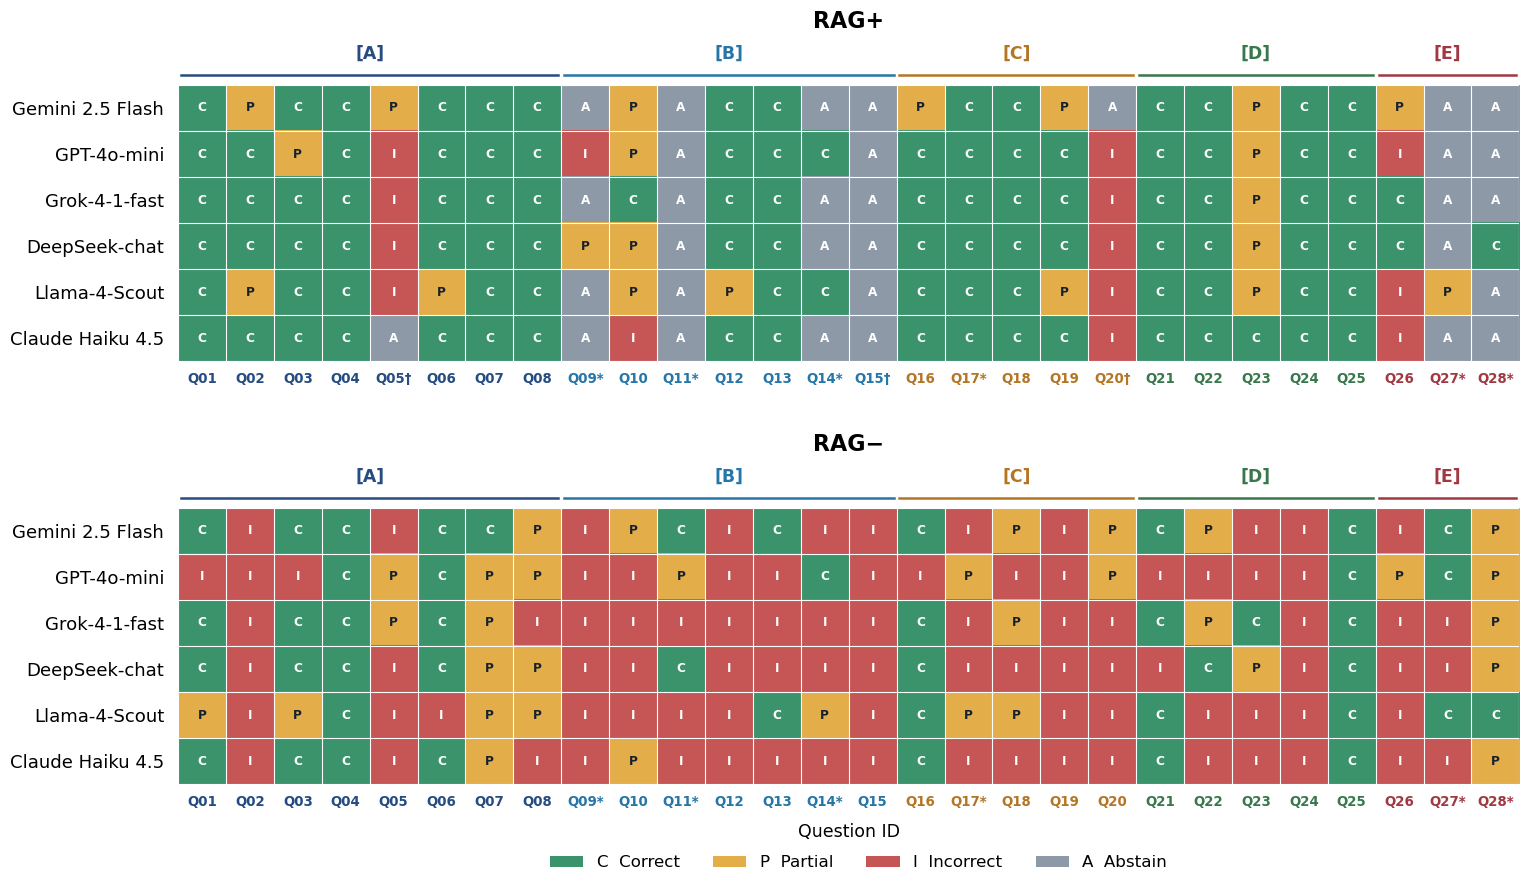

In [81]:
# Final Fig. 5 script (v7) shipped in this package: analysis/06_plot_fig5.py (this call originally ran an earlier version, v5)
%run "analysis/06_plot_fig5.py"